# Décodage d'erreurs quantiques par réseau de neurones sur graphes

**Projet.** Un ordinateur quantique protège son information avec un *code correcteur d'erreurs*. Un *décodeur* lit les contrôles du code et devine si l'information a été altérée. On compare deux décodeurs, sur des données **simulées** :

* **PyMatching**, décodeur classique qui connaît le modèle de bruit ;
* **un réseau de neurones sur graphes (GNN)**, qui apprend à partir d'exemples sans connaître ce modèle.

La question : *pour de petits codes (distances $d=3$ et $d=5$), quelle différence de taux d'erreur logique et de coût de calcul observe-t-on entre les deux ?*
On ne cherche pas à battre l'état de l'art : on veut une comparaison **propre, mesurée et reproductible**.

## Feuille de route

| Section | Contenu | État |
|---|---|---|
| 1 | Simuler les données avec Stim (circuit, tirages, coordonnées, types de stabilisateurs) | **fait** |
| **2** | Références : décodeur trivial et PyMatching, taux d'erreur logique, intervalles de confiance | **fait** |
| **3** | Construire les graphes (détecteurs activés + plus proches voisins) | **fait** |
| **4** | Le GNN : modèle, entraînement, validation | **fait** |
| 5 | Évaluation finale et comparaison (taux, coût de calcul) | à faire |
| 6 | Extensions optionnelles (autre taux de bruit, autre graphe) | à faire |

## Conventions de code (respectées dans tout le notebook)

1. **Toute fonction a une docstring** en trois parties : *Entrées* (nom, type, signification), *Sortie* (type, contenu), *Traitement* (ce que la fonction fait exactement).
2. **Toute fonction reste courte** (de l'ordre de 30 lignes au plus) ; sinon on la découpe en sous-fonctions.
3. **Aucun nombre « porteur de sens » écrit dans le corps d'une fonction.** Chaque paramètre a un nom en `MAJUSCULES`, défini avant les fonctions, avec un commentaire qui explique ce qu'il fait. Pour changer une valeur, on ne modifie qu'un seul endroit. (Seuls restent dans le code les nombres purement structurels : un axe `axis=1`, un indice `0`, etc.)
4. **Les graines aléatoires sont fixées** : relancer le notebook redonne exactement les mêmes résultats.

---
# 1. Simuler les données avec Stim

**Objectif de la section.** Fabriquer, sur ordinateur, des « exemples » pour entraîner puis tester les décodeurs. Un exemple (un *tirage*, en anglais *shot*) contient :

* le **syndrome** : la liste des détecteurs qui se sont activés ;
* le **bit logique de référence** (l'*observable*) : l'information protégée a-t-elle été altérée ?

Le décodeur ne voit que le syndrome et doit prédire le bit logique.

**Rappel de vocabulaire** (voir le plan de projet).

| Terme | Sens |
|---|---|
| Qubit physique / logique | Les vrais petits objets quantiques / le « super-qubit » protégé qu'ils forment ensemble |
| Cycle de mesure | Une série complète de contrôles sur tout le code |
| Détecteur | Comparaison de résultats de contrôle ; vaut 1 si une relation attendue est violée (« l'alarme sonne ») |
| Syndrome | Valeurs de tous les détecteurs pour un tirage |
| Observable logique | Bit qui dit si l'information protégée a été retournée par le bruit |
| Erreur logique | Après correction, l'information protégée est incorrecte |

Stim simule le circuit quantique **bruité** sans simuler un état quantique complet (il exploite le fait que ces circuits sont de type *Clifford*), ce qui est extrêmement rapide.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stim
from dataclasses import dataclass

## 1.1 Les paramètres de l'expérience

Toutes les valeurs choisies sont regroupées ci-dessous, chacune avec son rôle. On les modifie ici, et nulle part ailleurs.

* **`SURFACE_CODE_TASK`** : tâche Stim. `rotated_memory_z` est une *mémoire* de code de surface (« rotated » = géométrie compacte) qui protège un bit logique de type Z pendant plusieurs cycles. On fixe une seule tâche pour ne pas mélanger des observables différentes.
* **`CODE_DISTANCES`** : distances $d$ étudiées. Plus $d$ est grand, plus le code protège, mais plus il est gros.
* **`ROUNDS_PER_DISTANCE`** : nombre de cycles de mesure = distance × ce facteur (ici autant de cycles que la distance).
* **`NOISE_PROBABILITY`** : probabilité $p$ de bruit physique. À $p=0{,}005$ chaque opération a 0,5 % de chances d'être fautive.
* **`NOISE_PROBABILITIES_SWEEP`** : plusieurs valeurs de $p$ pour voir comment les données changent avec le bruit.
* **`RANDOM_SEED`** : graine de départ du générateur aléatoire.

In [2]:
# --- Choix de l'expérience simulée ---------------------------------------
# Tâche Stim : mémoire d'un code de surface « rotated », observable logique Z.
SURFACE_CODE_TASK = "surface_code:rotated_memory_z"
# Distances du code de surface étudiées (impaires).
CODE_DISTANCES = (3, 5)
# Nombre de cycles de mesure par unité de distance (cycles = d × ce facteur).
ROUNDS_PER_DISTANCE = 1
# Probabilité d'erreur physique p utilisée par défaut.
NOISE_PROBABILITY = 0.005
# Valeurs de p comparées dans le balayage de la section 1.8.
NOISE_PROBABILITIES_SWEEP = (0.001, 0.005, 0.01)
# Probabilité nulle : circuit sans aucun bruit (sert aux tests de cohérence).
NOISELESS_PROBABILITY = 0.0

# --- Simulation -----------------------------------------------------------
# Graine du générateur aléatoire (fixe pour que les résultats soient reproductibles).
RANDOM_SEED = 2026
# Nombre de tirages simulés pour explorer les données.
NUMBER_OF_SHOTS_PREVIEW = 20_000
# Nombre de tirages affichés en détail à l'écran.
NUMBER_OF_SHOTS_TO_PRINT = 5
# Nombre de tirages utilisés pour les tests de cohérence (petit : ils doivent être rapides).
NUMBER_OF_SHOTS_CHECK = 1_000

# --- Codage des types de stabilisateurs ----------------------------------
# Un détecteur est de type Z ou de type X (voir section 1.6) ; on les code par un entier.
STABILIZER_TYPE_Z = 0
STABILIZER_TYPE_X = 1
# Nom lisible de chaque type, pour les légendes de figures.
STABILIZER_TYPE_NAMES = {STABILIZER_TYPE_Z: "Z", STABILIZER_TYPE_X: "X"}
# Nombre de types de stabilisateurs (X et Z) ; sert à compter combien il y en a de chaque.
NUMBER_OF_STABILIZER_TYPES = 2

# --- Lecture des coordonnées de Stim -------------------------------------
# Un détecteur a trois coordonnées (x, y, t) ; voici leur position dans le tableau.
COORD_X, COORD_Y, COORD_TIME = 0, 1, 2
# Valeur de la coordonnée t de la toute première couche temporelle.
FIRST_TIME_LAYER = 0.0
# Préfixe des cibles de détecteurs dans Stim : le détecteur numéro 7 s'appelle « D7 ».
DETECTOR_TARGET_PREFIX = "D"
# Dans la disposition de Stim, un qubit de DONNÉES a des coordonnées x et y impaires
# (les qubits auxiliaires de mesure ont des coordonnées paires).
DATA_QUBIT_COORDINATE_PARITY = 1
COORDINATE_PARITY_MODULUS = 2
# Codes des opérateurs de Pauli dans Stim : 0 = identité (rien), 1 = X, 2 = Y, 3 = Z.
IDENTITY_PAULI_CODE = 0
PAULI_CODE_TO_LETTER = {1: "X", 2: "Y", 3: "Z"}
# Lien entre la lettre de Pauli lue sur les qubits de données et le type du stabilisateur.
LETTER_TO_STABILIZER_TYPE = {"Z": STABILIZER_TYPE_Z, "X": STABILIZER_TYPE_X}

# --- Statistiques et affichage -------------------------------------------
# Un syndrome « vide » est un syndrome où le nombre de détecteurs activés vaut 0.
NO_FIRED_DETECTOR = 0
# Pour convertir une fraction en pourcentage.
PERCENT = 100.0
# Demi-largeur d'une barre d'histogramme pour des valeurs entières (centre la barre sur l'entier).
HALF_BIN_WIDTH = 0.5
# Taille (largeur, hauteur) en pouces d'un panneau de la figure des couches temporelles.
LAYER_PANEL_SIZE = (2.6, 3.4)
# Taille (largeur, hauteur) de la figure des histogrammes.
HISTOGRAM_FIGURE_SIZE = (10, 3.4)
# Taille des points sur les figures de détecteurs.
MARKER_SIZE = 90
# Couleurs des deux types de stabilisateurs.
COLOR_BY_STABILIZER_TYPE = {STABILIZER_TYPE_Z: "tab:blue", STABILIZER_TYPE_X: "tab:orange"}
# Emplacement de la légende des figures.
LEGEND_LOCATION = "best"

## 1.2 Construire le circuit bruité

Un **circuit** est la liste, dans l'ordre, de toutes les opérations quantiques : préparer les qubits, faire les contrôles, mesurer. `stim.Circuit.generated` construit pour nous le circuit d'un code de surface, **avec le bruit** et **avec les annotations** qui définissent les détecteurs et l'observable logique.

Le bruit comporte ici quatre sources, toutes réglées à la même probabilité $p$ (c'est un choix simple et explicite, pas la seule définition possible du « bruit dépolarisant ») :

| Paramètre Stim | Effet |
|---|---|
| `after_clifford_depolarization` | après chaque porte, une erreur de Pauli $X$, $Y$ ou $Z$ avec probabilité $p$ au total |
| `before_round_data_depolarization` | avant chaque cycle, du bruit dépolarisant sur les qubits de données |
| `before_measure_flip_probability` | un résultat de mesure est inversé avec probabilité $p$ |
| `after_reset_flip_probability` | un qubit est préparé dans le mauvais état avec probabilité $p$ |

Remarque : les erreurs peuvent donc frapper **pendant** les contrôles, pas seulement sur les qubits de données ; c'est ce qu'on appelle un bruit *au niveau du circuit*.

In [3]:
def build_noisy_circuit(distance, noise_probability,
                        rounds_per_distance=ROUNDS_PER_DISTANCE,
                        task=SURFACE_CODE_TASK):
    """Construit le circuit Stim d'une mémoire de code de surface bruitée.

    Entrées :
        distance (int) : distance d du code de surface (impaire, ex. 3 ou 5).
        noise_probability (float) : probabilité p appliquée à chacune des
            quatre sources de bruit décrites dans la section 1.2.
        rounds_per_distance (int) : cycles de mesure par unité de distance ;
            le nombre total de cycles vaut distance × ce facteur.
        task (str) : nom de la tâche Stim à générer.
    Sortie :
        stim.Circuit : circuit complet (préparation, cycles de mesure, mesure
        finale) dont les détecteurs et l'observable logique sont annotés.
    Traitement :
        appelle `stim.Circuit.generated` en donnant la même probabilité aux
        quatre sources de bruit. Aucune simulation n'est faite ici : on décrit
        seulement le circuit.
    """
    return stim.Circuit.generated(
        task,
        distance=distance,
        rounds=distance * rounds_per_distance,
        after_clifford_depolarization=noise_probability,
        before_round_data_depolarization=noise_probability,
        before_measure_flip_probability=noise_probability,
        after_reset_flip_probability=noise_probability,
    )


def summarize_circuit(circuit):
    """Résume les dimensions d'un circuit Stim.

    Entrée :
        circuit (stim.Circuit) : circuit à décrire.
    Sortie :
        dict : nombre de qubits, de mesures, de détecteurs et d'observables
        logiques du circuit.
    Traitement :
        lit les compteurs fournis par Stim. Pour les qubits, on compte ceux qui
        ont des coordonnées (les vrais qubits du code) : `circuit.num_qubits`
        renverrait le plus grand indice + 1, qui inclut des indices inutilisés.
    """
    return {
        "qubits": len(circuit.get_final_qubit_coordinates()),
        "mesures": circuit.num_measurements,
        "détecteurs": circuit.num_detectors,
        "observables": circuit.num_observables,
    }

In [4]:
circuits_by_distance = {d: build_noisy_circuit(d, NOISE_PROBABILITY) for d in CODE_DISTANCES}
pd.DataFrame({d: summarize_circuit(c) for d, c in circuits_by_distance.items()}).rename_axis("distance d", axis=1)

distance d,3,5
qubits,17,49
mesures,33,145
détecteurs,24,120
observables,1,1


**Lecture du tableau.**

* **Qubits.** Pour $d=3$ : 17 qubits = 9 qubits de données ($d^2$) + 8 qubits auxiliaires qui servent aux mesures. Pour $d=5$ : 49 = 25 + 24. Ce sont les tailles du code de surface réalisé par Google Quantum AI (17 et 49 qubits, d'après Lange et al.), ce qui rend nos petits cas réalistes. *Attention :* l'attribut `circuit.num_qubits` de Stim renverrait 26 et 64, car il donne le plus grand indice de qubit + 1 et non le nombre de vrais qubits ; la fonction ci-dessus compte donc les qubits qui ont des coordonnées.
* **Détecteurs.** Il y en a plus que de contrôles par cycle, car on compare les cycles entre eux dans le temps (voir section 1.5).
* **Observables.** Il y en a **une seule** : on n'a donc qu'un seul bit à prédire, ce qui rend les calculs de taux d'erreur sans ambiguïté.

## 1.3 Un tirage : ce que contient un exemple

On demande à Stim de **simuler** le circuit un grand nombre de fois. Pour chaque tirage, le bruit tombe au hasard, et Stim nous rend :

* **`syndrome`** : tableau de booléens de forme *(nombre de tirages, nombre de détecteurs)*. `True` signifie « ce détecteur s'est activé » ;
* **`observables`** : tableau de forme *(nombre de tirages, nombre d'observables)* ; `True` signifie « l'information logique a été retournée par le bruit, il faudrait la corriger ».

> **Règle d'or.** `observables` est la *réponse*. Elle ne doit **jamais** être donnée en entrée à un décodeur (ni à PyMatching, ni au GNN) : ce serait tricher (fuite d'information). On la garde séparée du syndrome (`separate_observables=True`).

La **graine** (`seed`) rend la simulation reproductible : même graine, mêmes tirages.

In [5]:
def sample_shots(circuit, number_of_shots, seed):
    """Simule le circuit bruité et renvoie les syndromes et les bits logiques.

    Entrées :
        circuit (stim.Circuit) : circuit bruité à simuler.
        number_of_shots (int) : nombre de tirages indépendants.
        seed (int) : graine du générateur aléatoire de Stim.
    Sortie :
        tuple (syndrome, observables) :
          - syndrome (ndarray bool, forme (tirages, détecteurs)) : détecteurs
            activés ; c'est la SEULE information donnée aux décodeurs ;
          - observables (ndarray bool, forme (tirages, observables)) : bit
            logique de référence, utilisé uniquement pour entraîner (comme
            étiquette) et pour évaluer.
    Traitement :
        compile un échantillonneur de détecteurs de Stim avec la graine donnée,
        puis tire `number_of_shots` tirages en séparant les observables des
        détecteurs.
    """
    sampler = circuit.compile_detector_sampler(seed=seed)
    syndrome, observables = sampler.sample(number_of_shots, separate_observables=True)
    return syndrome, observables


def count_fired_detectors(syndrome):
    """Compte les détecteurs activés dans chaque tirage.

    Entrée :
        syndrome (ndarray bool, forme (tirages, détecteurs)) : syndromes.
    Sortie :
        ndarray int, forme (tirages,) : nombre de détecteurs activés par tirage.
    Traitement :
        somme les valeurs vraies le long de l'axe des détecteurs.
    """
    return syndrome.sum(axis=1)


def empty_syndrome_fraction(fired_counts):
    """Calcule la fraction de tirages où aucun détecteur ne s'est activé.

    Entrée :
        fired_counts (ndarray int) : nombre de détecteurs activés par tirage.
    Sortie :
        float entre 0 et 1 : proportion de syndromes vides.
    Traitement :
        compare chaque compte à NO_FIRED_DETECTOR et fait la moyenne.
    """
    return float(np.mean(fired_counts == NO_FIRED_DETECTOR))

In [6]:
def describe_first_shots(syndrome, observables, number_of_shots_to_show):
    """Affiche en clair les premiers tirages (détecteurs activés et bit logique).

    Entrées :
        syndrome (ndarray bool) : syndromes, forme (tirages, détecteurs).
        observables (ndarray bool) : bits logiques, forme (tirages, 1).
        number_of_shots_to_show (int) : nombre de tirages à afficher.
    Sortie :
        aucune (écrit à l'écran).
    Traitement :
        pour chaque tirage, retrouve les indices des détecteurs activés et
        les affiche avec la valeur du bit logique de référence.
    """
    for shot in range(number_of_shots_to_show):
        fired = np.flatnonzero(syndrome[shot])
        print(f"tirage {shot}: détecteurs activés = {fired.tolist()} | bit logique = {int(observables[shot, 0])}")


syndrome_d3, observables_d3 = sample_shots(circuits_by_distance[CODE_DISTANCES[0]], NUMBER_OF_SHOTS_PREVIEW, RANDOM_SEED)
print("forme du syndrome :", syndrome_d3.shape, "| forme des observables :", observables_d3.shape, "| type :", syndrome_d3.dtype)
describe_first_shots(syndrome_d3, observables_d3, NUMBER_OF_SHOTS_TO_PRINT)

forme du syndrome : (20000, 24) | forme des observables : (20000, 1) | type : bool
tirage 0: détecteurs activés = [19] | bit logique = 0
tirage 1: détecteurs activés = [15, 23] | bit logique = 0
tirage 2: détecteurs activés = [] | bit logique = 0
tirage 3: détecteurs activés = [14] | bit logique = 0
tirage 4: détecteurs activés = [10] | bit logique = 0


**Comment lire ces lignes.** Un tirage où la liste est `[]` est un **syndrome vide** : aucune alarme n'a sonné. Dans ce cas, aucun décodeur n'a d'information, et la réponse raisonnable est « pas de correction ».
Un tirage avec une liste non vide a des alarmes activées : **c'est de ces points que l'on fera des nœuds du graphe** (section 3).
Remarquez que le nombre de détecteurs activés varie d'un tirage à l'autre (0, 1, 2, ...). Une erreur physique isolée déclenche en général un petit nombre de détecteurs proches l'un de l'autre : deux dans le cœur du code, un seul quand l'erreur est près d'un bord (l'autre détecteur « sort » du code). Plusieurs erreurs dans un même tirage donnent plusieurs groupes. C'est cette structure **locale** qui donne du sens à un graphe de voisinage.

## 1.4 Combien de détecteurs s'activent-ils ?

Cette distribution nous renseigne sur la **forme des données** que le GNN devra traiter :

* beaucoup de tirages sans aucun détecteur activé : la donnée est **éparse** ;
* le **nombre de nœuds varie** d'un tirage à l'autre : un tableau de taille fixe n'est pas le format naturel, un graphe l'est.

In [7]:
def integer_bin_edges(max_value):
    """Calcule les bornes de barres d'histogramme centrées sur des entiers.

    Entrée :
        max_value (int) : plus grande valeur entière à représenter.
    Sortie :
        ndarray float : bornes -0,5 ; 0,5 ; 1,5 ; ... ; max_value + 0,5.
    Traitement :
        part de -HALF_BIN_WIDTH et avance de 1 jusqu'à dépasser max_value,
        ce qui centre chaque barre sur une valeur entière.
    """
    return np.arange(-HALF_BIN_WIDTH, max_value + 1)


def plot_fired_detector_histogram(axis, fired_counts, title):
    """Trace l'histogramme du nombre de détecteurs activés par tirage.

    Entrées :
        axis (matplotlib Axes) : zone de dessin à remplir.
        fired_counts (ndarray int) : nombre de détecteurs activés par tirage.
        title (str) : titre du graphique.
    Sortie :
        aucune (modifie `axis`).
    Traitement :
        dessine les proportions de tirages pour chaque nombre de détecteurs
        activés, avec une échelle logarithmique en ordonnée pour voir aussi
        les valeurs rares.
    """
    axis.hist(fired_counts, bins=integer_bin_edges(fired_counts.max()), density=True, log=True)
    axis.set_title(title)
    axis.set_xlabel("détecteurs activés dans un tirage")
    axis.set_ylabel("proportion de tirages")

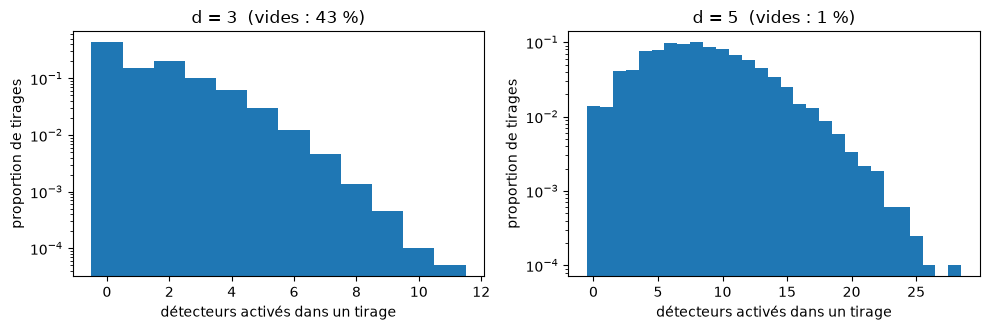

In [8]:
def plot_histograms_for_distances(circuits, number_of_shots, seed):
    """Trace côte à côte l'histogramme des détecteurs activés pour chaque distance.

    Entrées :
        circuits (dict) : distance -> circuit bruité.
        number_of_shots (int) : nombre de tirages simulés par distance.
        seed (int) : graine de la simulation.
    Sortie :
        matplotlib Figure : figure contenant un panneau par distance.
    Traitement :
        pour chaque distance, simule les tirages, compte les détecteurs
        activés, et délègue le tracé à `plot_fired_detector_histogram`.
    """
    figure, axes = plt.subplots(1, len(circuits), figsize=HISTOGRAM_FIGURE_SIZE)
    for axis, (distance, circuit) in zip(np.atleast_1d(axes), circuits.items()):
        syndrome, _ = sample_shots(circuit, number_of_shots, seed)
        counts = count_fired_detectors(syndrome)
        plot_fired_detector_histogram(axis, counts, f"d = {distance}  (vides : {PERCENT * empty_syndrome_fraction(counts):.0f} %)")
    figure.tight_layout()
    return figure


_ = plot_histograms_for_distances(circuits_by_distance, NUMBER_OF_SHOTS_PREVIEW, RANDOM_SEED)

**Lecture des histogrammes** (paramètres par défaut : $p = 0{,}005$, 20 000 tirages ; l'échelle verticale est logarithmique).

* Pour $d=3$, plus de **40 %** des tirages n'ont **aucun** détecteur activé, et la plupart des autres en ont peu (quelques-uns à une dizaine).
* Pour $d=5$, presque **plus aucun** tirage n'est vide (environ 1 %) : le code est plus gros, avec plus d'endroits où une erreur peut tomber, et le nombre de détecteurs activés atteint couramment la dizaine, avec une queue jusqu'à près de 30.

**Conséquence pour le GNN.** Les graphes à construire sont **petits et de taille très variable** : de 0 à quelques dizaines de nœuds. C'est la situation où une représentation en graphe est naturelle. Et à $d=5$, ces graphes sont plus riches (plus de nœuds, donc plus de voisinage à exploiter).

## 1.5 Où sont les détecteurs ? Les coordonnées $(x, y, t)$

Chaque détecteur a une position dans l'**espace-temps** :

* $(x, y)$ : où se trouve le contrôle sur le « damier » du code ;
* $t$ : à quel **couche temporelle** (cycle) il appartient.

Il y a $\text{cycles}+1$ couches : la première couche compare le premier résultat à ce que l'on sait de la préparation, les couches intermédiaires comparent deux cycles consécutifs, et la dernière compare le dernier cycle à la mesure finale des qubits de données.

Ces coordonnées seront les **attributs des nœuds** du graphe et serviront à définir la notion de « voisin » (section 3).

In [9]:
def get_detector_coordinates(circuit):
    """Lit les coordonnées (x, y, t) de tous les détecteurs d'un circuit.

    Entrée :
        circuit (stim.Circuit) : circuit dont les détecteurs sont annotés.
    Sortie :
        ndarray float, forme (nombre de détecteurs, 3) : ligne i = (x, y, t)
        du détecteur numéro i (colonnes COORD_X, COORD_Y, COORD_TIME).
    Traitement :
        demande à Stim le dictionnaire {indice du détecteur : coordonnées}
        et l'empile dans un tableau, dans l'ordre des indices.
    """
    coordinates_by_detector = circuit.get_detector_coordinates()
    rows = [coordinates_by_detector[index] for index in range(circuit.num_detectors)]
    return np.array(rows, dtype=float)


def count_detectors_per_layer(coordinates):
    """Compte combien de détecteurs appartiennent à chaque couche temporelle.

    Entrée :
        coordinates (ndarray, forme (détecteurs, 3)) : coordonnées (x, y, t).
    Sortie :
        dict : valeur de t -> nombre de détecteurs dans cette couche.
    Traitement :
        regroupe les détecteurs par valeur distincte de la coordonnée t.
    """
    layers, counts = np.unique(coordinates[:, COORD_TIME], return_counts=True)
    return {float(layer): int(count) for layer, count in zip(layers, counts)}

In [10]:
coordinates_by_distance = {d: get_detector_coordinates(c) for d, c in circuits_by_distance.items()}
for distance, coordinates in coordinates_by_distance.items():
    print(f"d = {distance} : détecteurs par couche temporelle t -> {count_detectors_per_layer(coordinates)}")

d = 3 : détecteurs par couche temporelle t -> {0.0: 4, 1.0: 8, 2.0: 8, 3.0: 4}
d = 5 : détecteurs par couche temporelle t -> {0.0: 12, 1.0: 24, 2.0: 24, 3.0: 24, 4.0: 24, 5.0: 12}


**Lecture.** Les couches intermédiaires contiennent **deux fois plus** de détecteurs que la première et la dernière. C'est un indice : à la première et à la dernière couche, seule **une moitié** des contrôles est « déterministe » et peut donc servir de détecteur. Cela nous conduit à la question suivante.

## 1.6 Le type de stabilisateur : $X$ ou $Z$ ?

Le code de surface utilise deux familles de contrôles : les stabilisateurs de type $Z$ (qui détectent les erreurs de bit, de type $X$) et ceux de type $X$ (qui détectent les erreurs de phase, de type $Z$). Pour le GNN, savoir à quelle famille appartient un détecteur est une information utile (c'est un attribut de nœud, comme dans Lange et al.). Mais **Stim ne la donne pas directement** : les coordonnées ne contiennent que $(x, y, t)$.

**Règle proposée (déduite des coordonnées).** Dans une mémoire de type $Z$, à la première couche seuls les contrôles de type $Z$ ont un résultat déterministe, donc seuls eux ont un détecteur. Un emplacement $(x, y)$ qui porte un détecteur à $t = 0$ est donc de type **Z** ; tous les autres emplacements sont de type **X**. Comme un contrôle reste au même emplacement à chaque cycle, le type d'un détecteur est celui de son emplacement.

**Il faut vérifier cette règle**, car elle repose sur un raisonnement. On utilise pour cela une méthode indépendante : Stim sait calculer, pour chaque détecteur, la « région de détection », c'est-à-dire l'opérateur de Pauli (X ou Z) que ce détecteur surveille sur chaque qubit à chaque instant.

> **Piège rencontré lors de la mise au point.** Un premier contrôle lisait la lettre de Pauli sur *tous* les qubits au *premier* instant : il signalait des désaccords sur 8 détecteurs sur 24 pour $d=3$ (et 48 sur 120 pour $d=5$). Le défaut venait du contrôle, pas de la règle : les qubits **auxiliaires** de mesure sont temporairement dans une autre base (à cause de portes de changement de base), ce qui fausse la lecture. Le contrôle correct ne regarde que les **qubits de données** et réunit les lettres sur **tous** les instants.

In [11]:
def infer_stabilizer_types(coordinates):
    """Déduit le type (Z ou X) de chaque détecteur à partir de ses coordonnées.

    Entrée :
        coordinates (ndarray float, forme (détecteurs, 3)) : coordonnées (x, y, t).
    Sortie :
        ndarray int, forme (détecteurs,) : STABILIZER_TYPE_Z ou STABILIZER_TYPE_X.
    Traitement :
        relève les emplacements (x, y) qui portent un détecteur à la première
        couche temporelle : ce sont les emplacements de type Z. Tout détecteur
        situé sur un tel emplacement est de type Z, les autres sont de type X.
    """
    on_first_layer = coordinates[:, COORD_TIME] == FIRST_TIME_LAYER
    z_locations = {position_key(row) for row in coordinates[on_first_layer]}
    types = np.full(len(coordinates), STABILIZER_TYPE_X, dtype=int)
    for index, row in enumerate(coordinates):
        if position_key(row) in z_locations:
            types[index] = STABILIZER_TYPE_Z
    return types


def position_key(row):
    """Renvoie l'emplacement (x, y) d'un détecteur sous forme de couple.

    Entrée :
        row (ndarray, longueur 3) : coordonnées (x, y, t) d'un détecteur.
    Sortie :
        tuple (float, float) : (x, y), utilisable comme clé d'ensemble.
    Traitement :
        extrait les colonnes COORD_X et COORD_Y et les convertit en flottants.
    """
    return (float(row[COORD_X]), float(row[COORD_Y]))

In [12]:
def coordinate_parity(value):
    """Donne la parité d'une coordonnée de qubit.

    Entrée :
        value (float) : coordonnée x ou y d'un qubit (valeur entière).
    Sortie :
        int : reste de la division de la coordonnée par COORDINATE_PARITY_MODULUS
        (1 si la coordonnée est impaire, 0 si elle est paire).
    Traitement :
        convertit la coordonnée en entier puis calcule le reste modulo 2.
    """
    return int(value) % COORDINATE_PARITY_MODULUS


def find_data_qubits(circuit):
    """Repère les indices des qubits de données d'un circuit Stim.

    Entrée :
        circuit (stim.Circuit) : circuit de code de surface.
    Sortie :
        list[int] : indices des qubits dont les coordonnées x et y sont
        impaires (disposition de Stim pour les qubits de données).
    Traitement :
        parcourt les coordonnées finales des qubits et garde ceux dont x et y
        ont la parité DATA_QUBIT_COORDINATE_PARITY.
    """
    return [qubit for qubit, position in circuit.get_final_qubit_coordinates().items()
            if coordinate_parity(position[COORD_X]) == DATA_QUBIT_COORDINATE_PARITY
            and coordinate_parity(position[COORD_Y]) == DATA_QUBIT_COORDINATE_PARITY]


def collect_data_qubit_letters(regions_by_tick, data_qubits):
    """Réunit les lettres de Pauli surveillées sur les qubits de données.

    Entrées :
        regions_by_tick (dict) : instant -> opérateur de Pauli (stim.PauliString)
            surveillé par un détecteur à cet instant.
        data_qubits (list[int]) : indices des qubits de données.
    Sortie :
        set[str] : lettres distinctes ("X", "Y", "Z") rencontrées sur les
        qubits de données, tous instants confondus.
    Traitement :
        pour chaque instant et chaque qubit de données, convertit le code de
        Pauli en lettre (en ignorant l'identité) et ajoute la lettre à l'ensemble.
    """
    letters = set()
    for pauli_string in regions_by_tick.values():
        for qubit in data_qubits:
            code = pauli_string[qubit]
            if code != IDENTITY_PAULI_CODE:
                letters.add(PAULI_CODE_TO_LETTER[code])
    return letters

In [13]:
def read_stabilizer_types_from_stim(circuit):
    """Lit le type de chaque détecteur avec la méthode indépendante de Stim.

    Entrée :
        circuit (stim.Circuit) : circuit de code de surface.
    Sortie :
        ndarray int, forme (détecteurs,) : STABILIZER_TYPE_Z ou STABILIZER_TYPE_X.
    Traitement :
        demande à Stim les « régions de détection » de tous les détecteurs,
        lit la lettre de Pauli surveillée sur les qubits de DONNÉES (tous
        instants confondus) et la convertit en type de stabilisateur. Une
        erreur est levée si la lettre n'est pas unique.
    """
    targets = [f"{DETECTOR_TARGET_PREFIX}{index}" for index in range(circuit.num_detectors)]
    regions = circuit.detecting_regions(targets=targets)
    data_qubits = find_data_qubits(circuit)
    types = np.zeros(circuit.num_detectors, dtype=int)
    for target, regions_by_tick in regions.items():
        letters = collect_data_qubit_letters(regions_by_tick, data_qubits)
        if len(letters) != 1:
            raise ValueError(f"lettre non unique pour {target}: {letters}")
        types[target.val] = LETTER_TO_STABILIZER_TYPE[letters.pop()]
    return types


def expected_detector_locations_per_type(distance):
    """Donne le nombre d'emplacements de contrôle de chaque type X et Z.

    Entrée :
        distance (int) : distance d du code de surface « rotated ».
    Sortie :
        int : (d² − 1) / 2, nombre de stabilisateurs de chaque type.
    Traitement :
        le code a d² − 1 stabilisateurs au total, répartis également entre
        les NUMBER_OF_STABILIZER_TYPES types.
    """
    return (distance * distance - 1) // NUMBER_OF_STABILIZER_TYPES

In [14]:
for distance, circuit in circuits_by_distance.items():
    inferred = infer_stabilizer_types(coordinates_by_distance[distance])
    from_stim = read_stabilizer_types_from_stim(circuit)
    disagreements = int(np.sum(inferred != from_stim))
    n_z_locations = len({position_key(r) for r, t in zip(coordinates_by_distance[distance], inferred) if t == STABILIZER_TYPE_Z})
    print(f"d = {distance} : désaccords règle/Stim = {disagreements} sur {len(inferred)} détecteurs ; "
          f"emplacements de type Z = {n_z_locations} (attendu {expected_detector_locations_per_type(distance)})")
    assert disagreements == 0, "la règle des coordonnées ne reproduit pas la lecture de Stim"

d = 3 : désaccords règle/Stim = 0 sur 24 détecteurs ; emplacements de type Z = 4 (attendu 4)
d = 5 : désaccords règle/Stim = 0 sur 120 détecteurs ; emplacements de type Z = 12 (attendu 12)


**Résultat.** La règle des coordonnées coïncide avec la lecture indépendante de Stim sur **tous** les détecteurs, pour $d=3$ et $d=5$, et le nombre d'emplacements de chaque type est bien $(d^2-1)/2$. On peut donc utiliser `infer_stabilizer_types` en confiance pour construire les attributs des nœuds.

**Visualisation.** Voici les détecteurs, couche temporelle par couche, colorés par type. On voit qu'à $t=0$ (et à la dernière couche) il n'y a que des détecteurs de type Z, et qu'entre les deux les deux types sont présents.

In [15]:
def draw_layer(axis, coordinates, stabilizer_types, time_value):
    """Dessine les détecteurs d'une couche temporelle, colorés par type.

    Entrées :
        axis (matplotlib Axes) : zone de dessin.
        coordinates (ndarray, forme (détecteurs, 3)) : coordonnées (x, y, t).
        stabilizer_types (ndarray int) : type de chaque détecteur.
        time_value (float) : valeur de t de la couche à dessiner.
    Sortie :
        aucune (modifie `axis`).
    Traitement :
        pour chaque type de stabilisateur, sélectionne les détecteurs de la
        couche et les trace comme des points de la couleur du type.
    """
    in_layer = coordinates[:, COORD_TIME] == time_value
    for type_code, color in COLOR_BY_STABILIZER_TYPE.items():
        selected = in_layer & (stabilizer_types == type_code)
        axis.scatter(coordinates[selected, COORD_X], coordinates[selected, COORD_Y],
                     s=MARKER_SIZE, c=color, label=STABILIZER_TYPE_NAMES[type_code])
    axis.set_title(f"t = {time_value:g}")
    axis.set_aspect("equal")


def plot_detector_layers(coordinates, stabilizer_types, title):
    """Trace toutes les couches temporelles de détecteurs côte à côte.

    Entrées :
        coordinates (ndarray, forme (détecteurs, 3)) : coordonnées (x, y, t).
        stabilizer_types (ndarray int) : type de chaque détecteur.
        title (str) : titre général de la figure.
    Sortie :
        matplotlib Figure : une rangée de panneaux, un par couche.
    Traitement :
        crée un panneau par valeur de t (axes partagés), appelle `draw_layer`
        pour chacun, et ajoute une légende unique dans le premier panneau.
    """
    time_values = np.unique(coordinates[:, COORD_TIME])
    width, height = LAYER_PANEL_SIZE
    figure, axes = plt.subplots(1, len(time_values), figsize=(width * len(time_values), height),
                                sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    for axis, time_value in zip(axes, time_values):
        draw_layer(axis, coordinates, stabilizer_types, time_value)
    axes[0].legend(loc=LEGEND_LOCATION, title="type")
    figure.suptitle(title)
    figure.tight_layout()
    return figure

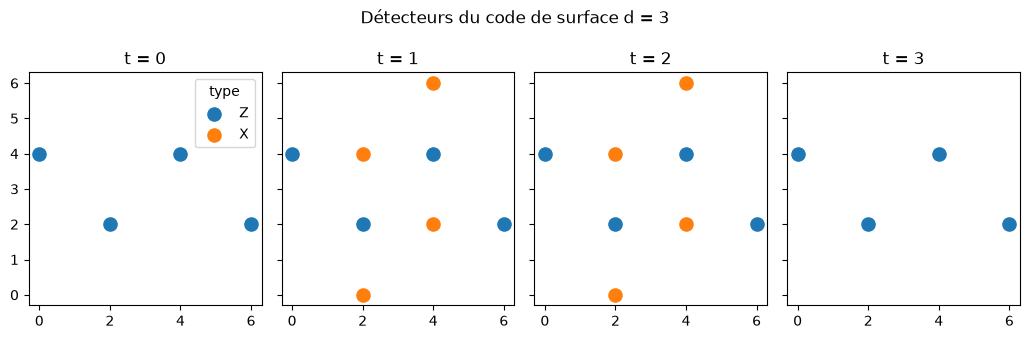

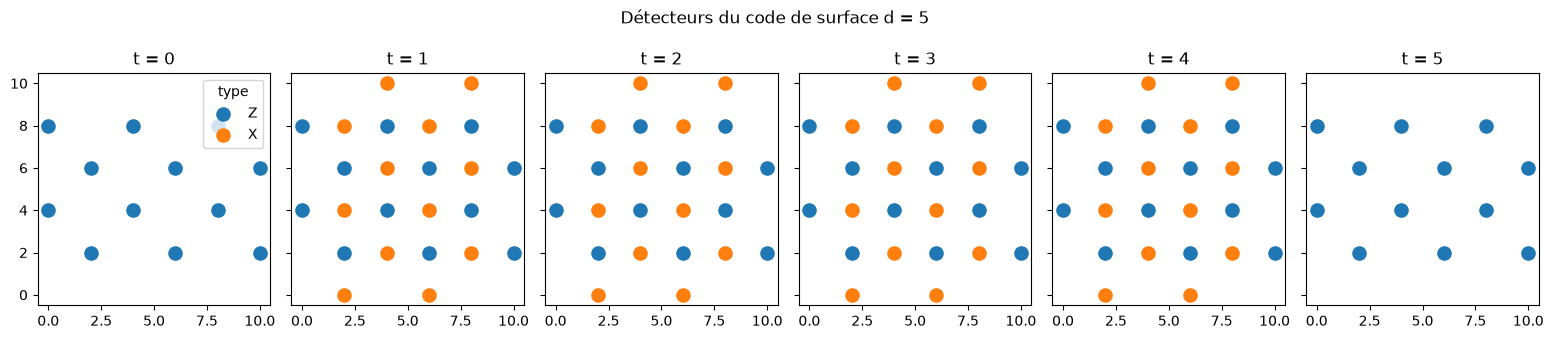

In [16]:
for distance in CODE_DISTANCES:
    types = infer_stabilizer_types(coordinates_by_distance[distance])
    _ = plot_detector_layers(coordinates_by_distance[distance], types, f"Détecteurs du code de surface d = {distance}")

## 1.7 Tests de cohérence

Avant de construire quoi que ce soit sur ces données, on vérifie trois propriétés. Un test qui échoue ici nous évitera de longues recherches d'erreurs plus tard.

1. **Sans bruit, rien ne se passe** : avec $p=0$, aucun détecteur ne s'active et le bit logique ne change jamais. Sinon, le circuit est mal construit.
2. **Reproductibilité** : deux simulations avec la même graine donnent exactement les mêmes tirages.
3. **Formes des tableaux** : une ligne par tirage, une colonne par détecteur (resp. par observable).

In [17]:
def check_noiseless_circuit(distance, number_of_shots, seed):
    """Vérifie qu'un circuit sans bruit ne produit aucun événement.

    Entrées :
        distance (int) : distance du code à tester.
        number_of_shots (int) : nombre de tirages simulés.
        seed (int) : graine de la simulation.
    Sortie :
        bool : vrai si aucun détecteur ne s'est activé et si le bit logique
        n'a jamais été retourné.
    Traitement :
        construit le circuit avec NOISELESS_PROBABILITY, le simule et teste
        que les deux tableaux ne contiennent aucune valeur vraie.
    """
    circuit = build_noisy_circuit(distance, NOISELESS_PROBABILITY)
    syndrome, observables = sample_shots(circuit, number_of_shots, seed)
    return not syndrome.any() and not observables.any()


def check_seed_reproducibility(circuit, number_of_shots, seed):
    """Vérifie que deux simulations avec la même graine sont identiques.

    Entrées :
        circuit (stim.Circuit) : circuit à simuler.
        number_of_shots (int) : nombre de tirages.
        seed (int) : graine commune aux deux simulations.
    Sortie :
        bool : vrai si syndromes et observables sont identiques dans les deux essais.
    Traitement :
        simule deux fois avec la même graine et compare les tableaux un à un.
    """
    first = sample_shots(circuit, number_of_shots, seed)
    second = sample_shots(circuit, number_of_shots, seed)
    return all(np.array_equal(a, b) for a, b in zip(first, second))


def check_sample_shapes(circuit, number_of_shots, seed):
    """Vérifie les formes des tableaux renvoyés par la simulation.

    Entrées :
        circuit (stim.Circuit) : circuit à simuler.
        number_of_shots (int) : nombre de tirages demandés.
        seed (int) : graine de la simulation.
    Sortie :
        bool : vrai si syndrome a pour forme (tirages, détecteurs) et
        observables (tirages, observables).
    Traitement :
        simule puis compare les formes aux valeurs attendues du circuit.
    """
    syndrome, observables = sample_shots(circuit, number_of_shots, seed)
    return (syndrome.shape == (number_of_shots, circuit.num_detectors)
            and observables.shape == (number_of_shots, circuit.num_observables))

In [18]:
for distance, circuit in circuits_by_distance.items():
    results = {
        "sans bruit : aucun événement": check_noiseless_circuit(distance, NUMBER_OF_SHOTS_CHECK, RANDOM_SEED),
        "même graine : mêmes tirages": check_seed_reproducibility(circuit, NUMBER_OF_SHOTS_CHECK, RANDOM_SEED),
        "formes des tableaux": check_sample_shapes(circuit, NUMBER_OF_SHOTS_CHECK, RANDOM_SEED),
    }
    for name, passed in results.items():
        print(f"d = {distance} | {name:<32} {'OK' if passed else 'ECHEC'}")
    assert all(results.values()), f"un test de cohérence a échoué pour d = {distance}"

d = 3 | sans bruit : aucun événement     OK
d = 3 | même graine : mêmes tirages      OK
d = 3 | formes des tableaux              OK
d = 5 | sans bruit : aucun événement     OK
d = 5 | même graine : mêmes tirages      OK
d = 5 | formes des tableaux              OK


## 1.8 Regrouper les données et explorer l'effet du bruit

Pour la suite, on regroupe tout ce qui décrit un jeu de données dans un seul objet : le circuit, les syndromes, les bits logiques, les coordonnées et les types de stabilisateurs. Ensuite, on fabrique un **tableau de bord** pour plusieurs niveaux de bruit.

Trois grandeurs nous intéressent :

* **Syndromes vides (%)** : part des tirages où rien ne s'active (cas où aucun décodeur n'a d'information).
* **Détecteurs activés (moyenne)** : taille moyenne des graphes que le GNN devra traiter.
* **Retournement logique (%)** : part des tirages où le bit logique est retourné par le bruit. C'est exactement le **taux d'erreur du décodeur trivial** qui ne corrige jamais ; tout vrai décodeur doit faire mieux. C'est notre premier point de repère.

In [19]:
@dataclass
class SimulatedDataset:
    """Jeu de données simulé pour une distance et un taux de bruit donnés.

    Attributs :
        distance (int) : distance du code de surface.
        noise_probability (float) : probabilité de bruit physique p.
        circuit (stim.Circuit) : circuit bruité ayant produit les données.
        syndrome (ndarray bool, forme (tirages, détecteurs)) : détecteurs
            activés ; seule entrée donnée aux décodeurs.
        observables (ndarray bool, forme (tirages, 1)) : bit logique de
            référence ; étiquette d'entraînement et d'évaluation uniquement.
        coordinates (ndarray float, forme (détecteurs, 3)) : coordonnées (x, y, t).
        stabilizer_types (ndarray int, forme (détecteurs,)) : type de chaque détecteur.
    """
    distance: int
    noise_probability: float
    circuit: stim.Circuit
    syndrome: np.ndarray
    observables: np.ndarray
    coordinates: np.ndarray
    stabilizer_types: np.ndarray


def generate_dataset(distance, noise_probability, number_of_shots, seed):
    """Fabrique un jeu de données complet pour une distance et un bruit donnés.

    Entrées :
        distance (int) : distance du code de surface.
        noise_probability (float) : probabilité de bruit physique p.
        number_of_shots (int) : nombre de tirages à simuler.
        seed (int) : graine de la simulation.
    Sortie :
        SimulatedDataset : circuit, tirages, coordonnées et types de détecteurs.
    Traitement :
        construit le circuit, simule les tirages, lit les coordonnées des
        détecteurs puis en déduit leur type de stabilisateur.
    """
    circuit = build_noisy_circuit(distance, noise_probability)
    syndrome, observables = sample_shots(circuit, number_of_shots, seed)
    coordinates = get_detector_coordinates(circuit)
    return SimulatedDataset(distance, noise_probability, circuit, syndrome, observables,
                            coordinates, infer_stabilizer_types(coordinates))

In [20]:
def flip_rate_among_empty_syndromes(dataset):
    """Mesure à quelle fréquence le bit logique est retourné malgré un syndrome vide.

    Entrée :
        dataset (SimulatedDataset) : jeu de données à analyser.
    Sortie :
        float entre 0 et 1 : proportion de tirages à syndrome vide dont le
        bit logique est retourné ; NaN si aucun tirage n'a un syndrome vide.
        Ces erreurs sont invisibles : aucun décodeur ne peut les corriger.
    Traitement :
        sélectionne les tirages sans détecteur activé et fait la moyenne de
        leur bit logique.
    """
    empty = count_fired_detectors(dataset.syndrome) == NO_FIRED_DETECTOR
    if not empty.any():
        return np.nan
    return float(dataset.observables[empty].mean())


def summarize_dataset(dataset):
    """Calcule les statistiques de base d'un jeu de données.

    Entrée :
        dataset (SimulatedDataset) : jeu de données à résumer.
    Sortie :
        dict : distance, p, nombre de tirages et de détecteurs, pourcentage
        de syndromes vides, nombre moyen de détecteurs activés, pourcentage
        de tirages où le bit logique est retourné (taux d'erreur du décodeur
        trivial qui ne corrige jamais), et pourcentage de retournements
        parmi les seuls syndromes vides.
    Traitement :
        compte les détecteurs activés par tirage puis calcule les moyennes.
    """
    fired = count_fired_detectors(dataset.syndrome)
    return {
        "d": dataset.distance,
        "p": dataset.noise_probability,
        "tirages": len(fired),
        "détecteurs": dataset.syndrome.shape[1],
        "syndromes vides (%)": PERCENT * empty_syndrome_fraction(fired),
        "détecteurs activés (moyenne)": float(fired.mean()),
        "retournement logique (%)": PERCENT * float(dataset.observables.mean()),
        "retournement parmi les vides (%)": PERCENT * flip_rate_among_empty_syndromes(dataset),
    }


def build_sweep_table(distances, noise_probabilities, number_of_shots, seed):
    """Construit le tableau de bord pour toutes les paires (d, p).

    Entrées :
        distances (iterable[int]) : distances à étudier.
        noise_probabilities (iterable[float]) : taux de bruit à étudier.
        number_of_shots (int) : tirages simulés par paire (d, p).
        seed (int) : graine de base ; chaque paire reçoit une graine décalée
            pour que les jeux de données soient indépendants.
    Sortie :
        pandas.DataFrame : une ligne par paire (d, p), colonnes de summarize_dataset.
    Traitement :
        génère chaque jeu de données, le résume, et empile les résumés.
    """
    rows = []
    for distance in distances:
        for noise_probability in noise_probabilities:
            dataset = generate_dataset(distance, noise_probability, number_of_shots, seed + len(rows))
            rows.append(summarize_dataset(dataset))
    return pd.DataFrame(rows)

In [21]:
sweep_table = build_sweep_table(CODE_DISTANCES, NOISE_PROBABILITIES_SWEEP, NUMBER_OF_SHOTS_PREVIEW, RANDOM_SEED)
sweep_table.style.format({"p": "{:.3f}", "syndromes vides (%)": "{:.1f}",
                          "détecteurs activés (moyenne)": "{:.2f}", "retournement logique (%)": "{:.2f}",
                          "retournement parmi les vides (%)": "{:.3f}"}).hide(axis="index")

d,p,tirages,détecteurs,syndromes vides (%),détecteurs activés (moyenne),retournement logique (%),retournement parmi les vides (%)
3,0.001,20000,24,84.8,0.28,2.23,0.000
3,0.005,20000,24,42.5,1.40,10.88,0.012
3,0.010,20000,24,18.1,2.65,18.59,0.000
5,0.001,20000,120,42.0,1.77,5.93,0.000
5,0.005,20000,120,1.4,8.31,22.96,0.000
5,0.010,20000,120,0.0,15.42,35.17,0.000


## 1.9 Ce que l'on retient du tableau

*(Chiffres obtenus avec les paramètres par défaut et 20 000 tirages par ligne ; si vous changez les paramètres, relisez le tableau ci-dessus plutôt que ces valeurs.)*

**1. Le décodeur trivial se détériore quand le code grossit.** La colonne « retournement logique » est le taux d'erreur d'un décodeur qui ne corrige **jamais**. À $p=0{,}005$ elle passe d'environ **11 %** pour $d=3$ à environ **23 %** pour $d=5$ : un code plus gros, avec plus de cycles, offre plus d'occasions au bruit de retourner le bit logique. Un vrai décodeur doit descendre **bien en dessous** de ces valeurs. La section 2 mesure exactement cela pour PyMatching.

**2. Les syndromes vides deviennent rares quand $d$ ou $p$ augmente.** À $p=0{,}005$ : environ 42 % de syndromes vides pour $d=3$, seulement 1,4 % pour $d=5$. À $p=0{,}01$ et $d=5$, quasiment aucun. Dans la dernière colonne, la proportion de retournements **parmi les syndromes vides** est nulle ou quasi nulle dans ce tableau : un tirage où aucune alarme n'a sonné laisse presque toujours le bit logique intact. Prédire « pas de retournement » pour un syndrome vide est donc, dans nos données, presque toujours correct (c'est aussi ce que fait PyMatching). *Limite :* avec 20 000 tirages, une fréquence très faible ne peut pas être mesurée avec précision ; on ne conclut que « très rare ».

**3. Les graphes sont petits mais plus riches avec $d$.** Nombre moyen de détecteurs activés : environ 1,4 pour $d=3$ et 8,3 pour $d=5$ à $p=0{,}005$ (jusqu'à 15 à $p=0{,}01$).

**4. Choix du bruit d'entraînement (provisoire).** À $p=0{,}001$, le signal est très rare (84,8 % de syndromes vides pour $d=3$, seulement 2,2 % de retournements) : un réseau y apprend difficilement, ce que signale aussi la littérature (Chamberland et Ronagh notent que l'entraînement à faible bruit est un défi). À $p=0{,}01$ le code de petite distance est dans un régime où le bruit est déjà très fort. On garde donc **$p=0{,}005$** comme valeur par défaut (`NOISE_PROBABILITY`), à confirmer sur la validation (section 4).

### Bilan de la section 1

| Livrable | Où |
|---|---|
| Circuit bruité $d=3$ et $d=5$, 4 sources de bruit documentées | `build_noisy_circuit` |
| Tirages (syndrome, bit logique) reproductibles à graine fixée | `sample_shots` |
| Coordonnées $(x, y, t)$ de chaque détecteur | `get_detector_coordinates` |
| Type $X$/$Z$ de chaque détecteur, **validé** par une méthode indépendante | `infer_stabilizer_types`, `read_stabilizer_types_from_stim` |
| 3 tests de cohérence réussis (sans bruit, graine, formes) | section 1.7 |
| Jeu de données regroupé et tableau de bord | `SimulatedDataset`, `build_sweep_table` |

**À retenir pour la suite :** (i) le bit logique n'est **jamais** donné en entrée d'un décodeur ; (ii) syndrome vide $\Rightarrow$ prédiction « pas de retournement » ; (iii) tous les jeux de données (entraînement, validation, test) devront avoir des **graines différentes** pour être indépendants.

**Section 2 :** le décodeur trivial et PyMatching sur les mêmes tirages, le taux d'erreur logique avec son intervalle de confiance, et la comparaison appariée.

---
# 2. Les références : décodeur trivial, PyMatching et règle de mesure

**Objectif de la section.** Avant d'entraîner le moindre réseau de neurones, on construit **la règle avec laquelle on mesurera tout le reste**. Un résultat de GNN n'a de sens que s'il est mesuré avec la même règle, sur les mêmes tirages, que celle appliquée à PyMatching. On construit donc :

1. une **interface commune** pour les décodeurs ;
2. deux décodeurs de référence : le **trivial** (borne haute) et **PyMatching** (référence classique) ;
3. le **taux d'erreur logique** avec son **intervalle de confiance** ;
4. un **plan de tailles d'échantillon** (combien de tirages pour une mesure fiable) ;
5. une **comparaison appariée** (même tirages, test statistique adapté) ;
6. des **tests de validité** de tout cela, puis les premières **courbes de référence**.

> **Pourquoi se donner autant de mal ?** Une erreur de mesure ici fausserait toutes les conclusions de la section 5. Mieux vaut un outil de mesure validé sur des cas où l'on connaît la réponse.

## 2.1 Les notions à fixer avant de coder

**Interface d'un décodeur.** Un décodeur est une fonction qui reçoit **uniquement** le syndrome (tableau booléen *tirages × détecteurs*) et renvoie une prédiction du bit logique (tableau booléen *tirages × observables*). Le GNN respectera la même interface : on pourra donc tout comparer avec les mêmes fonctions.

**Échec logique.** Pour un tirage, le décodeur *échoue* si sa prédiction diffère du bit logique de référence.

**Taux d'erreur logique** $p_L$ : fraction des tirages où le décodeur échoue,
$$\hat p_L=\frac{K}{N},\qquad K=\text{nombre d'échecs},\quad N=\text{nombre de tirages}.$$

**Intervalle de confiance.** $\hat p_L$ est une estimation : avec un autre échantillon on obtiendrait une valeur un peu différente. L'intervalle de Wilson à 95 % est une plage de valeurs telle que, si l'on répétait l'expérience de nombreuses fois, environ 95 % des intervalles construits ainsi contiendraient le vrai taux. Avec $z$ le quantile de la loi normale correspondant au niveau choisi (≈ 1,96 pour 95 %) :
$$\frac{\hat p_L+\frac{z^2}{2N}\;\pm\; z\sqrt{\frac{\hat p_L(1-\hat p_L)}{N}+\frac{z^2}{4N^2}}}{1+\frac{z^2}{N}}.$$
On l'utilise plutôt que l'approximation gaussienne usuelle, car il reste valable quand $K$ est petit ou nul.

**Zéro échec.** Si aucun échec n'est observé, le taux n'est pas « nul » : il est seulement *plus petit que ce que $N$ tirages permettent de voir*. La *règle de trois* donne une borne supérieure à 95 % d'environ $3/N$.

**Combien de tirages ?** L'incertitude relative d'un taux estimé vaut environ $1/\sqrt{K}$. Avec $K=100$ échecs, on est autour de 10 %. On vise donc **100 échecs par point**. Comme on ne connaît pas $p_L$ à l'avance, on fait d'abord un **pilote** (petit échantillon) pour estimer $p_L$, puis on en déduit $N\approx 100/\hat p_L$ (plafonné pour rester dans un temps raisonnable). Le pilote sert uniquement à fixer $N$ ; la mesure finale utilise d'autres tirages.

**Indépendance des jeux de données.** Les jeux d'entraînement, de validation, de test et de pilote doivent être indépendants : on leur donne des **plages de graines distinctes** (un million de graines chacune).

**Comparaison appariée.** Quand deux décodeurs sont évalués sur les *mêmes* tirages, on peut les comparer finement : on regarde les tirages **discordants** (l'un échoue et pas l'autre). Sous l'hypothèse « les deux décodeurs sont équivalents », chaque tirage discordant est équiprobable dans un sens ou dans l'autre ; un test binomial exact dit alors si l'écart observé est compatible avec le hasard. C'est bien plus sensible que de comparer deux intervalles de confiance.

In [22]:
from scipy.stats import binomtest, norm
import pymatching

In [23]:
# --- Statistiques ---------------------------------------------------------
# Niveau de confiance des intervalles (0,95 = 95 %).
CONFIDENCE_LEVEL = 0.95
# Méthode d'intervalle binomial utilisée par SciPy.
INTERVAL_METHOD = "wilson"
# Numérateur de la règle de trois : borne supérieure à 95 % ≈ 3 / N si aucun échec.
RULE_OF_THREE_NUMERATOR = 3.0
# Nombre d'échecs visé par point de mesure (incertitude relative ≈ 1/√K ≈ 10 %).
TARGET_NUMBER_OF_FAILURES = 100
# Plafond de tirages par point (pour garder un temps de calcul raisonnable).
MAX_SHOTS_PER_POINT = 5_000_000
# Nombre de tirages du pilote qui sert à estimer le taux avant la mesure finale.
PILOT_NUMBER_OF_SHOTS = 20_000
# Taille des paquets de tirages simulés puis décodés d'un coup (limite la mémoire).
SHOTS_PER_BATCH = 200_000
# Probabilité de tomber d'un côté ou de l'autre sous l'hypothèse « décodeurs équivalents ».
PAIRED_NULL_PROBABILITY = 0.5
# Tolérance numérique pour comparer deux nombres flottants dans les tests.
FLOAT_TOLERANCE = 1e-9
# Nombre de queues d'un intervalle de confiance bilatéral (basse et haute).
NUMBER_OF_TAILS = 2

# --- Graines : une plage distincte (un million) par usage ----------------
SEED_PILOT = 1_000_000
SEED_TRAIN = 2_000_000
SEED_VALIDATION = 3_000_000
SEED_TEST = 4_000_000
# Nombre de graines réservées à chaque point de mesure (≥ nombre maximal de paquets).
SEED_STRIDE_PER_POINT = 1_000
assert MAX_SHOTS_PER_POINT // SHOTS_PER_BATCH + 1 <= SEED_STRIDE_PER_POINT, "graines insuffisantes par point"

# --- Courbes de référence -------------------------------------------------
# Taux de bruit physique pour lesquels on trace les courbes de référence.
NOISE_PROBABILITIES_CURVES = (0.001, 0.002, 0.003, 0.005, 0.007, 0.01)
# Noms des deux décodeurs de référence (utilisés comme clés et dans les légendes).
DECODER_MATCHING = "PyMatching"
DECODER_TRIVIAL = "trivial (ne corrige jamais)"

# --- Illustration : modèle de bruit erroné donné à PyMatching ------------
# Facteurs multiplicatifs appliqués au vrai p pour fabriquer un modèle de bruit faux.
MODEL_NOISE_FACTORS = (0.01, 0.1, 10)
# Nombre de tirages communs pour cette illustration.
NUMBER_OF_SHOTS_MODEL_MISMATCH = 1_000_000

# --- Style des figures ----------------------------------------------------
CURVE_FIGURE_SIZE = (7.5, 5)
ERRORBAR_CAPSIZE = 3
# Transparence (0 = invisible, 1 = opaque) de la grille des figures.
GRID_TRANSPARENCY = 0.3
DISTANCE_COLORS = ("tab:blue", "tab:red", "tab:green")
DECODER_LINESTYLES = {DECODER_MATCHING: "-", DECODER_TRIVIAL: "--"}
CURVE_MARKER = "o"

## 2.2 Les deux décodeurs de référence

**Décodeur trivial.** Il ne regarde même pas le syndrome et prédit toujours « pas de retournement ». Son taux d'échec est donc exactement la proportion de tirages où le bit logique est retourné (la colonne « retournement logique » de la section 1). C'est la **borne haute** : tout décodeur utile doit faire mieux.

**PyMatching.** C'est un décodeur par **appariement de poids minimal** (*minimum-weight perfect matching*). Idée générale : chaque détecteur activé est « relié » à un autre (ou au bord du code) de façon à expliquer le syndrome par l'ensemble d'erreurs **le plus probable** parmi celles qu'il sait représenter.

Pour cela, PyMatching a besoin du **modèle de bruit** : le *detector error model* (DEM), que Stim calcule à partir du circuit. Le DEM liste les mécanismes de faute avec leur probabilité $q_e$, et le poids d'une arête est (selon la convention usuelle) $w_e=\log\frac{1-q_e}{q_e}$ : une faute rare coûte cher, une faute fréquente coûte peu.

> **Point crucial pour la suite.** PyMatching reçoit le **vrai** modèle de bruit (celui qui a généré les données). Le GNN, lui, ne le reçoit jamais : il doit le deviner à partir d'exemples. La comparaison est donc *volontairement favorable à PyMatching* ; la section 2.7 mesure à quel point ce modèle compte.

L'option `decompose_errors=True` demande à Stim de décomposer les mécanismes de faute en pièces qui déclenchent au plus deux détecteurs, pour pouvoir les représenter comme des arêtes d'un graphe. Les erreurs qui n'entrent pas dans ce cadre (par exemple certaines erreurs $Y$ qui touchent à la fois des détecteurs de type X et de type Z) sont donc traitées de façon approchée : c'est une limite connue du matching, et une raison pour laquelle un décodeur appris peut faire mieux.

In [24]:
def make_trivial_decoder(number_of_observables):
    """Fabrique le décodeur trivial, qui ne corrige jamais.

    Entrée :
        number_of_observables (int) : nombre de bits logiques à prédire.
    Sortie :
        fonction decode(syndrome) -> ndarray bool de forme
        (tirages, number_of_observables), toujours remplie de « faux ».
    Traitement :
        renvoie une fonction qui ignore le contenu du syndrome et prédit
        « pas de retournement » pour chaque tirage et chaque observable.
    """
    def decode(syndrome):
        """Prédit « aucun retournement logique » pour tous les tirages."""
        return np.zeros((len(syndrome), number_of_observables), dtype=bool)
    return decode


def make_matching_decoder(noise_model_circuit):
    """Fabrique un décodeur PyMatching à partir d'un modèle de bruit.

    Entrée :
        noise_model_circuit (stim.Circuit) : circuit dont le modèle d'erreur
            est donné à PyMatching. Pour la référence, c'est le circuit qui a
            généré les données ; pour tester un modèle faux, on passe un
            circuit construit avec une autre probabilité.
    Sortie :
        fonction decode(syndrome) -> ndarray bool de forme (tirages, observables).
    Traitement :
        calcule le modèle d'erreur de détecteurs (DEM) du circuit, construit
        le graphe d'appariement correspondant, et renvoie une fonction qui
        décode un lot de syndromes et convertit le résultat en booléens.
    """
    dem = noise_model_circuit.detector_error_model(decompose_errors=True)
    matching = pymatching.Matching.from_detector_error_model(dem)

    def decode(syndrome):
        """Décode un lot de syndromes avec l'appariement de poids minimal."""
        return matching.decode_batch(syndrome).astype(bool)
    return decode

In [25]:
# Premier contact : décoder le jeu de données de la section 1 (d = 3, p par défaut).
demo_dataset = generate_dataset(CODE_DISTANCES[0], NOISE_PROBABILITY, NUMBER_OF_SHOTS_PREVIEW, RANDOM_SEED)
trivial_decoder = make_trivial_decoder(demo_dataset.circuit.num_observables)
matching_decoder = make_matching_decoder(demo_dataset.circuit)
predictions = matching_decoder(demo_dataset.syndrome)
print("forme des prédictions PyMatching :", predictions.shape, "| type :", predictions.dtype)
print("premières prédictions :", predictions[:NUMBER_OF_SHOTS_TO_PRINT, 0].astype(int).tolist(),
      "| bits logiques réels :", demo_dataset.observables[:NUMBER_OF_SHOTS_TO_PRINT, 0].astype(int).tolist())

forme des prédictions PyMatching : (20000, 1) | type : bool
premières prédictions : [0, 0, 0, 0, 0] | bits logiques réels : [0, 0, 0, 0, 0]


## 2.3 Compter les échecs et mettre une incertitude dessus

Les fonctions ci-dessous sont volontairement **petites et testables** : compter les échecs tirage par tirage, estimer le taux avec son intervalle, calculer la borne « règle de trois », et choisir le nombre de tirages à partir du pilote.

On garde les échecs **tirage par tirage** (un tableau de booléens) plutôt qu'un simple total : c'est ce qui permettra la comparaison appariée de la section 2.7.

In [26]:
@dataclass
class FailureEstimate:
    """Estimation d'un taux d'erreur logique avec son intervalle de confiance.

    Attributs :
        failures (int) : nombre de tirages où le décodeur a échoué.
        shots (int) : nombre total de tirages.
        rate (float) : failures / shots.
        low (float) : borne basse de l'intervalle de confiance.
        high (float) : borne haute de l'intervalle de confiance.
    """
    failures: int
    shots: int
    rate: float
    low: float
    high: float


def per_shot_failures(predictions, observables):
    """Indique, tirage par tirage, si le décodeur s'est trompé.

    Entrées :
        predictions (ndarray bool, forme (tirages, observables)) : bits
            logiques prédits par le décodeur.
        observables (ndarray bool, même forme) : bits logiques de référence.
    Sortie :
        ndarray bool, forme (tirages,) : vrai si au moins un observable est
        mal prédit dans ce tirage.
    Traitement :
        compare terme à terme les deux tableaux et réduit sur l'axe des
        observables avec « au moins un désaccord ».
    """
    return np.any(predictions != observables, axis=1)


def estimate_failure_rate(failures, confidence=CONFIDENCE_LEVEL):
    """Estime le taux d'erreur logique et son intervalle de confiance.

    Entrées :
        failures (ndarray bool, forme (tirages,)) : échecs tirage par tirage.
        confidence (float) : niveau de confiance de l'intervalle.
    Sortie :
        FailureEstimate : nombre d'échecs, de tirages, taux, bornes.
    Traitement :
        compte les échecs, puis demande à SciPy l'intervalle binomial
        (méthode INTERVAL_METHOD) pour ce nombre d'échecs et de tirages.
    """
    shots, count = len(failures), int(failures.sum())
    interval = binomtest(count, shots).proportion_ci(confidence_level=confidence, method=INTERVAL_METHOD)
    return FailureEstimate(count, shots, count / shots, interval.low, interval.high)


def rule_of_three_upper_bound(shots):
    """Donne la borne supérieure approchée du taux quand aucun échec n'est vu.

    Entrée :
        shots (int) : nombre de tirages sans aucun échec.
    Sortie :
        float : RULE_OF_THREE_NUMERATOR / shots (borne à environ 95 %).
    Traitement :
        applique la « règle de trois ».
    """
    return RULE_OF_THREE_NUMERATOR / shots


def plan_number_of_shots(pilot_rate, target_failures, max_shots):
    """Choisit le nombre de tirages pour observer environ target_failures échecs.

    Entrées :
        pilot_rate (float) : taux d'échec estimé sur le pilote.
        target_failures (int) : nombre d'échecs visé.
        max_shots (int) : plafond de tirages.
    Sortie :
        int : target_failures / pilot_rate arrondi à l'entier supérieur, sans
        dépasser max_shots (c'est max_shots si le pilote n'a vu aucun échec).
    Traitement :
        divise la cible par le taux du pilote puis applique le plafond.
    """
    if pilot_rate <= 0:
        return max_shots
    return int(min(np.ceil(target_failures / pilot_rate), max_shots))

## 2.4 Évaluer des décodeurs sur les mêmes tirages, par paquets

Simuler 5 millions de tirages d'un coup tiendrait mal en mémoire : on les traite par **paquets** (`SHOTS_PER_BATCH`). Chaque paquet reçoit sa propre graine (`graine de base + numéro de paquet`), donc :

* le résultat est **reproductible** ;
* **tous les décodeurs voient exactement les mêmes tirages** (la fonction décode chaque paquet avec tous les décodeurs avant de passer au suivant), ce qui rend la comparaison appariée possible.

In [27]:
def split_into_batches(total_shots, shots_per_batch):
    """Découpe un nombre de tirages en paquets de taille bornée.

    Entrées :
        total_shots (int) : nombre total de tirages.
        shots_per_batch (int) : taille maximale d'un paquet.
    Sortie :
        list[int] : tailles des paquets ; leur somme vaut total_shots.
    Traitement :
        autant de paquets pleins que possible, puis un dernier paquet avec le reste.
    """
    full_batches, remainder = divmod(total_shots, shots_per_batch)
    return [shots_per_batch] * full_batches + ([remainder] if remainder else [])


def evaluate_decoders(decoders, circuit, number_of_shots, base_seed,
                      shots_per_batch=SHOTS_PER_BATCH):
    """Évalue plusieurs décodeurs sur exactement les mêmes tirages simulés.

    Entrées :
        decoders (dict) : nom du décodeur -> fonction decode(syndrome).
        circuit (stim.Circuit) : circuit bruité qui génère les tirages.
        number_of_shots (int) : nombre total de tirages.
        base_seed (int) : graine du premier paquet ; le paquet k utilise
            base_seed + k.
        shots_per_batch (int) : taille maximale d'un paquet.
    Sortie :
        dict : nom du décodeur -> ndarray bool de forme (number_of_shots,),
        vrai là où ce décodeur échoue. Les tableaux sont alignés tirage par tirage.
    Traitement :
        pour chaque paquet, simule les tirages, fait décoder le syndrome par
        chaque décodeur, compare à l'observable de référence, puis
        concatène les résultats de tous les paquets.
    """
    parts = {name: [] for name in decoders}
    for batch_index, batch_shots in enumerate(split_into_batches(number_of_shots, shots_per_batch)):
        syndrome, observables = sample_shots(circuit, batch_shots, base_seed + batch_index)
        for name, decoder in decoders.items():
            parts[name].append(per_shot_failures(decoder(syndrome), observables))
    return {name: np.concatenate(chunks) for name, chunks in parts.items()}

## 2.5 Tests de validité de l'outil de mesure

On vérifie les outils sur des cas où **la bonne réponse est connue d'avance**. Un test qui échouerait ici signalerait une erreur dans la règle de mesure, bien avant qu'elle ne fausse un résultat.

| Test | Réponse attendue |
|---|---|
| Compteur d'échecs sur des prédictions parfaites, puis toutes fausses | 0 échec, puis 100 % d'échecs |
| Le décodeur trivial | taux d'échec = proportion de bits logiques retournés (section 1) |
| Intervalle de Wilson sans aucun échec | borne haute = $z^2/(N+z^2)$ (formule exacte, calculée indépendamment) |
| PyMatching sans bruit ($p=0$) | aucun échec |
| Deux décodeurs identiques, comparaison appariée | aucun tirage discordant, valeur $p = 1$ |
| Découpage en paquets | tailles correctes, somme = total |
| Évaluation répétée avec les mêmes graines | résultats identiques |

La comparaison appariée est définie juste avant (fonction `paired_failure_comparison`).

In [28]:
def paired_failure_comparison(failures_a, failures_b):
    """Compare deux décodeurs évalués sur les mêmes tirages.

    Entrées :
        failures_a (ndarray bool, forme (tirages,)) : échecs du décodeur A.
        failures_b (ndarray bool, même forme) : échecs du décodeur B,
            sur exactement les mêmes tirages.
    Sortie :
        dict : « seulement A » et « seulement B » (nombres de tirages où un
        seul des deux échoue) et « valeur p » du test binomial exact.
    Traitement :
        compte les tirages discordants dans chaque sens ; sous l'hypothèse
        « décodeurs équivalents » le nombre « seulement A » suit une loi
        binomiale de probabilité PAIRED_NULL_PROBABILITY sur le total des
        discordants. S'il n'y a aucun tirage discordant, la valeur p vaut 1.
    """
    only_a = int(np.sum(failures_a & ~failures_b))
    only_b = int(np.sum(failures_b & ~failures_a))
    discordant = only_a + only_b
    p_value = 1.0 if discordant == 0 else binomtest(only_a, discordant, PAIRED_NULL_PROBABILITY).pvalue
    return {"seulement A": only_a, "seulement B": only_b, "valeur p": float(p_value)}

In [29]:
def check_failure_counter():
    """Teste le compteur d'échecs sur des prédictions parfaites puis toutes fausses.

    Entrée :
        aucune.
    Sortie :
        bool : vrai si le compteur ne signale aucun échec pour des prédictions
        parfaites et signale un échec à chaque tirage pour des prédictions inversées.
    Traitement :
        fabrique un petit tableau de bits logiques, le compare à lui-même puis
        à son contraire.
    """
    reference = np.array([[True], [False], [True], [False]])
    return (not per_shot_failures(reference, reference).any()
            and per_shot_failures(~reference, reference).all())


def check_trivial_decoder(dataset):
    """Teste que le décodeur trivial échoue exactement quand le bit logique est retourné.

    Entrée :
        dataset (SimulatedDataset) : jeu de données de la section 1.
    Sortie :
        bool : vrai si le taux d'échec du trivial égale la moyenne des bits logiques.
    Traitement :
        décode avec le trivial, compte les échecs et compare à observables.mean().
    """
    decoder = make_trivial_decoder(dataset.circuit.num_observables)
    failures = per_shot_failures(decoder(dataset.syndrome), dataset.observables)
    return abs(failures.mean() - dataset.observables.mean()) < FLOAT_TOLERANCE


def check_wilson_without_failure(shots):
    """Teste la borne haute de Wilson quand aucun échec n'est observé.

    Entrée :
        shots (int) : nombre de tirages, tous réussis.
    Sortie :
        bool : vrai si la borne haute calculée par SciPy égale z² / (N + z²),
        avec z le quantile normal du niveau de confiance.
    Traitement :
        calcule l'estimation avec zéro échec, puis compare sa borne haute à
        la formule exacte du cas sans échec.
    """
    estimate = estimate_failure_rate(np.zeros(shots, dtype=bool))
    z = norm.ppf(1 - (1 - CONFIDENCE_LEVEL) / NUMBER_OF_TAILS)
    return abs(estimate.high - z * z / (shots + z * z)) < FLOAT_TOLERANCE


def check_noiseless_matching(distance, number_of_shots, seed):
    """Teste que PyMatching ne se trompe jamais quand il n'y a pas de bruit.

    Entrées :
        distance (int) : distance du code.
        number_of_shots (int) : nombre de tirages.
        seed (int) : graine de la simulation.
    Sortie :
        bool : vrai si aucun échec n'est observé.
    Traitement :
        construit un circuit sans bruit, évalue PyMatching dessus, compte les échecs.
    """
    circuit = build_noisy_circuit(distance, NOISELESS_PROBABILITY)
    decoders = {DECODER_MATCHING: make_matching_decoder(circuit)}
    return not evaluate_decoders(decoders, circuit, number_of_shots, seed)[DECODER_MATCHING].any()

In [30]:
def check_identical_decoders_paired(failures):
    """Teste la comparaison appariée d'un décodeur avec lui-même.

    Entrée :
        failures (ndarray bool) : échecs d'un décodeur, tirage par tirage.
    Sortie :
        bool : vrai s'il n'y a aucun tirage discordant et si la valeur p vaut 1.
    Traitement :
        compare le tableau d'échecs à une copie de lui-même.
    """
    result = paired_failure_comparison(failures, failures.copy())
    return result["seulement A"] == 0 and result["seulement B"] == 0 and result["valeur p"] == 1.0


def check_batch_splitting(total_shots, shots_per_batch):
    """Teste que le découpage en paquets est correct.

    Entrées :
        total_shots (int) : nombre total de tirages.
        shots_per_batch (int) : taille maximale des paquets.
    Sortie :
        bool : vrai si la somme des paquets vaut total_shots et si aucun
        paquet ne dépasse shots_per_batch.
    Traitement :
        découpe puis vérifie les deux propriétés.
    """
    batches = split_into_batches(total_shots, shots_per_batch)
    return sum(batches) == total_shots and max(batches) <= shots_per_batch


def check_evaluation_is_reproducible(circuit, number_of_shots, seed):
    """Teste que deux évaluations avec les mêmes graines donnent les mêmes échecs.

    Entrées :
        circuit (stim.Circuit) : circuit bruité.
        number_of_shots (int) : nombre de tirages.
        seed (int) : graine de base.
    Sortie :
        bool : vrai si les deux évaluations donnent des tableaux identiques.
    Traitement :
        évalue deux fois PyMatching avec les mêmes paramètres et compare.
    """
    decoders = {DECODER_MATCHING: make_matching_decoder(circuit)}
    first = evaluate_decoders(decoders, circuit, number_of_shots, seed)[DECODER_MATCHING]
    second = evaluate_decoders(decoders, circuit, number_of_shots, seed)[DECODER_MATCHING]
    return bool(np.array_equal(first, second))

In [31]:
distance_check = CODE_DISTANCES[0]
circuit_check = demo_dataset.circuit
failures_check = evaluate_decoders({DECODER_MATCHING: matching_decoder}, circuit_check,
                                   NUMBER_OF_SHOTS_CHECK, SEED_TEST)[DECODER_MATCHING]
validation_results = {
    "compteur d'échecs (parfait puis inversé)": check_failure_counter(),
    "décodeur trivial = taux de retournement": check_trivial_decoder(demo_dataset),
    "Wilson sans échec = formule exacte": check_wilson_without_failure(NUMBER_OF_SHOTS_CHECK),
    "PyMatching sans bruit : aucun échec": check_noiseless_matching(distance_check, NUMBER_OF_SHOTS_CHECK, SEED_TEST),
    "comparaison appariée d'un décodeur avec lui-même": check_identical_decoders_paired(failures_check),
    "découpage en paquets": check_batch_splitting(NUMBER_OF_SHOTS_PREVIEW, SHOTS_PER_BATCH),
    "évaluation reproductible (mêmes graines)": check_evaluation_is_reproducible(circuit_check, NUMBER_OF_SHOTS_CHECK, SEED_TEST),
}
for name, passed in validation_results.items():
    print(f"{name:<52} {'OK' if passed else 'ECHEC'}")
assert all(validation_results.values()), "un test de validité a échoué"

# Pour mémoire : avec zéro échec, la borne de Wilson et la règle de trois sont du même ordre.
zero_estimate = estimate_failure_rate(np.zeros(NUMBER_OF_SHOTS_CHECK, dtype=bool))
print(f"\nzéro échec sur {NUMBER_OF_SHOTS_CHECK} tirages : borne haute de Wilson = {zero_estimate.high:.5f}, "
      f"règle de trois = {rule_of_three_upper_bound(NUMBER_OF_SHOTS_CHECK):.5f}")

compteur d'échecs (parfait puis inversé)             OK
décodeur trivial = taux de retournement              OK
Wilson sans échec = formule exacte                   OK
PyMatching sans bruit : aucun échec                  OK
comparaison appariée d'un décodeur avec lui-même     OK
découpage en paquets                                 OK
évaluation reproductible (mêmes graines)             OK

zéro échec sur 1000 tirages : borne haute de Wilson = 0.00383, règle de trois = 0.00300


## 2.6 Premières courbes de référence : taux d'erreur logique en fonction du bruit

Pour chaque distance $d$ et chaque taux de bruit $p$, on :

1. fait un **pilote** de `PILOT_NUMBER_OF_SHOTS` tirages pour estimer le taux de PyMatching ;
2. en déduit le **nombre de tirages** pour viser `TARGET_NUMBER_OF_FAILURES` échecs ;
3. évalue **PyMatching et le décodeur trivial sur les mêmes tirages** ;
4. calcule les taux et leurs intervalles de confiance.

Le résultat est le **tableau de référence** auquel on comparera le GNN. Le calcul prend quelques dizaines de secondes.

In [32]:
def pilot_failure_rate(decoder, circuit, seed):
    """Estime rapidement le taux d'échec d'un décodeur sur un petit échantillon.

    Entrées :
        decoder (fonction) : décodeur à tester.
        circuit (stim.Circuit) : circuit bruité.
        seed (int) : graine du pilote (distincte de celle de la mesure finale).
    Sortie :
        float : taux d'échec observé sur PILOT_NUMBER_OF_SHOTS tirages.
    Traitement :
        évalue le décodeur sur le pilote et renvoie la proportion d'échecs.
    """
    failures = evaluate_decoders({"pilote": decoder}, circuit, PILOT_NUMBER_OF_SHOTS, seed)["pilote"]
    return float(failures.mean())


def make_table_rows(distance, noise_probability, failures_by_decoder):
    """Met en forme les résultats d'un point (d, p) pour le tableau de référence.

    Entrées :
        distance (int) : distance du code.
        noise_probability (float) : taux de bruit p.
        failures_by_decoder (dict) : nom du décodeur -> échecs tirage par tirage.
    Sortie :
        list[dict] : une ligne par décodeur (d, p, décodeur, échecs, tirages,
        taux, bornes de l'intervalle de confiance).
    Traitement :
        estime le taux et l'intervalle de chaque décodeur.
    """
    rows = []
    for name, failures in failures_by_decoder.items():
        estimate = estimate_failure_rate(failures)
        rows.append({"d": distance, "p": noise_probability, "décodeur": name,
                     "échecs": estimate.failures, "tirages": estimate.shots,
                     "taux": estimate.rate, "bas": estimate.low, "haut": estimate.high})
    return rows


def evaluate_reference_point(distance, noise_probability, point_index):
    """Mesure les deux décodeurs de référence en un point (d, p).

    Entrées :
        distance (int) : distance du code.
        noise_probability (float) : taux de bruit p.
        point_index (int) : numéro du point ; sert à décaler les graines pour
            que chaque point ait ses propres tirages.
    Sortie :
        list[dict] : lignes du tableau de référence (voir make_table_rows).
    Traitement :
        construit circuit et décodeurs, fait le pilote, choisit le nombre de
        tirages, puis évalue les deux décodeurs sur les mêmes tirages.
    """
    circuit = build_noisy_circuit(distance, noise_probability)
    decoders = {DECODER_MATCHING: make_matching_decoder(circuit),
                DECODER_TRIVIAL: make_trivial_decoder(circuit.num_observables)}
    pilot_rate = pilot_failure_rate(decoders[DECODER_MATCHING], circuit, SEED_PILOT + point_index)
    shots = plan_number_of_shots(pilot_rate, TARGET_NUMBER_OF_FAILURES, MAX_SHOTS_PER_POINT)
    seed = SEED_TEST + point_index * SEED_STRIDE_PER_POINT
    return make_table_rows(distance, noise_probability, evaluate_decoders(decoders, circuit, shots, seed))


def build_reference_table(distances, noise_probabilities):
    """Construit le tableau de référence pour toutes les paires (d, p).

    Entrées :
        distances (iterable[int]) : distances à étudier.
        noise_probabilities (iterable[float]) : taux de bruit à étudier.
    Sortie :
        pandas.DataFrame : une ligne par (d, p, décodeur).
    Traitement :
        évalue chaque point avec un numéro distinct et empile les lignes.
    """
    rows = []
    for distance in distances:
        for noise_probability in noise_probabilities:
            rows += evaluate_reference_point(distance, noise_probability, point_index=len(rows))
    return pd.DataFrame(rows)

In [33]:
reference_table = build_reference_table(CODE_DISTANCES, NOISE_PROBABILITIES_CURVES)
reference_table[reference_table["décodeur"] == DECODER_MATCHING].style.format(
    {"p": "{:.3f}", "taux": "{:.2e}", "bas": "{:.2e}", "haut": "{:.2e}"}).hide(axis="index")

d,p,décodeur,échecs,tirages,taux,bas,haut
3,0.001,PyMatching,111,153847,7.21e-04,5.99e-04,8.69e-04
3,0.002,PyMatching,99,32259,3.07e-03,2.52e-03,3.73e-03
3,0.003,PyMatching,99,14815,6.68e-03,5.49e-03,8.13e-03
3,0.005,PyMatching,118,6431,1.83e-02,1.53e-02,2.19e-02
3,0.007,PyMatching,87,3045,2.86e-02,2.32e-02,3.51e-02
3,0.010,PyMatching,112,1723,6.50e-02,5.43e-02,7.76e-02
5,0.001,PyMatching,67,400000,1.68e-04,1.32e-04,2.13e-04
5,0.002,PyMatching,97,83334,1.16e-03,9.54e-04,1.42e-03
5,0.003,PyMatching,107,28170,3.80e-03,3.14e-03,4.59e-03
5,0.005,PyMatching,106,7221,1.47e-02,1.22e-02,1.77e-02


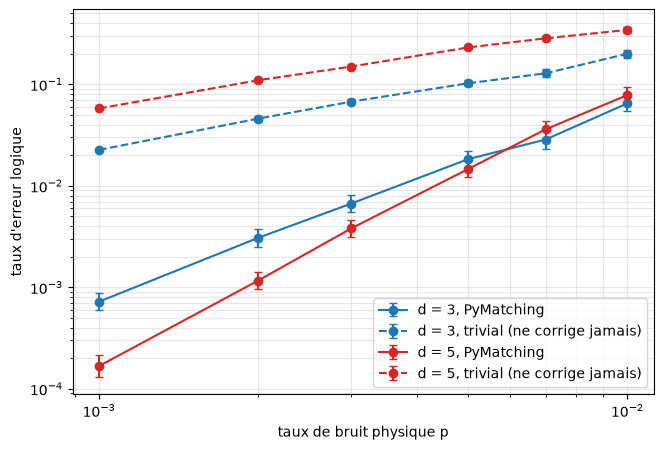

In [34]:
def plot_error_curves(table):
    """Trace le taux d'erreur logique en fonction du bruit, avec barres d'erreur.

    Entrée :
        table (pandas.DataFrame) : tableau de référence (colonnes d, p,
            décodeur, taux, bas, haut).
    Sortie :
        matplotlib Figure : courbes log-log, une couleur par distance et un
        style de trait par décodeur.
    Traitement :
        pour chaque distance et chaque décodeur, trace les taux avec des
        barres d'erreur asymétriques (bornes de Wilson) ; échelles logarithmiques.
    """
    figure, axis = plt.subplots(figsize=CURVE_FIGURE_SIZE)
    for color, distance in zip(DISTANCE_COLORS, sorted(table["d"].unique())):
        for decoder, linestyle in DECODER_LINESTYLES.items():
            subset = table[(table["d"] == distance) & (table["décodeur"] == decoder)]
            errors = [subset["taux"] - subset["bas"], subset["haut"] - subset["taux"]]
            axis.errorbar(subset["p"], subset["taux"], yerr=errors, color=color, linestyle=linestyle,
                          marker=CURVE_MARKER, capsize=ERRORBAR_CAPSIZE, label=f"d = {distance}, {decoder}")
    axis.set_xscale("log"); axis.set_yscale("log")
    axis.set_xlabel("taux de bruit physique p"); axis.set_ylabel("taux d'erreur logique")
    axis.legend(); axis.grid(True, which="both", alpha=GRID_TRANSPARENCY)
    return figure


_ = plot_error_curves(reference_table)

**Deux vues complémentaires du même tableau.** D'abord les taux des deux décodeurs côte à côte. Ensuite, la liste des points qui n'ont **pas atteint** la cible de 100 échecs : le pilote ne fait qu'une estimation approximative du taux, donc le nombre de tirages choisi peut être un peu trop juste. Ce n'est pas une erreur, mais l'intervalle de confiance de ces points est un peu plus large que prévu.

In [35]:
reference_pivot = reference_table.pivot_table(index="p", columns=["d", "décodeur"], values="taux")
display(reference_pivot.style.format("{:.2e}"))
below_target = reference_table[(reference_table["décodeur"] == DECODER_MATCHING)
                               & (reference_table["échecs"] < TARGET_NUMBER_OF_FAILURES)]
print(f"Points PyMatching sous la cible de {TARGET_NUMBER_OF_FAILURES} échecs :")
print(below_target[["d", "p", "échecs", "tirages"]].to_string(index=False))

Points PyMatching sous la cible de 100 échecs :
 d     p  échecs  tirages
 3 0.002      99    32259
 3 0.003      99    14815
 3 0.007      87     3045
 5 0.001      67   400000
 5 0.002      97    83334
 5 0.010      96     1224


## 2.7 Sensibilité de PyMatching au modèle de bruit (comparaison appariée en action)

On vient de dire que PyMatching reçoit le **vrai** modèle de bruit. Que se passe-t-il s'il reçoit un modèle **faux** ? On génère des tirages avec le vrai $p$, puis on donne à PyMatching des modèles construits avec $p\times$ un facteur (trop faible, très trop faible, ou trop fort). Les décodeurs voient les **mêmes tirages**, donc la comparaison appariée s'applique : pour chaque modèle faux, on compte les tirages où seul le modèle de référence (vrai) échoue, ceux où seul le modèle faux échoue, et on teste si l'écart est compatible avec le hasard.

Ce n'est pas un résultat sur le GNN : c'est un **point de repère** pour interpréter la comparaison finale, où le GNN ne connaît pas le modèle de bruit.

In [36]:
def build_mismatch_decoders(distance, noise_probability, factors):
    """Fabrique le décodeur de référence et des décodeurs à modèle de bruit erroné.

    Entrées :
        distance (int) : distance du code.
        noise_probability (float) : vrai taux de bruit p.
        factors (iterable[float]) : facteurs appliqués à p pour obtenir les
            modèles erronés.
    Sortie :
        dict : nom -> décodeur ; la clé DECODER_MATCHING est le modèle exact,
        les autres sont nommées « modèle ×facteur ».
    Traitement :
        construit pour chaque facteur un circuit de probabilité p × facteur
        et en tire un décodeur PyMatching.
    """
    decoders = {DECODER_MATCHING: make_matching_decoder(build_noisy_circuit(distance, noise_probability))}
    for factor in factors:
        wrong_circuit = build_noisy_circuit(distance, noise_probability * factor)
        decoders[f"modèle ×{factor:g}"] = make_matching_decoder(wrong_circuit)
    return decoders


def build_mismatch_table(distance, noise_probability, factors, number_of_shots, seed):
    """Compare PyMatching à modèle exact et à modèles erronés sur les mêmes tirages.

    Entrées :
        distance (int) : distance du code.
        noise_probability (float) : vrai taux de bruit p des tirages.
        factors (iterable[float]) : facteurs d'erreur sur le modèle de bruit.
        number_of_shots (int) : nombre de tirages communs.
        seed (int) : graine de base.
    Sortie :
        pandas.DataFrame : par décodeur, taux d'échec, nombres de tirages où
        seul le modèle exact (resp. seul ce modèle) échoue, et valeur p du test apparié.
    Traitement :
        évalue tous les décodeurs sur les mêmes tirages, puis compare chaque
        modèle erroné au modèle exact avec la comparaison appariée.
    """
    circuit = build_noisy_circuit(distance, noise_probability)
    decoders = build_mismatch_decoders(distance, noise_probability, factors)
    failures = evaluate_decoders(decoders, circuit, number_of_shots, seed)
    rows = []
    for name, fails in failures.items():
        paired = paired_failure_comparison(failures[DECODER_MATCHING], fails)
        rows.append({"modèle donné à PyMatching": name, "taux d'échec": fails.mean(),
                     "seul le modèle exact échoue": paired["seulement A"],
                     "seul ce modèle échoue": paired["seulement B"], "valeur p": paired["valeur p"]})
    return pd.DataFrame(rows)

In [37]:
mismatch_tables = {d: build_mismatch_table(d, NOISE_PROBABILITY, MODEL_NOISE_FACTORS,
                                           NUMBER_OF_SHOTS_MODEL_MISMATCH, SEED_TEST + len(reference_table) * SEED_STRIDE_PER_POINT)
                   for d in CODE_DISTANCES}
for distance, table in mismatch_tables.items():
    print(f"\n=== d = {distance}, vrai p = {NOISE_PROBABILITY}, {NUMBER_OF_SHOTS_MODEL_MISMATCH:,} tirages communs ===")
    print(table.to_string(index=False, float_format=lambda x: f"{x:.4g}"))


=== d = 3, vrai p = 0.005, 1,000,000 tirages communs ===
modèle donné à PyMatching  taux d'échec  seul le modèle exact échoue  seul ce modèle échoue  valeur p
               PyMatching       0.01732                            0                      0         1
             modèle ×0.01       0.01731                           33                     22     0.177
              modèle ×0.1       0.01731                           33                     22     0.177
               modèle ×10       0.04914                         3323                  35142         0

=== d = 5, vrai p = 0.005, 1,000,000 tirages communs ===
modèle donné à PyMatching  taux d'échec  seul le modèle exact échoue  seul ce modèle échoue  valeur p
               PyMatching       0.01416                            0                      0         1
             modèle ×0.01       0.01412                          360                    326    0.2077
              modèle ×0.1        0.0141                          356

**Comment lire ces tableaux.** Une *valeur p* petite (par exemple moins de 0,01) signifie que l'écart entre les deux décodeurs est peu compatible avec le hasard ; une valeur p grande signifie qu'on ne peut pas distinguer les deux. Les modèles faux sont comparés trois fois au modèle exact : une valeur p isolée autour de 0,04 n'est donc **pas** un résultat solide.

* **Modèle trop fort (×10).** PyMatching se dégrade beaucoup : de 1,73 % à 4,91 % d'échecs pour $d=3$, et de 1,42 % à environ 2,6 % pour $d=5$ ; la valeur p est nulle à la précision affichée.
* **Modèle trop faible (×0,1 ou ×0,01).** À $d=3$ aucune différence détectable (valeur p = 0,18 dans les deux cas ; les deux modèles faux donnent les mêmes décisions à quelques tirages près). À $d=5$ l'écart est minuscule (environ 1,41 % contre 1,42 %) et statistiquement fragile (valeurs p de 0,04 et 0,21) : on n'en tire **aucune conclusion pratique**.

## 2.8 Ce que l'on retient

*(Chiffres obtenus avec les paramètres par défaut ; si vous les changez, relisez les tableaux ci-dessus plutôt que ces valeurs.)*

**1. PyMatching réduit énormément les échecs, et le gain grandit quand le bruit baisse.** À $p=0{,}005$ : environ 1,8 % d'échecs contre environ 10 % pour le trivial à $d=3$ (facteur ≈ 6), et environ 1,5 % contre 23 % à $d=5$ (facteur ≈ 16). À $p=0{,}001$ les facteurs sont d'environ 31 ($d=3$) et 340 ($d=5$).

**2. Agrandir le code n'aide que sous un certain niveau de bruit.** À $p\le 0{,}003$, $d=5$ est nettement meilleur que $d=3$ (par exemple 1,7·10⁻⁴ contre 7,2·10⁻⁴ à $p=0{,}001$). À $p=0{,}005$, l'avantage n'est **pas établi** : les intervalles de confiance se chevauchent (1,53–2,19 % pour $d=3$, 1,22–1,77 % pour $d=5$). À $p\ge 0{,}007$, les estimations de $d=5$ passent au-dessus de celles de $d=3$ (3,60 % contre 2,86 % à $p=0{,}007$ ; 7,84 % contre 6,50 % à $p=0{,}010$), mais les intervalles de confiance se chevauchent encore : l'inversion est visible sans être démontrée. Pour ce modèle de bruit simple, les **estimations** des deux courbes se croisent donc **entre $p=0{,}005$ et $p=0{,}007$**. Notre valeur d'entraînement par défaut, $p=0{,}005$, est ainsi proche du point où augmenter la distance cesse d'aider : c'est un régime où la qualité du décodeur compte beaucoup, et où il faudra être prudent dans les conclusions sur $d=5$.

**3. PyMatching dépend du modèle de bruit qu'on lui donne** (section 2.7). Le surestimer d'un facteur 10 le dégrade fortement ; le sous-estimer ne change rien de net. La comparaison finale donne au matching le **vrai** modèle : c'est sa position la plus favorable.

**4. Tailles d'échantillon.** À $p=0{,}005$, environ 6 400 tirages ($d=3$) et 7 200 ($d=5$) suffisent pour observer une centaine d'échecs de PyMatching : un jeu de test de l'ordre de $10^4$ tirages convient pour comparer le GNN à ce bruit. À bruit très faible c'est beaucoup plus coûteux (400 000 tirages pour seulement 67 échecs à $d=5$, $p=0{,}001$) ; les comparaisons du GNN à très bas bruit auront donc des intervalles larges, ou seront écartées. Six points du tableau n'atteignent pas tout à fait 100 échecs (entre 67 et 99) : leurs intervalles sont un peu plus larges, ce qui est visible dans les barres d'erreur.

### Bilan de la section 2

| Livrable | Où |
|---|---|
| Interface commune des décodeurs (syndrome $\rightarrow$ prédiction logique) | `make_trivial_decoder`, `make_matching_decoder` |
| Taux d'erreur logique avec intervalle de Wilson, règle de trois | `estimate_failure_rate`, `rule_of_three_upper_bound` |
| Nombre de tirages planifié par un pilote | `plan_number_of_shots`, `pilot_failure_rate` |
| Évaluation de plusieurs décodeurs sur **les mêmes tirages**, par paquets | `evaluate_decoders` |
| Comparaison appariée (test binomial exact) | `paired_failure_comparison` |
| 7 tests de validité de l'outil de mesure, tous réussis | section 2.5 |
| Tableau et courbes de référence, $d=3,5$, $p$ de 0,001 à 0,01 | `reference_table`, `plot_error_curves` |

**À retenir pour la suite :** (i) le GNN devra respecter l'interface `decode(syndrome) -> prédictions` pour être mesuré avec exactement les mêmes fonctions ; (ii) les plages de graines `SEED_TRAIN`, `SEED_VALIDATION`, `SEED_TEST` sont réservées : le GNN s'entraînera avec la première, se règlera avec la deuxième, et sera jugé avec la troisième, sur les **mêmes tirages de test** que PyMatching ; (iii) le tableau de référence ci-dessus est ce que le GNN doit approcher ou battre.

**Section 3 :** transformer chaque syndrome en graphe (détecteurs activés comme nœuds, plus proches voisins comme arêtes), avec les attributs de nœuds $(x,y,t)$ et le type de stabilisateur, et traiter explicitement le cas du syndrome vide.

---
# 3. Construire les graphes

**Objectif de la section.** Transformer chaque tirage (une ligne du tableau `syndrome`) en un **graphe** que le réseau de neurones pourra lire, et **vérifier** que cette transformation est correcte avant d'entraîner quoi que ce soit.

> **En clair.** Chaque détecteur activé devient un **point** ; on relie chaque point à ses voisins les plus proches dans l'espace-temps. Le réseau pourra alors faire « parler » les points voisins entre eux. Un trait **n'est pas** une corrélation mesurée ni une interaction physique : c'est seulement l'autorisation « ces deux événements peuvent s'échanger de l'information ».

## 3.1 Les décisions de conception

| Question | Décision | Pourquoi |
|---|---|---|
| Que sont les **nœuds** ? | Seulement les détecteurs **activés** | Les graphes sont petits et de taille variable (section 1.4) ; inutile de représenter des milliers de zéros |
| Que décrit un **nœud** ? | $(x/2,\; y/2,\; t,\; \text{type})$, le type valant 0 pour Z et 1 pour X | On exprime les positions en « écarts entre contrôles voisins » : l'unité ne dépend plus de la distance $d$ |
| Que sont les **arêtes** ? | Chaque nœud est relié à ses $k$ plus proches voisins (distance dans l'espace-temps) | Une même erreur déclenche des détecteurs proches l'un de l'autre ; le plafond $k$ limite le coût de calcul |
| **Temps contre espace** | Un pas de temps compte autant qu'un pas dans l'espace (poids 1) | Les voisins temporels et spatiaux sont ainsi sur un pied d'égalité ; c'est un réglage à ajuster ensuite |
| Arêtes **orientées ?** | On les rend **symétriques** (dans les deux sens) | Si $j$ est parmi les voisins de $i$, l'inverse n'est pas toujours vrai ; symétriser permet à l'information de circuler dans les deux sens |
| **Attributs d'arête** | Le déplacement $(\Delta x, \Delta y, \Delta t)$ entre les deux nœuds | Donne au réseau la position relative des voisins ; le modèle pourra l'utiliser ou non (section 4) |
| **Syndrome vide** | Aucun graphe ; la prédiction est « pas de retournement » | Section 1.9 : dans nos données ces tirages sont presque toujours sans erreur logique |
| **Étiquette** | Le bit logique, stocké comme `y` (0. ou 1.) | C'est la réponse que le réseau apprend à prédire |
| **Numéro du tirage** | Conservé dans chaque graphe (`shot`) | Permet de remettre les prédictions « à leur place » pour la comparaison appariée avec PyMatching |

> **Règle essentielle pour l'évaluation.** Les tirages à syndrome vide n'ont pas de graphe, mais ils **comptent** dans le nombre total de tirages. On ne les écarte jamais d'un jeu de test : sinon les taux d'erreur seraient faussés et incomparables à ceux de PyMatching.

**Une particularité à connaître : les égalités de distance.** Les détecteurs sont rangés sur un réseau régulier, donc beaucoup de voisins sont **exactement** à la même distance. Dans ce cas, « les $k$ plus proches voisins » n'est pas toujours unique : plusieurs choix valent. L'algorithme en retient un (de façon déterministe), et nos tests de vérification devront accepter n'importe quel choix valable.

In [38]:
import time
import torch
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist
from torch_geometric.data import Data

/home/claude/projet_gnn_qec/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [39]:
# --- Construction des graphes --------------------------------------------
# Nombre de plus proches voisins auxquels chaque nœud est relié (hyperparamètre,
# à régler sur la validation en section 4).
K_NEIGHBORS = 6
# Distance, dans les coordonnées de Stim, entre deux contrôles voisins. On la
# vérifie sur les données en section 3.2 ; on s'en sert pour exprimer x et y en
# « écarts entre contrôles voisins ».
SPATIAL_UNIT = 2.0
# Poids d'un pas de temps dans la distance entre deux détecteurs, une fois x et y
# exprimés en écarts entre contrôles voisins (1 = un pas de temps vaut un pas spatial).
TIME_STEP_WEIGHT = 1.0
# Colonnes du tableau d'attributs de nœuds : x, y, t, puis le type de stabilisateur.
FEATURE_COLUMN_X, FEATURE_COLUMN_Y, FEATURE_COLUMN_TIME, FEATURE_COLUMN_TYPE = 0, 1, 2, 3
# Nombre d'attributs de position (x, y, t) : ce sont les premières colonnes.
NUMBER_OF_POSITION_FEATURES = 3
# Nombre total d'attributs par nœud.
NUMBER_OF_NODE_FEATURES = 4
# Colonne du tableau d'observables qui contient le bit logique à prédire.
OBSERVABLE_COLUMN = 0
# Nombre de lignes du tableau d'arêtes de PyTorch Geometric : départ et arrivée.
EDGE_INDEX_ROWS = 2
# Nombre d'arêtes orientées qui relient deux nœuds (une dans chaque sens).
EDGES_PER_NODE_PAIR = 2
# Nombre minimal de nœuds pour qu'un nœud ait au moins un voisin (lui-même + un autre).
MIN_NODES_FOR_NEIGHBORS = 2

# --- Tests et analyses ----------------------------------------------------
# Nombre de tirages examinés en détail par chaque test de vérification des graphes.
NUMBER_OF_SHOTS_TO_VERIFY = 300
# Valeurs de k comparées dans l'analyse du plafond de voisins.
K_VALUES_TO_COMPARE = (3, 6, 10)
# Nombre minimal de nœuds d'un graphe dessiné : au-delà de K_NEIGHBORS + 1 nœuds, le plafond k
# supprime visiblement des arêtes (le graphe n'est plus complet).
MIN_NODES_FOR_EXAMPLE = 12
# Nombre de graphes dessinés.
NUMBER_OF_EXAMPLE_GRAPHS = 2
# Graine des jeux de démonstration de cette section (plage d'entraînement).
SEED_GRAPH_DEMO = SEED_TRAIN

# --- Style des figures de graphes ----------------------------------------
GRAPH_PANEL_SIZE = (5.5, 4.8)
EDGE_COLOR = "gray"
EDGE_LINE_WIDTH = 1.0

## 3.2 Les tables d'attributs, calculées une seule fois

Les attributs d'un détecteur ne dépendent que de son numéro (sa position et son type sont fixes). On les calcule donc **une fois par jeu de données**, dans deux tables :

* **`features`** : $(x/2,\; y/2,\; t,\; \text{type})$ pour chaque détecteur — ce que le réseau recevra ;
* **`positions`** : $(x/2,\; y/2,\; t\times\text{poids})$ — ce qui sert à mesurer les distances entre nœuds.

Ensuite, construire le graphe d'un tirage revient à **sélectionner les lignes** des détecteurs activés : c'est rapide.

On vérifie d'abord que la distance de 2 entre contrôles voisins, que l'on a supposée (`SPATIAL_UNIT`), est bien celle des données.

In [40]:
@dataclass
class GraphTables:
    """Tables d'attributs de tous les détecteurs d'un circuit.

    Attributs :
        features (ndarray float32, forme (détecteurs, NUMBER_OF_NODE_FEATURES)) :
            attributs donnés au réseau : x/SPATIAL_UNIT, y/SPATIAL_UNIT, t, type.
        positions (ndarray float, forme (détecteurs, NUMBER_OF_POSITION_FEATURES)) :
            positions servant à mesurer les distances entre nœuds :
            x/SPATIAL_UNIT, y/SPATIAL_UNIT, t × TIME_STEP_WEIGHT.
    """
    features: np.ndarray
    positions: np.ndarray


def smallest_spatial_distance(coordinates):
    """Mesure la plus petite distance spatiale entre deux détecteurs d'une même couche.

    Entrée :
        coordinates (ndarray, forme (détecteurs, 3)) : coordonnées (x, y, t).
    Sortie :
        float : plus petite distance (dans le plan x-y) entre deux détecteurs
        ayant la même valeur de t.
    Traitement :
        pour chaque couche temporelle contenant au moins deux détecteurs,
        calcule toutes les distances deux à deux et garde la plus petite.
    """
    minima = []
    for time_value in np.unique(coordinates[:, COORD_TIME]):
        layer = coordinates[coordinates[:, COORD_TIME] == time_value][:, [COORD_X, COORD_Y]]
        if len(layer) > 1:
            minima.append(pdist(layer).min())
    return float(min(minima))


def build_graph_tables(coordinates, stabilizer_types):
    """Calcule les tables d'attributs et de positions de tous les détecteurs.

    Entrées :
        coordinates (ndarray float, forme (détecteurs, 3)) : coordonnées (x, y, t).
        stabilizer_types (ndarray int, forme (détecteurs,)) : type de chaque détecteur.
    Sortie :
        GraphTables : tables `features` (attributs de nœuds) et `positions`
        (pour les distances).
    Traitement :
        divise x et y par SPATIAL_UNIT, garde t tel quel dans les attributs,
        applique TIME_STEP_WEIGHT à t pour les positions, et ajoute le type.
    """
    x = coordinates[:, COORD_X] / SPATIAL_UNIT
    y = coordinates[:, COORD_Y] / SPATIAL_UNIT
    t = coordinates[:, COORD_TIME]
    features = np.column_stack([x, y, t, stabilizer_types]).astype(np.float32)
    positions = np.column_stack([x, y, t * TIME_STEP_WEIGHT])
    return GraphTables(features, positions)

In [41]:
for distance in CODE_DISTANCES:
    measured = smallest_spatial_distance(coordinates_by_distance[distance])
    print(f"d = {distance} : plus petite distance spatiale mesurée = {measured} (hypothèse SPATIAL_UNIT = {SPATIAL_UNIT})")
    assert measured == SPATIAL_UNIT, "SPATIAL_UNIT ne correspond pas aux données"

d = 3 : plus petite distance spatiale mesurée = 2.0 (hypothèse SPATIAL_UNIT = 2.0)
d = 5 : plus petite distance spatiale mesurée = 2.0 (hypothèse SPATIAL_UNIT = 2.0)


## 3.3 Les arêtes : $k$ plus proches voisins, puis symétrisation

Deux étapes, deux petites fonctions :

1. **`knn_edges`** : pour chaque nœud, on cherche ses $k$ plus proches voisins avec une structure de recherche rapide (`cKDTree`). Si le graphe a moins de $k+1$ nœuds, chaque nœud est relié à *tous* les autres. On obtient des arêtes **orientées** « nœud $\rightarrow$ voisin ».
2. **`symmetrize_edges`** : on ajoute l'arête inverse de chaque arête, en supprimant les doublons. Résultat : si $i$ est relié à $j$, alors $j$ est relié à $i$.

La construction par `cKDTree` évite de calculer toutes les distances deux à deux (ce qui coûterait beaucoup plus pour de grands graphes) ; pour nos petits graphes, l'intérêt est surtout la clarté et la rapidité de la recherche.

In [42]:
def knn_edges(positions, k):
    """Relie chaque nœud à ses k plus proches voisins (arêtes orientées).

    Entrées :
        positions (ndarray float, forme (nœuds, 3)) : positions des nœuds.
        k (int) : nombre de voisins voulus par nœud.
    Sortie :
        ndarray int64, forme (2, arêtes) : ligne 0 = nœud de départ, ligne 1 =
        voisin. Chaque nœud a min(k, nœuds − 1) voisins ; aucun nœud n'est son
        propre voisin. Tableau de forme (2, 0) s'il n'y a pas d'arête possible.
    Traitement :
        interroge un cKDTree pour les (k_effectif + 1) points les plus proches
        de chaque nœud (le premier est le nœud lui-même, qu'on écarte) et met
        les couples (départ, voisin) à plat.
    """
    number_of_nodes = len(positions)
    effective_k = min(k, number_of_nodes - 1)
    if effective_k <= 0:
        return np.zeros((EDGE_INDEX_ROWS, 0), dtype=np.int64)
    _, neighbors = cKDTree(positions).query(positions, k=effective_k + 1)
    sources = np.repeat(np.arange(number_of_nodes), effective_k)
    return np.stack([sources, neighbors[:, 1:].reshape(-1)]).astype(np.int64)


def symmetrize_edges(edges, number_of_nodes):
    """Rend un ensemble d'arêtes symétrique et sans doublon.

    Entrées :
        edges (ndarray int64, forme (2, arêtes)) : arêtes orientées.
        number_of_nodes (int) : nombre de nœuds du graphe.
    Sortie :
        ndarray int64, forme (2, arêtes') : pour chaque arête (i, j) présente,
        l'arête (j, i) l'est aussi ; aucune arête n'apparaît deux fois.
    Traitement :
        ajoute les arêtes inversées, code chaque couple (i, j) par l'entier
        i × nœuds + j, supprime les doublons avec `np.unique`, puis décode.
    """
    both_directions = np.concatenate([edges, edges[::-1]], axis=1)
    keys = np.unique(both_directions[0] * number_of_nodes + both_directions[1])
    return np.stack([keys // number_of_nodes, keys % number_of_nodes]).astype(np.int64)

## 3.4 Du tirage au graphe

`build_graph` assemble un graphe PyTorch Geometric pour **un** tirage :

* `x` : attributs des nœuds (un nœud par détecteur activé) ;
* `edge_index` : les arêtes, sous la forme (2 lignes : départ, arrivée) ;
* `edge_attr` : le déplacement $(\Delta x,\Delta y,\Delta t)$ de chaque arête ;
* `y` : le bit logique à prédire ;
* `shot` : le numéro du tirage d'origine.

`syndrome_to_graphs` applique cela à tout un jeu de données et **saute** les syndromes vides, en gardant trace du nombre total de tirages.

In [43]:
@dataclass
class ShotGraphs:
    """Ensemble des graphes d'un jeu de données (un graphe par syndrome non vide).

    Attributs :
        graphs (list[Data]) : graphes PyTorch Geometric, dans l'ordre des tirages.
        number_of_shots (int) : nombre TOTAL de tirages du jeu de données,
            y compris les syndromes vides qui n'ont pas de graphe.
        neighbors (int) : valeur de k utilisée pour construire les arêtes.
    """
    graphs: list
    number_of_shots: int
    neighbors: int


def build_graph(node_ids, tables, label, shot_index, k):
    """Construit le graphe d'un tirage à partir de ses détecteurs activés.

    Entrées :
        node_ids (ndarray int) : numéros des détecteurs activés (au moins un).
        tables (GraphTables) : tables d'attributs et de positions.
        label (bool) : bit logique de référence du tirage.
        shot_index (int) : numéro du tirage dans le jeu de données.
        k (int) : nombre de plus proches voisins par nœud.
    Sortie :
        torch_geometric.data.Data avec x, edge_index, edge_attr, y et shot.
    Traitement :
        sélectionne les attributs des nœuds, construit les arêtes (k plus
        proches voisins puis symétrisation), calcule le déplacement de
        chaque arête à partir des attributs de position, et regroupe le tout.
    """
    features = tables.features[node_ids]
    edge_index = symmetrize_edges(knn_edges(tables.positions[node_ids], k), len(node_ids))
    position_features = features[:, :NUMBER_OF_POSITION_FEATURES]
    displacement = position_features[edge_index[1]] - position_features[edge_index[0]]
    return Data(x=torch.from_numpy(features), edge_index=torch.from_numpy(edge_index),
                edge_attr=torch.from_numpy(displacement), y=torch.tensor([float(label)]),
                shot=torch.tensor([shot_index]))


def syndrome_to_graphs(dataset, k=K_NEIGHBORS):
    """Transforme tous les syndromes non vides d'un jeu de données en graphes.

    Entrées :
        dataset (SimulatedDataset) : jeu de données de la section 1.
        k (int) : nombre de plus proches voisins par nœud.
    Sortie :
        ShotGraphs : un graphe par tirage dont au moins un détecteur est activé.
    Traitement :
        calcule les tables une seule fois, puis, pour chaque tirage, relève
        les détecteurs activés ; saute les syndromes vides et construit le
        graphe des autres avec `build_graph`.
    """
    tables = build_graph_tables(dataset.coordinates, dataset.stabilizer_types)
    graphs = []
    for shot_index, row in enumerate(dataset.syndrome):
        node_ids = np.flatnonzero(row)
        if len(node_ids) != NO_FIRED_DETECTOR:
            graphs.append(build_graph(node_ids, tables, dataset.observables[shot_index, OBSERVABLE_COLUMN], shot_index, k))
    return ShotGraphs(graphs, len(dataset.syndrome), k)


def empty_shot_indices(shot_graphs):
    """Donne les numéros des tirages qui n'ont pas de graphe (syndrome vide).

    Entrée :
        shot_graphs (ShotGraphs) : graphes d'un jeu de données.
    Sortie :
        ndarray int : numéros des tirages à syndrome vide, triés.
    Traitement :
        retire de l'ensemble des numéros de tirages ceux qui ont un graphe.
    """
    with_graph = [int(graph.shot.item()) for graph in shot_graphs.graphs]
    return np.setdiff1d(np.arange(shot_graphs.number_of_shots), with_graph)

In [44]:
# Jeux de démonstration : un par distance, au bruit par défaut.
demo_datasets = {d: generate_dataset(d, NOISE_PROBABILITY, NUMBER_OF_SHOTS_PREVIEW, SEED_GRAPH_DEMO + index)
                 for index, d in enumerate(CODE_DISTANCES)}
demo_graphs = {}
for distance, dataset in demo_datasets.items():
    start = time.perf_counter()
    demo_graphs[distance] = syndrome_to_graphs(dataset)
    elapsed = time.perf_counter() - start
    print(f"d = {distance} : {len(demo_graphs[distance].graphs)} graphes pour {dataset.syndrome.shape[0]} tirages "
          f"(construits en {elapsed:.2f} s, soit {dataset.syndrome.shape[0] / elapsed:,.0f} tirages/s)")
print()
print(demo_graphs[CODE_DISTANCES[-1]].graphs[0])

d = 3 : 11381 graphes pour 20000 tirages (construits en 2.10 s, soit 9,534 tirages/s)


d = 5 : 19720 graphes pour 20000 tirages (construits en 4.52 s, soit 4,422 tirages/s)

Data(x=[4, 4], edge_index=[2, 12], edge_attr=[12, 3], y=[1], shot=[1])


**Lecture de l'affichage.** Un objet `Data(x=[n, 4], edge_index=[2, e], edge_attr=[e, 3], y=[1], shot=[1])` signifie : un graphe de `n` nœuds ayant chacun 4 attributs ; `e` arêtes orientées (donc `e/2` liaisons « physiques », chacune comptée dans les deux sens) ; un déplacement à 3 composantes par arête ; une étiquette ; et le numéro du tirage d'origine.

## 3.5 Vérifier que la construction est correcte

On ne fait pas confiance à une transformation de données sans la tester. Sept vérifications, chacune sur des cas où la bonne réponse est connue :

| Test | Ce qui est vérifié |
|---|---|
| Comptabilité | graphes + tirages vides = nombre total de tirages |
| Nombre de nœuds | chaque graphe a autant de nœuds que le tirage a de détecteurs activés |
| Attributs de nœuds | les attributs d'un nœud sont ceux du détecteur correspondant (et le type est 0 ou 1) |
| Étiquettes | l'étiquette d'un graphe est le bit logique de son tirage |
| Voisins (indépendant) | sur des graphes tirés au hasard, chaque voisin choisi est à une distance **au plus égale** à celle du $k$-ième voisin trouvé par un calcul brut de toutes les distances (test insensible aux égalités) |
| Structure des arêtes | pas de boucle sur soi-même, arêtes symétriques, aucun doublon, degré minimal $\min(k, n-1)$ |
| Petits graphes | 1 nœud $\Rightarrow$ 0 arête ; 2 nœuds $\Rightarrow$ 2 arêtes orientées |

In [45]:
def check_shot_accounting(shot_graphs):
    """Vérifie que graphes et tirages vides couvrent exactement tous les tirages.

    Entrée :
        shot_graphs (ShotGraphs) : graphes d'un jeu de données.
    Sortie :
        bool : vrai si (nombre de graphes + nombre de tirages vides) vaut le
        nombre total de tirages et si aucun tirage n'apparaît deux fois.
    Traitement :
        compare les numéros de tirages des graphes à ceux des tirages vides.
    """
    with_graph = [int(graph.shot.item()) for graph in shot_graphs.graphs]
    empty = empty_shot_indices(shot_graphs)
    all_shots = np.sort(np.concatenate([with_graph, empty]).astype(int))
    return bool(np.array_equal(all_shots, np.arange(shot_graphs.number_of_shots)))


def check_node_counts_and_labels(shot_graphs, dataset):
    """Vérifie le nombre de nœuds et l'étiquette de chaque graphe.

    Entrées :
        shot_graphs (ShotGraphs) : graphes à vérifier.
        dataset (SimulatedDataset) : jeu de données d'origine.
    Sortie :
        tuple (bool, bool) : (nombres de nœuds corrects, étiquettes correctes).
    Traitement :
        pour chaque graphe, compare son nombre de nœuds au nombre de
        détecteurs activés de son tirage et son étiquette au bit logique.
    """
    fired = count_fired_detectors(dataset.syndrome)
    nodes_ok = labels_ok = True
    for graph in shot_graphs.graphs:
        shot = int(graph.shot.item())
        nodes_ok &= graph.num_nodes == fired[shot]
        labels_ok &= float(graph.y.item()) == float(dataset.observables[shot, OBSERVABLE_COLUMN])
    return bool(nodes_ok), bool(labels_ok)


def check_node_features(shot_graphs, dataset, number_of_checks):
    """Vérifie que les attributs d'un nœud sont ceux de son détecteur.

    Entrées :
        shot_graphs (ShotGraphs) : graphes à vérifier.
        dataset (SimulatedDataset) : jeu de données d'origine.
        number_of_checks (int) : nombre de graphes examinés.
    Sortie :
        bool : vrai si, pour les graphes examinés, les attributs correspondent
        à la table des attributs et si le type vaut 0 ou 1.
    Traitement :
        recalcule la table des attributs, retrouve les détecteurs activés de
        chaque tirage, et compare terme à terme avec `graph.x`.
    """
    tables = build_graph_tables(dataset.coordinates, dataset.stabilizer_types)
    types_allowed = set(STABILIZER_TYPE_NAMES)
    for graph in shot_graphs.graphs[:number_of_checks]:
        expected = tables.features[np.flatnonzero(dataset.syndrome[int(graph.shot.item())])]
        if not np.array_equal(graph.x.numpy(), expected):
            return False
        if not set(graph.x[:, FEATURE_COLUMN_TYPE].int().tolist()) <= types_allowed:
            return False
    return True

In [46]:
def check_neighbors_against_brute_force(dataset, k, number_of_checks):
    """Compare les voisins choisis à un calcul brut de toutes les distances.

    Entrées :
        dataset (SimulatedDataset) : jeu de données.
        k (int) : nombre de voisins demandé.
        number_of_checks (int) : nombre de tirages (non vides) examinés.
    Sortie :
        bool : vrai si, pour chaque nœud, tous les voisins choisis sont à une
        distance inférieure ou égale à celle du k-ième plus proche voisin
        (insensible aux égalités de distance) et si leur nombre est correct.
    Traitement :
        pour chaque tirage, calcule la matrice complète des distances, puis
        compare les arêtes de `knn_edges` à ce seuil, nœud par nœud.
    """
    positions = build_graph_tables(dataset.coordinates, dataset.stabilizer_types).positions
    checked = 0
    for row in dataset.syndrome:
        node_ids = np.flatnonzero(row)
        if len(node_ids) < MIN_NODES_FOR_NEIGHBORS:
            continue
        if not _neighbors_valid(positions[node_ids], k):
            return False
        checked += 1
        if checked >= number_of_checks:
            break
    return checked > 0


def _neighbors_valid(points, k):
    """Teste la validité de knn_edges sur un ensemble de points.

    Entrées :
        points (ndarray, forme (n, 3)) : positions des nœuds d'un graphe.
        k (int) : nombre de voisins demandé.
    Sortie :
        bool : vrai si chaque nœud a min(k, n − 1) voisins distincts, différents
        de lui-même, tous à une distance ≤ celle du k_effectif-ième plus proche voisin.
    Traitement :
        calcule toutes les distances, trie chaque ligne, et compare avec les
        voisins renvoyés par `knn_edges`.
    """
    edges = knn_edges(points, k)
    effective_k = min(k, len(points) - 1)
    distances = np.linalg.norm(points[:, None, :] - points[None, :, :], axis=-1)
    np.fill_diagonal(distances, np.inf)
    thresholds = np.sort(distances, axis=1)[:, effective_k - 1]
    for node in range(len(points)):
        chosen = edges[1][edges[0] == node]
        if len(chosen) != effective_k or len(set(chosen)) != effective_k or node in chosen:
            return False
        if np.any(distances[node, chosen] > thresholds[node] + FLOAT_TOLERANCE):
            return False
    return True

In [47]:
def check_edge_structure(shot_graphs, k):
    """Vérifie la structure des arêtes : symétrie, absence de boucle et de doublon.

    Entrées :
        shot_graphs (ShotGraphs) : graphes à vérifier.
        k (int) : valeur de k utilisée pour construire les arêtes.
    Sortie :
        bool : vrai si, pour tous les graphes, il n'y a ni arête d'un nœud vers
        lui-même, ni doublon ; si chaque arête (i, j) a son inverse (j, i) ; et
        si chaque nœud a au moins min(k, nœuds − 1) voisins.
    Traitement :
        code chaque arête par un entier, puis compare l'ensemble des arêtes à
        celui de leurs inverses et compte les voisins de chaque nœud.
    """
    for graph in shot_graphs.graphs:
        source, target = graph.edge_index.numpy()
        n = graph.num_nodes
        keys, reverse_keys = source * n + target, target * n + source
        degrees = np.bincount(source, minlength=n)
        if (source == target).any() or len(np.unique(keys)) != len(keys):
            return False
        if not np.array_equal(np.sort(keys), np.sort(reverse_keys)) or degrees.min() < min(k, n - 1):
            return False
    return True


def check_small_graphs(dataset, k):
    """Vérifie les cas limites : graphe à un nœud et graphe à deux nœuds.

    Entrées :
        dataset (SimulatedDataset) : jeu de données (pour ses tables).
        k (int) : nombre de voisins demandé.
    Sortie :
        bool : vrai si un graphe à 1 nœud n'a aucune arête et si un graphe à
        2 nœuds en a exactement 2 (une dans chaque sens).
    Traitement :
        construit les deux graphes avec les premiers détecteurs du circuit.
    """
    tables = build_graph_tables(dataset.coordinates, dataset.stabilizer_types)
    first_node, first_two_nodes = np.array([0]), np.array([0, 1])
    single = build_graph(first_node, tables, False, 0, k)
    pair = build_graph(first_two_nodes, tables, False, 0, k)
    return single.edge_index.shape[1] == 0 and pair.edge_index.shape[1] == EDGES_PER_NODE_PAIR

In [48]:
graph_checks = {}
for distance in CODE_DISTANCES:
    graphs_d, data_d = demo_graphs[distance], demo_datasets[distance]
    nodes_ok, labels_ok = check_node_counts_and_labels(graphs_d, data_d)
    graph_checks[distance] = {
        "comptabilité (graphes + vides = tirages)": check_shot_accounting(graphs_d),
        "nombre de nœuds = détecteurs activés": nodes_ok,
        "attributs de nœuds corrects": check_node_features(graphs_d, data_d, NUMBER_OF_SHOTS_TO_VERIFY),
        "étiquettes = bits logiques": labels_ok,
        "voisins valides (calcul brut indépendant)": check_neighbors_against_brute_force(data_d, K_NEIGHBORS, NUMBER_OF_SHOTS_TO_VERIFY),
        "structure des arêtes (symétrie, doublons, degré)": check_edge_structure(graphs_d, K_NEIGHBORS),
        "petits graphes (1 et 2 nœuds)": check_small_graphs(data_d, K_NEIGHBORS),
    }
    for name, passed in graph_checks[distance].items():
        print(f"d = {distance} | {name:<52} {'OK' if passed else 'ECHEC'}")
    assert all(graph_checks[distance].values()), f"un test de graphe a échoué pour d = {distance}"

d = 3 | comptabilité (graphes + vides = tirages)             OK
d = 3 | nombre de nœuds = détecteurs activés                 OK
d = 3 | attributs de nœuds corrects                          OK
d = 3 | étiquettes = bits logiques                           OK
d = 3 | voisins valides (calcul brut indépendant)            OK
d = 3 | structure des arêtes (symétrie, doublons, degré)     OK
d = 3 | petits graphes (1 et 2 nœuds)                        OK


d = 5 | comptabilité (graphes + vides = tirages)             OK
d = 5 | nombre de nœuds = détecteurs activés                 OK
d = 5 | attributs de nœuds corrects                          OK
d = 5 | étiquettes = bits logiques                           OK
d = 5 | voisins valides (calcul brut indépendant)            OK
d = 5 | structure des arêtes (symétrie, doublons, degré)     OK
d = 5 | petits graphes (1 et 2 nœuds)                        OK


## 3.6 À quoi ressemblent ces graphes ? Taille et choix de $k$

Trois informations pour décider si `K_NEIGHBORS = 6` est raisonnable :

1. la **taille** des graphes (nœuds, arêtes, degré moyen) ;
2. la **part de graphes où le plafond $k$ coupe réellement des arêtes** : quand un graphe a au plus $k+1$ nœuds, chaque nœud est de toute façon relié à tous les autres, et $k$ ne change rien ;
3. le **temps de construction**, pour prévoir le coût de gros jeux d'entraînement.

In [49]:
def graph_size_statistics(shot_graphs):
    """Résume la taille des graphes d'un jeu de données.

    Entrée :
        shot_graphs (ShotGraphs) : graphes d'un jeu de données.
    Sortie :
        dict : nombre de graphes, de tirages vides, nombre de nœuds (moyenne,
        maximum), nombre d'arêtes orientées (moyenne) et degré moyen.
    Traitement :
        relève le nombre de nœuds et d'arêtes de chaque graphe puis fait les
        moyennes ; le degré moyen est (total d'arêtes) / (total de nœuds).
    """
    nodes = np.array([graph.num_nodes for graph in shot_graphs.graphs])
    edges = np.array([graph.edge_index.shape[1] for graph in shot_graphs.graphs])
    return {"graphes": len(nodes), "tirages vides": shot_graphs.number_of_shots - len(nodes),
            "nœuds (moyenne)": nodes.mean(), "nœuds (max)": int(nodes.max()),
            "arêtes orientées (moyenne)": edges.mean(), "degré moyen": edges.sum() / nodes.sum()}


def fraction_of_graphs_capped(node_counts, k):
    """Calcule la part des graphes où le plafond k supprime réellement des arêtes.

    Entrées :
        node_counts (ndarray int) : nombre de nœuds de chaque graphe.
        k (int) : nombre de voisins par nœud.
    Sortie :
        float entre 0 et 1 : part des graphes qui ont plus de k + 1 nœuds
        (un nœud a alors plus de k autres nœuds, donc le plafond s'applique).
    Traitement :
        compare chaque nombre de nœuds à k + 1 (les k voisins plus le nœud lui-même).
    """
    return float(np.mean(node_counts > k + 1))


def build_k_analysis_table(graphs_by_distance, k_values):
    """Construit le tableau « part de graphes plafonnés » pour plusieurs k.

    Entrées :
        graphs_by_distance (dict) : distance -> ShotGraphs.
        k_values (iterable[int]) : valeurs de k à comparer.
    Sortie :
        pandas.DataFrame : une ligne par distance, une colonne par valeur de k
        (pourcentage de graphes plafonnés).
    Traitement :
        pour chaque distance, relève le nombre de nœuds de chaque graphe puis
        applique `fraction_of_graphs_capped` pour chaque k.
    """
    rows = {}
    for distance, shot_graphs in graphs_by_distance.items():
        counts = np.array([graph.num_nodes for graph in shot_graphs.graphs])
        rows[f"d = {distance}"] = {f"k = {k}": PERCENT * fraction_of_graphs_capped(counts, k) for k in k_values}
    return pd.DataFrame(rows).T

In [50]:
size_table = pd.DataFrame({f"d = {d}": graph_size_statistics(g) for d, g in demo_graphs.items()}).T
display(size_table.style.format({"nœuds (moyenne)": "{:.2f}", "arêtes orientées (moyenne)": "{:.1f}", "degré moyen": "{:.2f}"}))
print("Part des graphes (%) où le plafond k supprime des arêtes :")
display(build_k_analysis_table(demo_graphs, K_VALUES_TO_COMPARE).style.format("{:.1f}"))

,graphes,tirages vides,nœuds (moyenne),nœuds (max),arêtes orientées (moyenne),degré moyen
d = 3,11381.000000,8619.000000,2.46,10.000000,5.5,2.24
d = 5,19720.000000,280.000000,8.40,31.000000,55.1,6.56


Part des graphes (%) où le plafond k supprime des arêtes :


,k = 3,k = 6,k = 10
d = 3,8.7,0.5,0.0
d = 5,82.1,55.2,21.5


## 3.7 Voir un graphe

Deux graphes réels du jeu $d=5$, choisis assez gros (au moins 12 nœuds) pour que le plafond $k=6$ coupe visiblement des arêtes : chaque point est un détecteur activé (bleu = type Z, orange = type X), placé à sa position $(x/2,\;y/2,\;t)$ ; chaque trait est une arête (dessinée une seule fois, bien qu'elle existe dans les deux sens). Le titre indique la valeur du bit logique.

In [51]:
def draw_graph_3d(axis, graph, title):
    """Dessine un graphe de détecteurs dans l'espace (x, y, t).

    Entrées :
        axis (matplotlib Axes3D) : zone de dessin en 3 dimensions.
        graph (Data) : graphe à dessiner.
        title (str) : titre du panneau.
    Sortie :
        aucune (modifie `axis`).
    Traitement :
        trace les nœuds colorés par type de stabilisateur, puis un segment
        par arête (une seule fois pour chaque couple, en gardant i < j).
    """
    features = graph.x.numpy()
    for type_code, color in COLOR_BY_STABILIZER_TYPE.items():
        selected = features[:, FEATURE_COLUMN_TYPE] == type_code
        axis.scatter(features[selected, FEATURE_COLUMN_X], features[selected, FEATURE_COLUMN_Y],
                     features[selected, FEATURE_COLUMN_TIME], c=color, s=MARKER_SIZE,
                     label=STABILIZER_TYPE_NAMES[type_code])
    for source, target in graph.edge_index.numpy().T:
        if source < target:
            axis.plot(*zip(features[source, :NUMBER_OF_POSITION_FEATURES],
                           features[target, :NUMBER_OF_POSITION_FEATURES]),
                      color=EDGE_COLOR, linewidth=EDGE_LINE_WIDTH)
    axis.set_title(title)
    axis.set_xlabel("x / 2"); axis.set_ylabel("y / 2"); axis.set_zlabel("t")
    axis.legend(title="type", loc=LEGEND_LOCATION)


def plot_example_graphs(shot_graphs, number_of_graphs, min_nodes):
    """Dessine quelques graphes assez riches, côte à côte.

    Entrées :
        shot_graphs (ShotGraphs) : graphes parmi lesquels choisir.
        number_of_graphs (int) : nombre de graphes à dessiner.
        min_nodes (int) : nombre minimal de nœuds d'un graphe dessiné.
    Sortie :
        matplotlib Figure : une rangée de panneaux 3D.
    Traitement :
        retient les premiers graphes ayant au moins min_nodes nœuds et
        délègue le dessin de chacun à `draw_graph_3d`.
    """
    chosen = [g for g in shot_graphs.graphs if g.num_nodes >= min_nodes][:number_of_graphs]
    width, height = GRAPH_PANEL_SIZE
    figure = plt.figure(figsize=(width * len(chosen), height))
    for index, graph in enumerate(chosen, start=1):
        axis = figure.add_subplot(1, len(chosen), index, projection="3d")
        draw_graph_3d(axis, graph, f"{graph.num_nodes} nœuds, bit logique = {int(graph.y.item())}")
    figure.tight_layout()
    return figure

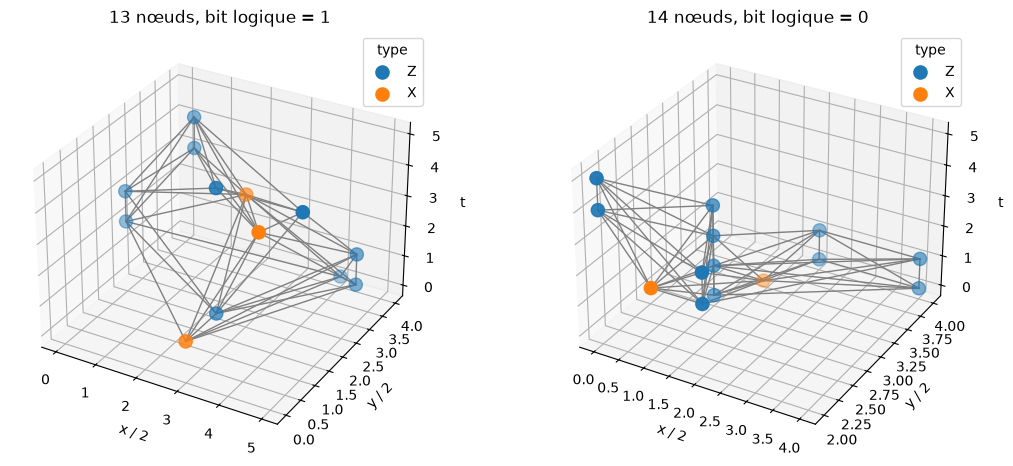

In [52]:
_ = plot_example_graphs(demo_graphs[CODE_DISTANCES[-1]], NUMBER_OF_EXAMPLE_GRAPHS, MIN_NODES_FOR_EXAMPLE)

## 3.8 Ce que l'on retient

*(Chiffres obtenus avec les paramètres par défaut et 20 000 tirages par distance, à $p=0{,}005$ ; si vous changez les paramètres, relisez les tableaux ci-dessus.)*

**1. Les graphes sont petits, surtout à $d=3$.** À $d=3$, 43 % des tirages n'ont pas de graphe (8 619 sur 20 000) et les autres ont en moyenne 2,5 nœuds (au plus 10) : beaucoup sont de simples paires ou points isolés. À $d=5$, presque tous les tirages ont un graphe (19 720 sur 20 000), avec en moyenne 8,4 nœuds (jusqu'à 31) et un degré moyen de 6,6.

**2. Le choix de $k$ compte à $d=5$, presque pas à $d=3$.** À $d=3$, le plafond ne coupe des arêtes que dans 0,5 % des graphes avec $k=6$ (8,7 % avec $k=3$). À $d=5$ il en coupe dans **55 %** des graphes avec $k=6$ (82 % avec $k=3$, 21 % avec $k=10$). `K_NEIGHBORS = 6` est donc un **point de départ** : on comparera $k=3$, $6$ et $10$ sur la validation en section 4, au moins pour $d=5$. Le poids du temps (`TIME_STEP_WEIGHT`) est un autre réglage, non encore exploré.

**3. La construction est correcte, au sens structurel.** Les 14 vérifications (7 par distance) réussissent : comptabilité des tirages, nombre de nœuds, attributs, étiquettes, choix des voisins contre un calcul brut indépendant, structure des arêtes, petits graphes. Ces tests prouvent que les graphes sont **bien construits** ; ils ne disent **pas** que ces graphes sont **utiles** au décodage. C'est ce que mesureront les sections 4 et 5.

**4. Le coût de construction est modeste.** À $d=5$, de l'ordre de 5 000 tirages par seconde, et un peu plus à $d=3$ ; ces débits varient sensiblement d'une exécution à l'autre et dépendent de votre machine (relisez l'affichage de la section 3.4). Avec cet ordre de grandeur, un jeu de 100 000 tirages à $d=5$ se construit en une vingtaine de secondes, ce qui est négligeable devant le temps d'entraînement.

**5. Limites assumées.** (i) Les égalités de distance rendent le choix des voisins non unique ; l'algorithme en retient un de façon déterministe, et rien n'indique que cela biaise, mais ce n'est pas démontré. (ii) Les attributs d'arête (déplacements) sont calculés mais le premier modèle pourra les ignorer. (iii) On ne sait pas encore si ce graphe est le « bon » : la section 4 comparera au moins plusieurs valeurs de $k$.

### Bilan de la section 3

| Livrable | Où |
|---|---|
| Tables d'attributs et de positions, avec l'unité spatiale **vérifiée** sur les données | `build_graph_tables`, `smallest_spatial_distance` |
| Arêtes : $k$ plus proches voisins puis symétrisation | `knn_edges`, `symmetrize_edges` |
| Graphe d'un tirage (nœuds, arêtes, déplacements, étiquette, numéro de tirage) | `build_graph` |
| Graphes d'un jeu de données, avec comptabilité des tirages vides | `syndrome_to_graphs`, `empty_shot_indices` |
| 14 tests de vérification réussis | section 3.5 |
| Statistiques de taille et analyse du plafond $k$ | section 3.6 |

**À retenir pour la suite :** (i) chaque graphe garde `shot`, le numéro de son tirage, pour remettre les prédictions du GNN à leur place ; (ii) les tirages sans graphe doivent être prédits « pas de retournement » et **comptés** dans l'évaluation ; (iii) `K_NEIGHBORS` et `TIME_STEP_WEIGHT` sont des hyperparamètres à régler sur la validation, jamais sur le test.

**Section 4 :** le GNN lui-même (architecture, fonction de perte, boucle d'entraînement, validation), puis son habillage dans l'interface `decode(syndrome)` pour le mesurer avec les mêmes outils que PyMatching.

---
# 4. Le GNN : modèle, entraînement, validation

**Objectif de la section.** Construire le réseau de neurones, l'entraîner sur des graphes simulés, régler ses hyperparamètres **sur un jeu de validation**, puis l'habiller dans l'interface `decode(syndrome)` pour qu'il soit mesuré par exactement les mêmes outils que PyMatching. Le jeu de **test** n'est pas touché ici : il est réservé à la section 5.

## 4.1 Les principes

**Ce que fait le réseau.** Il reçoit un graphe (les détecteurs activés d'un tirage) et renvoie **un nombre**, appelé *logit*. On le convertit en probabilité par la fonction sigmoïde $\sigma(z)=1/(1+e^{-z})$ : c'est la probabilité que le bit logique ait été retourné. Si cette probabilité dépasse 0,5 (soit un logit positif), le décodeur prédit « retournement ».

**Comment il calcule : le passage de messages.** Chaque nœud possède un vecteur de nombres (sa représentation). À chaque couche, il le met à jour en regardant ses voisins. On utilise la couche **EdgeConv** (Wang et al., *Dynamic Graph CNN*, 2019), conçue pour des nuages de points, ce qui est exactement notre cas (des points dans l'espace-temps) :
$$h_i^{\text{nouveau}}=\sum_{j\in\text{voisins}(i)}\operatorname{MLP}\big([\,h_i\;,\;h_j-h_i\,]\big).$$
Pour chaque voisin, le réseau voit **la représentation du nœud** et **la différence avec celle du voisin** (donc leur position relative, puisque la position fait partie de la représentation), et en tire un message, que l'on additionne. Un petit perceptron multicouche (MLP) apprend à fabriquer ce message. Une connexion « résiduelle » (on ajoute l'ancienne représentation) facilite l'apprentissage.

**De plusieurs nœuds à une réponse : la lecture globale.** Après les couches, on résume le graphe en un seul vecteur, en concaténant la **moyenne** des représentations (indépendante de la taille du graphe) et leur **somme** (qui garde l'information « combien d'événements »). Un dernier petit réseau convertit ce vecteur en logit.

**Comment il apprend.** Sur des exemples dont on connaît la réponse, on minimise l'**entropie croisée binaire** : si le réseau annonce une probabilité $\hat q$ et que la vraie réponse est $y\in\{0,1\}$, la perte vaut $-[\,y\log\hat q+(1-y)\log(1-\hat q)\,]$. Un optimiseur (Adam) ajuste les poids pour la réduire. On ne pondère pas les classes : la perte non pondérée donne des probabilités calibrées, et le seuil de 0,5 est alors celui qui minimise le taux d'erreur.

**Une époque** est un passage complet sur les données d'entraînement. Le *taux d'apprentissage* est réduit progressivement (décroissance en cosinus) pour affiner à la fin.

**La validation.** Après chaque époque, on mesure le **taux d'erreur logique** du GNN sur un jeu de validation indépendant (le même que celui de la règle de mesure de la section 2, donc tirages à syndrome vide inclus). On conserve les poids de la **meilleure** époque. Les hyperparamètres (type de couche, $k$) sont choisis sur ce jeu, **jamais** sur le test.

**Un budget de calcul réglable, avec reprise.** Entraîner un GNN sur CPU est lent à $d=5$ (de l'ordre de 40 secondes par époque dans mes essais, voir 4.7). L'état de l'entraînement (poids, optimiseur, historique) est donc **sauvegardé après chaque époque** dans un dossier `resultats/` : on peut interrompre, relancer, ou entraîner par séances (`MAX_EPOCHS_PER_SESSION`), et rien n'est perdu. Si les paramètres changent, la sauvegarde est ignorée et l'entraînement repart de zéro (elle contient une « signature » des paramètres pour détecter cela).

In [53]:
import copy
import json
import os
import torch.nn as nn
from torch_geometric.loader import DataLoader
from torch_geometric.nn import EdgeConv, GraphConv, global_add_pool, global_mean_pool

In [54]:
# --- Architecture du modèle -----------------------------------------------
# Deux types de couches de passage de messages comparées en section 4.6.
LAYER_KIND_EDGECONV = "edgeconv"
LAYER_KIND_GRAPHCONV = "graphconv"
# Type de couche utilisé par défaut (choisi sur la validation, section 4.6).
DEFAULT_LAYER_KIND = LAYER_KIND_EDGECONV
# Taille des représentations de nœuds (nombre de nombres par nœud).
HIDDEN_DIMENSION = 64
# Nombre de couches de passage de messages (chacune étend la « vue » d'un nœud d'un voisin de plus).
NUMBER_OF_MESSAGE_LAYERS = 3
# Façon d'additionner les messages des voisins dans EdgeConv.
EDGECONV_AGGREGATION = "add"
# EdgeConv donne à son perceptron la représentation du nœud ET la différence avec le voisin : 2 blocs.
EDGE_MLP_INPUT_MULTIPLIER = 2
# La lecture globale concatène la moyenne et la somme des représentations : 2 résumés.
NUMBER_OF_POOLINGS = 2
# Le réseau renvoie un seul nombre (le logit) par graphe.
NUMBER_OF_OUTPUTS = 1
# Un logit positif (probabilité > 0,5) signifie « le bit logique est retourné ».
DECISION_THRESHOLD_LOGIT = 0.0
# Nombre d'observables prédites par le décodeur (un seul bit logique).
NUMBER_OF_PREDICTED_OBSERVABLES = 1

# --- Entraînement -----------------------------------------------------------
# Taux d'apprentissage initial de l'optimiseur Adam.
LEARNING_RATE = 1e-3
# Taux d'apprentissage final de la décroissance en cosinus.
MINIMUM_LEARNING_RATE = 1e-5
# Nombre de graphes par paquet pendant l'entraînement.
BATCH_SIZE = 256
# Nombre de graphes par paquet pendant la prédiction (plus grand : pas de calcul de gradient).
INFERENCE_BATCH_SIZE = 1024
# Graine d'initialisation des poids du réseau.
SEED_MODEL = 0
# Nombre maximal d'époques à exécuter dans une même séance (None = pas de limite).
# Utile pour entraîner par séances : la sauvegarde permet de reprendre.
MAX_EPOCHS_PER_SESSION = None

# --- Données ------------------------------------------------------------------
# Tirages du jeu de validation (identiques pour toutes les distances).
VALIDATION_SHOTS = 40_000
# Tirages d'entraînement et époques de l'entraînement final, par distance.
FINAL_TRAIN_SHOTS = {3: 200_000, 5: 100_000}
FINAL_EPOCHS = {3: 20, 5: 20}

# --- Études courtes (sections 4.6 et 4.7) -------------------------------------
# Distance, tirages d'entraînement et époques de la comparaison des types de couches.
ARCHITECTURE_STUDY_DISTANCE = 3
ARCHITECTURE_STUDY_TRAIN_SHOTS = 100_000
ARCHITECTURE_STUDY_EPOCHS = 6
# Valeurs de k comparées, puis tirages d'entraînement et époques par distance.
K_STUDY_VALUES = (3, 6, 10)
K_STUDY_TRAIN_SHOTS = {3: 100_000, 5: 40_000}
K_STUDY_EPOCHS = {3: 5, 5: 3}
# Règle de choix de k : on retient le plus petit k dont le taux d'erreur de validation est à moins
# de ce nombre d'erreurs standard du meilleur taux (au-delà, l'écart est distinguable du hasard).
K_SELECTION_TOLERANCE_IN_STANDARD_ERRORS = 1.0

# --- Fichiers de résultats --------------------------------------------------------
# Dossier où sont sauvegardés les résultats d'études et les points de reprise.
RESULTS_DIRECTORY = "resultats"

# --- Tests de vérification ----------------------------------------------------------
# Graphes et nombre de pas pour le test « le réseau sait mémoriser un petit jeu ».
OVERFIT_NUMBER_OF_GRAPHS = 64
OVERFIT_NUMBER_OF_STEPS = 150
# La perte doit être divisée au moins par ce facteur pour que le test réussisse.
OVERFIT_REQUIRED_REDUCTION = 2.0
# Tolérance sur la sortie du réseau quand on renumérote les nœuds d'un graphe.
PERMUTATION_TOLERANCE = 1e-4
# Tirages et époques du test de reprise de l'entraînement.
RESUME_TEST_SHOTS = 2_000
RESUME_TEST_EPOCHS = 3
# Graine du test de permutation.
SEED_PERMUTATION_TEST = 123
# Taille des figures de courbes d'apprentissage.
TRAINING_FIGURE_SIZE = (11, 4)

## 4.2 Préparer les données d'entraînement et de validation

Pour une distance $d$, on simule un jeu d'entraînement (graine `SEED_TRAIN`) et un jeu de validation (graine `SEED_VALIDATION`) : ce sont des tirages **indépendants** l'un de l'autre et du jeu de test. On convertit chacun en graphes avec la fonction de la section 3.

Le jeu de validation conserve ses **bits logiques sous forme de tableau** : c'est avec eux que l'on calcule le taux d'erreur, tirages vides compris.

In [55]:
@dataclass
class TrainingSets:
    """Graphes d'entraînement et de validation pour une distance et un k donnés.

    Attributs :
        distance (int) : distance du code de surface.
        neighbors (int) : valeur de k utilisée pour construire les arêtes.
        train (ShotGraphs) : graphes du jeu d'entraînement.
        validation (ShotGraphs) : graphes du jeu de validation.
        validation_observables (ndarray bool, forme (tirages de validation,)) :
            bits logiques de référence de TOUS les tirages de validation
            (y compris ceux à syndrome vide, qui n'ont pas de graphe).
        circuit (stim.Circuit) : circuit bruité qui a généré les données.
    """
    distance: int
    neighbors: int
    train: ShotGraphs
    validation: ShotGraphs
    validation_observables: np.ndarray
    circuit: stim.Circuit


def generate_train_and_validation(distance, number_of_train_shots, number_of_validation_shots):
    """Simule un jeu d'entraînement et un jeu de validation indépendants.

    Entrées :
        distance (int) : distance du code de surface.
        number_of_train_shots (int) : nombre de tirages d'entraînement.
        number_of_validation_shots (int) : nombre de tirages de validation.
    Sortie :
        tuple (SimulatedDataset, SimulatedDataset) : (entraînement, validation),
        au taux de bruit NOISE_PROBABILITY.
    Traitement :
        génère chaque jeu avec sa propre plage de graines (SEED_TRAIN et
        SEED_VALIDATION), ce qui les rend indépendants.
    """
    train = generate_dataset(distance, NOISE_PROBABILITY, number_of_train_shots, SEED_TRAIN)
    validation = generate_dataset(distance, NOISE_PROBABILITY, number_of_validation_shots, SEED_VALIDATION)
    return train, validation


def prepare_training_sets(train_dataset, validation_dataset, k):
    """Convertit les jeux d'entraînement et de validation en graphes.

    Entrées :
        train_dataset (SimulatedDataset) : jeu d'entraînement.
        validation_dataset (SimulatedDataset) : jeu de validation.
        k (int) : nombre de plus proches voisins par nœud.
    Sortie :
        TrainingSets : graphes des deux jeux et bits logiques de validation.
    Traitement :
        applique `syndrome_to_graphs` (section 3) aux deux jeux et conserve les
        bits logiques de validation de tous les tirages.
    """
    return TrainingSets(
        distance=train_dataset.distance, neighbors=k,
        train=syndrome_to_graphs(train_dataset, k),
        validation=syndrome_to_graphs(validation_dataset, k),
        validation_observables=validation_dataset.observables[:, OBSERVABLE_COLUMN],
        circuit=validation_dataset.circuit)

## 4.3 Le modèle

La classe `DecoderGNN` assemble les pièces décrites en 4.1 : un plongement initial des attributs de nœuds (4 nombres $\rightarrow$ `HIDDEN_DIMENSION`), `NUMBER_OF_MESSAGE_LAYERS` couches de passage de messages avec connexions résiduelles, une lecture globale (moyenne + somme) et un classifieur qui produit le logit.

Le type de couche peut être **EdgeConv** (celle que l'on retient) ou **GraphConv** (une couche plus simple, qui additionne les voisins sans voir leur position relative) ; on compare les deux en 4.6.

In [56]:
def make_edge_mlp(hidden_dimension):
    """Fabrique le petit perceptron qui calcule un message dans EdgeConv.

    Entrée :
        hidden_dimension (int) : taille des représentations de nœuds.
    Sortie :
        torch.nn.Sequential : deux couches linéaires séparées par une activation
        ReLU ; reçoit EDGE_MLP_INPUT_MULTIPLIER × hidden_dimension nombres
        (représentation du nœud et différence avec le voisin) et en renvoie hidden_dimension.
    Traitement :
        assemble linéaire, ReLU, linéaire.
    """
    return nn.Sequential(nn.Linear(EDGE_MLP_INPUT_MULTIPLIER * hidden_dimension, hidden_dimension),
                         nn.ReLU(), nn.Linear(hidden_dimension, hidden_dimension))


def make_message_layer(layer_kind, hidden_dimension):
    """Fabrique une couche de passage de messages du type demandé.

    Entrées :
        layer_kind (str) : LAYER_KIND_EDGECONV ou LAYER_KIND_GRAPHCONV.
        hidden_dimension (int) : taille des représentations de nœuds.
    Sortie :
        couche PyTorch Geometric prenant (représentations, arêtes) et renvoyant
        de nouvelles représentations de même taille.
    Traitement :
        choisit EdgeConv (avec son perceptron de messages) ou GraphConv ;
        lève une erreur si le type est inconnu.
    """
    if layer_kind == LAYER_KIND_EDGECONV:
        return EdgeConv(make_edge_mlp(hidden_dimension), aggr=EDGECONV_AGGREGATION)
    if layer_kind == LAYER_KIND_GRAPHCONV:
        return GraphConv(hidden_dimension, hidden_dimension)
    raise ValueError(f"type de couche inconnu : {layer_kind}")

In [57]:
class DecoderGNN(nn.Module):
    """Réseau de neurones sur graphes qui prédit si le bit logique est retourné.

    Entrée du réseau : un lot de graphes (attributs de nœuds `x`, arêtes
    `edge_index`, appartenance des nœuds aux graphes `batch`).
    Sortie : un logit par graphe (ndarray de forme (graphes,)) ; un logit
    positif signifie « retournement prédit ».
    """

    def __init__(self, layer_kind=DEFAULT_LAYER_KIND, hidden_dimension=HIDDEN_DIMENSION,
                 number_of_layers=NUMBER_OF_MESSAGE_LAYERS):
        """Construit les couches du réseau.

        Entrées :
            layer_kind (str) : type de couche de passage de messages.
            hidden_dimension (int) : taille des représentations de nœuds.
            number_of_layers (int) : nombre de couches de passage de messages.
        Sortie :
            aucune (initialise le module).
        Traitement :
            crée le plongement des attributs, les couches de messages et le
            classifieur final (entrée : NUMBER_OF_POOLINGS résumés du graphe).
        """
        super().__init__()
        self.embedding = nn.Linear(NUMBER_OF_NODE_FEATURES, hidden_dimension)
        self.message_layers = nn.ModuleList(
            [make_message_layer(layer_kind, hidden_dimension) for _ in range(number_of_layers)])
        self.classifier = nn.Sequential(
            nn.Linear(NUMBER_OF_POOLINGS * hidden_dimension, hidden_dimension), nn.ReLU(),
            nn.Linear(hidden_dimension, NUMBER_OF_OUTPUTS))

    def forward(self, batch):
        """Calcule le logit de chaque graphe d'un lot.

        Entrée :
            batch (Batch) : lot de graphes PyTorch Geometric.
        Sortie :
            Tensor de forme (graphes,) : logits.
        Traitement :
            plonge les attributs de nœuds, applique les couches de messages avec
            connexions résiduelles, résume chaque graphe par moyenne et somme
            de ses nœuds, puis applique le classifieur.
        """
        hidden = torch.relu(self.embedding(batch.x))
        for layer in self.message_layers:
            hidden = hidden + torch.relu(layer(hidden, batch.edge_index))
        pooled = torch.cat([global_mean_pool(hidden, batch.batch), global_add_pool(hidden, batch.batch)], dim=1)
        return self.classifier(pooled).squeeze(-1)


def count_parameters(model):
    """Compte les poids entraînables d'un modèle.

    Entrée :
        model (torch.nn.Module) : modèle à examiner.
    Sortie :
        int : nombre total de poids entraînables.
    Traitement :
        additionne le nombre d'éléments de chaque tableau de poids.
    """
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

## 4.4 Prédire, et transformer des prédictions de graphes en prédictions de tirages

Les graphes n'existent que pour les tirages à syndrome non vide. Il faut donc **remettre** chaque prédiction à la place de son tirage (grâce à l'attribut `shot`) et compléter les tirages vides par « pas de retournement » :

1. `predict_logits` fait passer tous les graphes dans le réseau (sans calculer de gradients, ce qui est plus rapide) ;
2. `logits_to_shot_predictions` produit un tableau *(tirages × 1)* de booléens ;
3. `validation_failure_rate` en déduit le taux d'erreur logique, tirages vides compris.

In [58]:
def predict_logits(model, graphs):
    """Calcule le logit de chaque graphe, sans gradient.

    Entrées :
        model (DecoderGNN) : réseau à utiliser.
        graphs (list[Data]) : graphes à prédire.
    Sortie :
        tuple (logits, shot_indices) : deux ndarray de même longueur, le logit
        de chaque graphe et le numéro du tirage dont il provient. Tableaux vides
        s'il n'y a aucun graphe.
    Traitement :
        passe le modèle en mode évaluation et le fait tourner par paquets de
        INFERENCE_BATCH_SIZE graphes.
    """
    model.eval()
    logits, shots = [], []
    with torch.no_grad():
        for batch in DataLoader(graphs, batch_size=INFERENCE_BATCH_SIZE):
            logits.append(model(batch).numpy())
            shots.append(batch.shot.numpy())
    if not logits:
        return np.zeros(0), np.zeros(0, dtype=int)
    return np.concatenate(logits), np.concatenate(shots)


def logits_to_shot_predictions(logits, shot_indices, number_of_shots):
    """Convertit des logits de graphes en prédictions par tirage.

    Entrées :
        logits (ndarray float) : un logit par graphe.
        shot_indices (ndarray int) : numéro du tirage de chaque graphe.
        number_of_shots (int) : nombre TOTAL de tirages (graphes + tirages vides).
    Sortie :
        ndarray bool, forme (number_of_shots, NUMBER_OF_PREDICTED_OBSERVABLES) :
        vrai là où un retournement est prédit ; faux pour les tirages sans
        graphe (syndrome vide).
    Traitement :
        part d'un tableau de « faux » et y inscrit, à la place de chaque
        tirage ayant un graphe, le résultat de « logit > seuil ».
    """
    predictions = np.zeros((number_of_shots, NUMBER_OF_PREDICTED_OBSERVABLES), dtype=bool)
    predictions[shot_indices, OBSERVABLE_COLUMN] = logits > DECISION_THRESHOLD_LOGIT
    return predictions


def validation_failure_rate(model, shot_graphs, observables):
    """Mesure le taux d'erreur logique du modèle sur un jeu de tirages.

    Entrées :
        model (DecoderGNN) : réseau à évaluer.
        shot_graphs (ShotGraphs) : graphes du jeu (tirages vides exclus).
        observables (ndarray bool, forme (tirages,)) : bits logiques de TOUS
            les tirages du jeu.
    Sortie :
        float : proportion de tirages où la prédiction diffère du bit logique,
        tirages à syndrome vide inclus (prédits « pas de retournement »).
    Traitement :
        prédit les logits, les remet à la place de leurs tirages, et compare
        aux bits logiques de référence.
    """
    logits, shot_indices = predict_logits(model, shot_graphs.graphs)
    predictions = logits_to_shot_predictions(logits, shot_indices, shot_graphs.number_of_shots)
    return float(np.mean(predictions[:, OBSERVABLE_COLUMN] != observables))

## 4.5 La boucle d'entraînement, avec points de reprise

La boucle est découpée en petites fonctions :

* `train_one_epoch` : un passage sur les données d'entraînement (calcul de la perte, rétropropagation, mise à jour des poids) ;
* `advance_one_epoch` : une époque complète = entraînement + mesure sur la validation + mise à jour de la « meilleure époque » ;
* `save_training_state` / `load_training_state` : sauvegarde et reprise. Chaque sauvegarde contient une **signature** des paramètres (texte) ; si elle ne correspond plus aux paramètres actuels, la sauvegarde est ignorée plutôt que de mélanger deux expériences ;
* `run_training` : orchestre le tout, avec la possibilité de s'arrêter après un nombre donné d'époques (entraînement par séances).

**Reproductibilité.** L'initialisation des poids est fixée par `SEED_MODEL`. En revanche, l'**ordre de mélange** des données d'entraînement n'est pas rejoué à l'identique après une interruption : une reprise est équivalente à l'époque près, pas bit à bit.

In [59]:
def train_one_epoch(model, loader, optimizer, loss_function):
    """Effectue un passage complet sur les données d'entraînement.

    Entrées :
        model (DecoderGNN) : réseau à entraîner.
        loader (DataLoader) : paquets de graphes d'entraînement.
        optimizer (torch.optim.Optimizer) : optimiseur des poids.
        loss_function (callable) : fonction de perte (entropie croisée binaire).
    Sortie :
        float : perte moyenne sur l'époque (moyenne pondérée par graphe).
    Traitement :
        pour chaque paquet : remet les gradients à zéro, calcule la perte,
        rétropropage et met à jour les poids ; cumule la perte.
    """
    model.train()
    total_loss, total_graphs = 0.0, 0
    for batch in loader:
        optimizer.zero_grad()
        loss = loss_function(model(batch), batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs
        total_graphs += batch.num_graphs
    return total_loss / total_graphs


def make_optimizer_and_scheduler(model, number_of_epochs):
    """Crée l'optimiseur Adam et sa décroissance du taux d'apprentissage.

    Entrées :
        model (DecoderGNN) : réseau dont on optimise les poids.
        number_of_epochs (int) : durée totale de l'entraînement, en époques.
    Sortie :
        tuple (optimizer, scheduler) : Adam au taux LEARNING_RATE, et une
        décroissance en cosinus qui l'amène à MINIMUM_LEARNING_RATE à la fin.
    Traitement :
        instancie les deux objets avec les constantes de la section 4.1.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=number_of_epochs,
                                                           eta_min=MINIMUM_LEARNING_RATE)
    return optimizer, scheduler


def signature_text(signature):
    """Met une signature de paramètres sous forme de texte comparable.

    Entrée :
        signature (dict) : paramètres qui définissent une expérience.
    Sortie :
        str : représentation JSON triée de la signature.
    Traitement :
        sérialise en JSON avec les clés triées (les tuples deviennent des listes).
    """
    return json.dumps(signature, sort_keys=True, default=list)

In [60]:
def save_training_state(path, state):
    """Sauvegarde l'état d'un entraînement dans un fichier.

    Entrées :
        path (str) : chemin du fichier.
        state (dict) : état à sauvegarder (poids, optimiseur, historique, ...).
    Sortie :
        aucune (écrit le fichier, en créant le dossier si besoin).
    Traitement :
        crée le dossier parent puis appelle `torch.save`.
    """
    os.makedirs(os.path.dirname(path), exist_ok=True)
    torch.save(state, path)


def load_training_state(path, signature):
    """Recharge un état d'entraînement s'il correspond aux paramètres actuels.

    Entrées :
        path (str) : chemin du fichier de sauvegarde.
        signature (dict) : paramètres de l'expérience en cours.
    Sortie :
        dict ou None : l'état sauvegardé si le fichier existe et si sa
        signature est identique ; None sinon (un message explique pourquoi
        quand le fichier existe mais ne correspond pas).
    Traitement :
        charge le fichier et compare le texte de la signature.
    """
    if path is None or not os.path.exists(path):
        return None
    state = torch.load(path)
    if state["signature"] != signature_text(signature):
        print(f"sauvegarde ignorée (paramètres différents) : {path}")
        return None
    return state


def restore_training_state(model, optimizer, scheduler, path, signature):
    """Prépare l'état d'entraînement, en reprenant une sauvegarde si elle existe.

    Entrées :
        model, optimizer, scheduler : objets à restaurer.
        path (str ou None) : fichier de sauvegarde (None = pas de sauvegarde).
        signature (dict) : paramètres de l'expérience en cours.
    Sortie :
        dict : état suivi pendant l'entraînement (époque atteinte, historique,
        meilleur taux de validation et meilleurs poids).
    Traitement :
        part d'un état vierge ; si une sauvegarde compatible existe, restaure
        les poids, l'optimiseur, la décroissance et l'historique.
    """
    state = {"epoch": 0, "history": [], "best_rate": float("inf"), "best_state": None}
    saved = load_training_state(path, signature)
    if saved is not None:
        model.load_state_dict(saved["model_state"])
        optimizer.load_state_dict(saved["optimizer_state"])
        scheduler.load_state_dict(saved["scheduler_state"])
        state.update({key: saved[key] for key in ("epoch", "history", "best_rate", "best_state")})
        print(f"reprise à l'époque {state['epoch']} depuis {path}")
    return state

In [61]:
def advance_one_epoch(model, optimizer, scheduler, loader, sets, state):
    """Exécute une époque complète : entraînement, validation, suivi du meilleur modèle.

    Entrées :
        model, optimizer, scheduler : objets d'entraînement.
        loader (DataLoader) : paquets de graphes d'entraînement.
        sets (TrainingSets) : données d'entraînement et de validation.
        state (dict) : état suivi (modifié sur place : époque, historique,
            meilleur taux et meilleurs poids).
    Sortie :
        aucune (affiche une ligne de suivi).
    Traitement :
        entraîne une époque, fait avancer la décroissance du taux
        d'apprentissage, mesure le taux d'erreur logique sur la validation,
        l'ajoute à l'historique, et garde une copie des poids s'ils sont les meilleurs.
    """
    start = time.perf_counter()
    loss = train_one_epoch(model, loader, optimizer, nn.BCEWithLogitsLoss())
    scheduler.step()
    rate = validation_failure_rate(model, sets.validation, sets.validation_observables)
    state["epoch"] += 1
    seconds = time.perf_counter() - start
    state["history"].append({"epoch": state["epoch"], "train_loss": loss,
                             "validation_failure_rate": rate, "seconds": seconds})
    if rate < state["best_rate"]:
        state["best_rate"], state["best_state"] = rate, copy.deepcopy(model.state_dict())
    print(f"époque {state['epoch']:>3} | perte {loss:.4f} | échec validation {rate:.4f} | {seconds:.0f} s")


def run_training(model, sets, number_of_epochs, signature, checkpoint_path=None, max_epochs_this_session=None):
    """Entraîne le modèle, avec sauvegarde après chaque époque et reprise possible.

    Entrées :
        model (DecoderGNN) : réseau à entraîner (modifié sur place).
        sets (TrainingSets) : données d'entraînement et de validation.
        number_of_epochs (int) : durée totale visée de l'entraînement.
        signature (dict) : paramètres de l'expérience (pour valider les reprises).
        checkpoint_path (str ou None) : fichier de sauvegarde (None = aucune).
        max_epochs_this_session (int ou None) : nombre maximal d'époques à
            exécuter dans CETTE séance, à partir de l'époque atteinte
            (entraînement par séances) ; None = aller au bout.
    Sortie :
        tuple (history, finished) : liste des mesures par époque, et vrai si
        number_of_epochs époques ont été faites. Les meilleurs poids rencontrés
        sont rechargés dans `model`.
    Traitement :
        crée optimiseur et décroissance, reprend une sauvegarde compatible,
        enchaîne les époques en sauvegardant l'état après chacune, puis
        recharge les meilleurs poids.
    """
    optimizer, scheduler = make_optimizer_and_scheduler(model, number_of_epochs)
    state = restore_training_state(model, optimizer, scheduler, checkpoint_path, signature)
    loader = DataLoader(sets.train.graphs, batch_size=BATCH_SIZE, shuffle=True)
    last_epoch = number_of_epochs
    if max_epochs_this_session is not None:
        last_epoch = min(number_of_epochs, state["epoch"] + max_epochs_this_session)
    while state["epoch"] < last_epoch:
        advance_one_epoch(model, optimizer, scheduler, loader, sets, state)
        if checkpoint_path is not None:
            save_training_state(checkpoint_path, {**state, "signature": signature_text(signature),
                                                  "model_state": model.state_dict(),
                                                  "optimizer_state": optimizer.state_dict(),
                                                  "scheduler_state": scheduler.state_dict()})
    if state["best_state"] is not None:
        model.load_state_dict(state["best_state"])
    return state["history"], state["epoch"] >= number_of_epochs

## 4.6 Le décodeur : habiller le GNN dans l'interface commune

Pour être mesuré comme PyMatching, le GNN doit respecter la même interface : `decode(syndrome)` $\rightarrow$ tableau booléen *(tirages × 1)*. La fonction `make_gnn_decoder` construit pour cela les tables d'attributs **à partir du circuit** (positions et types des détecteurs), puis, pour chaque syndrome qu'elle reçoit :

1. construit les graphes des syndromes non vides — **sans jamais voir le bit logique** (on donne une étiquette factice, qui n'est pas utilisée) ;
2. prédit les logits ;
3. remet les prédictions à la place de leurs tirages, les syndromes vides étant prédits « pas de retournement ».

In [62]:
def tables_for_circuit(circuit):
    """Calcule les tables d'attributs de nœuds directement à partir d'un circuit.

    Entrée :
        circuit (stim.Circuit) : circuit de code de surface.
    Sortie :
        GraphTables : attributs et positions de tous les détecteurs du circuit.
    Traitement :
        lit les coordonnées des détecteurs, en déduit leur type, et construit les tables.
    """
    coordinates = get_detector_coordinates(circuit)
    return build_graph_tables(coordinates, infer_stabilizer_types(coordinates))


def graphs_from_syndrome(syndrome, tables, k):
    """Construit les graphes de syndromes dont on ne connaît PAS les bits logiques.

    Entrées :
        syndrome (ndarray bool, forme (tirages, détecteurs)) : syndromes.
        tables (GraphTables) : attributs et positions des détecteurs.
        k (int) : nombre de plus proches voisins par nœud.
    Sortie :
        list[Data] : un graphe par syndrome non vide, avec l'étiquette factice
        `False` (elle n'est jamais utilisée pour la prédiction).
    Traitement :
        pour chaque tirage non vide, appelle `build_graph` avec cette étiquette factice.
    """
    graphs = []
    for shot_index, row in enumerate(syndrome):
        node_ids = np.flatnonzero(row)
        if len(node_ids) != NO_FIRED_DETECTOR:
            graphs.append(build_graph(node_ids, tables, False, shot_index, k))
    return graphs


def make_gnn_decoder(model, circuit, k):
    """Habille un GNN entraîné dans l'interface commune des décodeurs.

    Entrées :
        model (DecoderGNN) : réseau entraîné.
        circuit (stim.Circuit) : circuit dont on décode les syndromes (sert
            uniquement à connaître les positions et types des détecteurs).
        k (int) : nombre de plus proches voisins utilisé à l'entraînement.
    Sortie :
        fonction decode(syndrome) -> ndarray bool de forme (tirages, 1).
    Traitement :
        calcule les tables d'attributs une fois, puis renvoie une fonction qui
        construit les graphes, prédit les logits et les remet à leur place.
    """
    tables = tables_for_circuit(circuit)

    def decode(syndrome):
        """Prédit le bit logique de chaque tirage à partir du seul syndrome."""
        graphs = graphs_from_syndrome(syndrome, tables, k)
        logits, shot_indices = predict_logits(model, graphs)
        return logits_to_shot_predictions(logits, shot_indices, len(syndrome))
    return decode

## 4.7 Vérifier le modèle, l'entraînement et le décodeur

Comme pour les sections précédentes, on teste sur des cas où la bonne réponse est connue.

| Test | Ce qui est vérifié |
|---|---|
| Forme des sorties | un logit fini par graphe |
| **Invariance par renumérotation** | changer l'ordre des nœuds d'un graphe ne change pas la sortie (un GNN ne doit pas dépendre de la numérotation arbitraire des nœuds) |
| Mémorisation d'un petit jeu | l'entraînement sait faire baisser la perte sur 64 graphes : si ce n'est pas le cas, la boucle d'entraînement est cassée |
| Graphes sans étiquette | `graphs_from_syndrome` donne les mêmes nœuds et arêtes que `syndrome_to_graphs` |
| Syndrome vide | le décodeur prédit « pas de retournement » |
| **Cohérence décodeur / mesure d'entraînement** | le taux d'erreur calculé via l'interface `decode` est identique à celui de `validation_failure_rate` |
| Reprise de l'entraînement | s'arrêter puis reprendre donne le bon nombre d'époques ; des paramètres différents annulent la reprise |

In [63]:
def check_output_shape(model, graphs):
    """Teste que le réseau renvoie un logit fini par graphe.

    Entrées :
        model (DecoderGNN) : réseau à tester.
        graphs (list[Data]) : quelques graphes.
    Sortie :
        bool : vrai si la sortie a pour forme (nombre de graphes,) et ne
        contient que des valeurs finies.
    Traitement :
        regroupe les graphes en un lot et fait passer le lot dans le réseau.
    """
    model.eval()
    with torch.no_grad():
        output = model(next(iter(DataLoader(graphs, batch_size=len(graphs)))))
    return tuple(output.shape) == (len(graphs),) and bool(torch.isfinite(output).all())


def renumber_graph_nodes(graph, seed):
    """Renumérote au hasard les nœuds d'un graphe sans changer sa structure.

    Entrées :
        graph (Data) : graphe d'origine.
        seed (int) : graine du tirage aléatoire de la renumérotation.
    Sortie :
        Data : le même graphe, dont les nœuds sont dans un autre ordre (les
        attributs et les arêtes sont modifiés de façon cohérente).
    Traitement :
        tire une permutation, réordonne les attributs de nœuds, et réécrit
        les numéros de nœuds dans la liste des arêtes.
    """
    generator = torch.Generator().manual_seed(seed)
    order = torch.randperm(graph.num_nodes, generator=generator)
    new_position = torch.argsort(order)
    return Data(x=graph.x[order], edge_index=new_position[graph.edge_index],
                edge_attr=graph.edge_attr, y=graph.y, shot=graph.shot)


def check_permutation_invariance(model, graphs, seed):
    """Teste que la sortie du réseau ne dépend pas de la numérotation des nœuds.

    Entrées :
        model (DecoderGNN) : réseau à tester.
        graphs (list[Data]) : graphes à renuméroter.
        seed (int) : graine de la renumérotation.
    Sortie :
        bool : vrai si, pour tous les graphes, l'écart de sortie avant/après
        renumérotation est inférieur à PERMUTATION_TOLERANCE.
    Traitement :
        compare les logits du lot d'origine et du lot renuméroté.
    """
    model.eval()
    renumbered = [renumber_graph_nodes(graph, seed + index) for index, graph in enumerate(graphs)]
    with torch.no_grad():
        original = model(next(iter(DataLoader(graphs, batch_size=len(graphs)))))
        permuted = model(next(iter(DataLoader(renumbered, batch_size=len(renumbered)))))
    return bool((original - permuted).abs().max() < PERMUTATION_TOLERANCE)

In [64]:
def check_overfit_small_set(graphs, number_of_steps):
    """Teste que la boucle d'entraînement sait mémoriser un petit jeu de graphes.

    Entrées :
        graphs (list[Data]) : petit jeu de graphes (quelques dizaines).
        number_of_steps (int) : nombre de pas d'optimisation.
    Sortie :
        bool : vrai si la perte finale est au moins OVERFIT_REQUIRED_REDUCTION
        fois plus petite que la perte initiale.
    Traitement :
        entraîne un modèle neuf sur ces graphes seuls (un seul paquet, sans
        mélange) et compare la perte de départ à celle d'arrivée.
    """
    torch.manual_seed(SEED_MODEL)
    model = DecoderGNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    batch = next(iter(DataLoader(graphs, batch_size=len(graphs))))
    losses = []
    for _ in range(number_of_steps):
        optimizer.zero_grad()
        loss = nn.BCEWithLogitsLoss()(model(batch), batch.y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses[0] / losses[-1] >= OVERFIT_REQUIRED_REDUCTION


def check_graphs_without_labels(dataset, k, number_of_graphs):
    """Teste que les graphes sans étiquette ont la même structure que ceux de la section 3.

    Entrées :
        dataset (SimulatedDataset) : jeu de données.
        k (int) : nombre de voisins.
        number_of_graphs (int) : nombre de graphes comparés.
    Sortie :
        bool : vrai si, pour les premiers graphes, les attributs de nœuds et
        les arêtes sont identiques dans les deux constructions.
    Traitement :
        construit les graphes par les deux fonctions et compare terme à terme.
    """
    reference = syndrome_to_graphs(dataset, k).graphs[:number_of_graphs]
    tables = build_graph_tables(dataset.coordinates, dataset.stabilizer_types)
    candidate = graphs_from_syndrome(dataset.syndrome, tables, k)[:number_of_graphs]
    return all(torch.equal(a.x, b.x) and torch.equal(a.edge_index, b.edge_index)
               for a, b in zip(reference, candidate))

In [65]:
def check_empty_syndrome_prediction(model, circuit, k, number_of_shots):
    """Teste que le décodeur prédit « pas de retournement » pour un syndrome vide.

    Entrées :
        model (DecoderGNN) : réseau à tester.
        circuit (stim.Circuit) : circuit de référence.
        k (int) : nombre de voisins.
        number_of_shots (int) : nombre de syndromes vides testés.
    Sortie :
        bool : vrai si toutes les prédictions sont fausses (aucun retournement)
        et ont la forme attendue.
    Traitement :
        décode un tableau de syndromes entièrement nuls.
    """
    decoder = make_gnn_decoder(model, circuit, k)
    prediction = decoder(np.zeros((number_of_shots, circuit.num_detectors), dtype=bool))
    return prediction.shape == (number_of_shots, NUMBER_OF_PREDICTED_OBSERVABLES) and not prediction.any()


def check_decoder_matches_validation_metric(model, sets, validation_dataset):
    """Teste que l'interface de décodage donne le même taux que la mesure d'entraînement.

    Entrées :
        model (DecoderGNN) : réseau à tester.
        sets (TrainingSets) : données (contient les graphes de validation).
        validation_dataset (SimulatedDataset) : jeu de validation d'origine.
    Sortie :
        bool : vrai si les deux taux d'erreur sont égaux.
    Traitement :
        calcule le taux via `validation_failure_rate`, puis via
        `make_gnn_decoder` + `per_shot_failures` sur les mêmes tirages.
    """
    direct = validation_failure_rate(model, sets.validation, sets.validation_observables)
    decoder = make_gnn_decoder(model, sets.circuit, sets.neighbors)
    failures = per_shot_failures(decoder(validation_dataset.syndrome), validation_dataset.observables)
    return abs(direct - float(failures.mean())) < FLOAT_TOLERANCE


def check_training_resume(sets, checkpoint_path):
    """Teste l'entraînement par séances, la reprise et le rejet d'une signature différente.

    Entrées :
        sets (TrainingSets) : petites données d'entraînement et de validation.
        checkpoint_path (str) : fichier temporaire de sauvegarde.
    Sortie :
        bool : vrai si (1) deux séances limitées à une époque avancent chacune
        d'une époque sans finir, (2) une troisième séance sans limite termine avec
        le bon nombre d'époques, et (3) une signature différente repart de zéro.
    Traitement :
        enchaîne trois séances avec la même signature, puis une quatrième avec
        une signature modifiée.
    """
    signature = {"test": "reprise"}
    sessions = []
    for limit in (1, 1, None):
        torch.manual_seed(SEED_MODEL)
        sessions.append(run_training(DecoderGNN(), sets, RESUME_TEST_EPOCHS, signature, checkpoint_path, limit))
    other, _ = run_training(DecoderGNN(), sets, RESUME_TEST_EPOCHS, {"test": "autre"}, checkpoint_path, 1)
    (first, first_done), (second, second_done), (third, third_done) = sessions
    return (len(first) == 1 and not first_done and len(second) == len(first) + 1 and not second_done
            and len(third) == RESUME_TEST_EPOCHS and third_done and len(other) == 1)

In [66]:
test_train, test_validation = generate_train_and_validation(CODE_DISTANCES[0], RESUME_TEST_SHOTS, RESUME_TEST_SHOTS)
test_sets = prepare_training_sets(test_train, test_validation, K_NEIGHBORS)
torch.manual_seed(SEED_MODEL)
test_model = DecoderGNN()
print(f"modèle de test : {count_parameters(test_model):,} poids entraînables\n")
test_graphs = test_sets.train.graphs[:OVERFIT_NUMBER_OF_GRAPHS]
test_path = os.path.join(RESULTS_DIRECTORY, "test_reprise.pt")
if os.path.exists(test_path):
    os.remove(test_path)
model_checks = {
    "forme des sorties (un logit fini par graphe)": check_output_shape(test_model, test_graphs),
    "invariance par renumérotation des nœuds": check_permutation_invariance(test_model, test_graphs, SEED_PERMUTATION_TEST),
    "mémorisation d'un petit jeu (la perte baisse)": check_overfit_small_set(test_graphs, OVERFIT_NUMBER_OF_STEPS),
    "graphes sans étiquette = graphes de la section 3": check_graphs_without_labels(test_validation, K_NEIGHBORS, OVERFIT_NUMBER_OF_GRAPHS),
    "syndrome vide : aucun retournement prédit": check_empty_syndrome_prediction(test_model, test_sets.circuit, K_NEIGHBORS, NUMBER_OF_SHOTS_TO_PRINT),
    "décodeur = mesure d'entraînement": check_decoder_matches_validation_metric(test_model, test_sets, test_validation),
}
print("--- séances de test de la reprise (affichage normal) ---")
model_checks["reprise de l'entraînement et signature"] = check_training_resume(test_sets, test_path)
os.remove(test_path)
print()
for name, passed in model_checks.items():
    print(f"{name:<52} {'OK' if passed else 'ECHEC'}")
assert all(model_checks.values()), "un test du modèle a échoué"

modèle de test : 45,889 poids entraînables



--- séances de test de la reprise (affichage normal) ---
époque   1 | perte 0.5024 | échec validation 0.1135 | 0 s
reprise à l'époque 1 depuis resultats/test_reprise.pt


époque   2 | perte 0.4642 | échec validation 0.1120 | 0 s
reprise à l'époque 2 depuis resultats/test_reprise.pt
époque   3 | perte 0.4440 | échec validation 0.1120 | 0 s
sauvegarde ignorée (paramètres différents) : resultats/test_reprise.pt


époque   1 | perte 0.6107 | échec validation 0.1120 | 0 s

forme des sorties (un logit fini par graphe)         OK
invariance par renumérotation des nœuds              OK
mémorisation d'un petit jeu (la perte baisse)        OK
graphes sans étiquette = graphes de la section 3     OK
syndrome vide : aucun retournement prédit            OK
décodeur = mesure d'entraînement                     OK
reprise de l'entraînement et signature               OK


## 4.8 Premier choix : quel type de couche ?

Avant d'investir du temps de calcul, on compare **à budget égal** (mêmes données, mêmes époques, même initialisation) les deux types de couches, sur la distance $d=3$ où l'entraînement est rapide. On regarde le **taux d'erreur logique sur la validation** après chaque époque. PyMatching sert de repère.

> **Limite à garder en tête.** C'est une comparaison à court terme : elle dit quelle couche apprend le plus vite, pas nécessairement laquelle serait la meilleure après un très long entraînement.

Les résultats sont mis en cache dans `resultats/` : relancer le notebook ne refait pas le calcul tant que les paramètres ne changent pas.

In [67]:
def cached_result(path, signature, compute):
    """Renvoie un résultat sauvegardé, ou le calcule et le sauvegarde.

    Entrées :
        path (str) : fichier JSON de cache.
        signature (dict) : paramètres qui définissent le calcul.
        compute (callable sans argument) : fonction qui calcule le résultat
            (sérialisable en JSON).
    Sortie :
        le résultat (rechargé du cache si sa signature correspond).
    Traitement :
        si le fichier existe avec la même signature, le recharge ; sinon
        appelle `compute`, sauvegarde le résultat avec la signature et le renvoie.
    """
    if os.path.exists(path):
        with open(path, encoding="utf-8") as file:
            saved = json.load(file)
        if saved["signature"] == signature_text(signature):
            return saved["result"]
    result = compute()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w", encoding="utf-8") as file:
        json.dump({"signature": signature_text(signature), "result": result}, file)
    return result


def run_short_experiment(sets, layer_kind, number_of_epochs):
    """Entraîne un modèle neuf pendant peu d'époques et relève sa courbe de validation.

    Entrées :
        sets (TrainingSets) : données d'entraînement et de validation.
        layer_kind (str) : type de couche à tester.
        number_of_epochs (int) : nombre d'époques.
    Sortie :
        dict : « courbe » (taux d'erreur de validation après chaque époque),
        « secondes par époque » et « poids » (nombre de poids entraînables).
    Traitement :
        initialise le modèle avec SEED_MODEL, l'entraîne sans sauvegarde, et
        résume l'historique.
    """
    torch.manual_seed(SEED_MODEL)
    model = DecoderGNN(layer_kind)
    history, _ = run_training(model, sets, number_of_epochs, signature=None)
    return {"courbe": [step["validation_failure_rate"] for step in history],
            "secondes par époque": float(np.mean([step["seconds"] for step in history])),
            "poids": count_parameters(model)}

In [68]:
def study_architectures(distance):
    """Compare EdgeConv et GraphConv à budget égal (résultat mis en cache).

    Entrée :
        distance (int) : distance du code de surface.
    Sortie :
        dict : type de couche -> résultat de `run_short_experiment`.
    Traitement :
        simule les données une fois, construit les graphes avec K_NEIGHBORS,
        puis entraîne un modèle pour chaque type de couche. Le résultat est
        stocké dans RESULTS_DIRECTORY avec une signature des paramètres.
    """
    signature = {"étude": "architecture", "d": distance, "p": NOISE_PROBABILITY, "k": K_NEIGHBORS,
                 "tirages": ARCHITECTURE_STUDY_TRAIN_SHOTS, "validation": VALIDATION_SHOTS,
                 "époques": ARCHITECTURE_STUDY_EPOCHS, "taux": LEARNING_RATE, "paquet": BATCH_SIZE,
                 "dimension": HIDDEN_DIMENSION, "couches": NUMBER_OF_MESSAGE_LAYERS}

    def compute():
        """Simule les données puis entraîne un modèle pour chaque configuration étudiée."""
        train, validation = generate_train_and_validation(distance, ARCHITECTURE_STUDY_TRAIN_SHOTS, VALIDATION_SHOTS)
        sets = prepare_training_sets(train, validation, K_NEIGHBORS)
        return {kind: run_short_experiment(sets, kind, ARCHITECTURE_STUDY_EPOCHS)
                for kind in (LAYER_KIND_GRAPHCONV, LAYER_KIND_EDGECONV)}
    return cached_result(os.path.join(RESULTS_DIRECTORY, f"etude_architecture_d{distance}.json"), signature, compute)

In [69]:
architecture_results = study_architectures(ARCHITECTURE_STUDY_DISTANCE)
validation_reference = generate_dataset(ARCHITECTURE_STUDY_DISTANCE, NOISE_PROBABILITY, VALIDATION_SHOTS, SEED_VALIDATION)
reference_matching_rate = float(per_shot_failures(make_matching_decoder(validation_reference.circuit)(validation_reference.syndrome),
                                                   validation_reference.observables).mean())
rows = []
for kind, result in architecture_results.items():
    rows.append({"couche": kind, "poids": result["poids"], "s/époque": result["secondes par époque"],
                 **{f"époque {i + 1}": rate for i, rate in enumerate(result["courbe"])}})
print(f"d = {ARCHITECTURE_STUDY_DISTANCE} : taux d'erreur sur la validation, PyMatching = {reference_matching_rate:.4f}, "
      f"décodeur trivial = {validation_reference.observables.mean():.4f}\n")
pd.DataFrame(rows).style.format({"s/époque": "{:.1f}", **{f"époque {i + 1}": "{:.4f}" for i in range(ARCHITECTURE_STUDY_EPOCHS)}}).hide(axis="index")

d = 3 : taux d'erreur sur la validation, PyMatching = 0.0170, décodeur trivial = 0.1042



couche,poids,s/époque,époque 1,époque 2,époque 3,époque 4,époque 5,époque 6
graphconv,33409,3.7,0.0380,0.0302,0.0272,0.0255,0.0254,0.0245
edgeconv,45889,5.3,0.0282,0.0299,0.0206,0.0199,0.0188,0.0185


## 4.9 Deuxième choix : combien de voisins ($k$) ?

Section 3 a montré que le plafond $k$ ne coupe presque aucune arête à $d=3$ avec $k=6$, mais **en coupe plus de la moitié à $d=5$**. On compare donc $k=3$, $6$ et $10$ à budget égal et court, pour chaque distance, avec le type de couche retenu. Pour $d=5$, le budget est volontairement plus court (40 000 tirages, 3 époques) car l'entraînement y est beaucoup plus lent.

> **Deux limites à garder en tête.** (i) Un budget court favorise les configurations qui apprennent vite au début, pas forcément celles qui seront les meilleures après un long entraînement. (ii) Les différences entre valeurs de $k$ peuvent être du même ordre que la variation d'une graine à l'autre : on ne les interprète que si elles sont nettes. **Règle de choix :** on retient le **plus petit** $k$ dont le taux d'erreur de validation (à la dernière époque) est à moins d'**une erreur standard** du meilleur taux. Entre deux valeurs indiscernables, on préfère le $k$ le moins coûteux, car un $k$ plus petit donne des graphes plus petits et un calcul plus rapide.

In [70]:
def study_neighbors(distance):
    """Compare plusieurs valeurs de k à budget égal (résultat mis en cache).

    Entrée :
        distance (int) : distance du code de surface.
    Sortie :
        dict : valeur de k (en texte) -> résultat de `run_short_experiment`.
    Traitement :
        simule les données une fois, puis, pour chaque k de K_STUDY_VALUES,
        reconstruit les graphes et entraîne un modèle neuf avec la couche par
        défaut. Le résultat est stocké avec une signature des paramètres.
    """
    signature = {"étude": "k", "d": distance, "p": NOISE_PROBABILITY, "valeurs": list(K_STUDY_VALUES),
                 "tirages": K_STUDY_TRAIN_SHOTS[distance], "validation": VALIDATION_SHOTS,
                 "époques": K_STUDY_EPOCHS[distance], "couche": DEFAULT_LAYER_KIND, "taux": LEARNING_RATE,
                 "paquet": BATCH_SIZE, "dimension": HIDDEN_DIMENSION, "couches": NUMBER_OF_MESSAGE_LAYERS}

    def compute():
        """Simule les données puis entraîne un modèle pour chaque configuration étudiée."""
        train, validation = generate_train_and_validation(distance, K_STUDY_TRAIN_SHOTS[distance], VALIDATION_SHOTS)
        return {str(k): run_short_experiment(prepare_training_sets(train, validation, k),
                                             DEFAULT_LAYER_KIND, K_STUDY_EPOCHS[distance])
                for k in K_STUDY_VALUES}
    return cached_result(os.path.join(RESULTS_DIRECTORY, f"etude_k_d{distance}.json"), signature, compute)


def select_best_k(study_results):
    """Choisit le plus petit k dont le taux de validation est proche du meilleur.

    Entrée :
        study_results (dict) : valeur de k (texte) -> résultat d'une expérience courte.
    Sortie :
        int : le plus petit k dont le taux d'erreur de validation (dernière
        époque) ne dépasse pas le meilleur taux de plus de
        K_SELECTION_TOLERANCE_IN_STANDARD_ERRORS erreurs standard.
    Traitement :
        relève le taux final de chaque k, calcule l'erreur standard d'un taux
        mesuré sur VALIDATION_SHOTS tirages (racine de p(1-p)/N) au meilleur
        taux, puis garde le plus petit k sous le seuil. Entre deux valeurs
        indiscernables, on préfère le k le moins coûteux.
    """
    final_rates = {int(k): result["courbe"][-1] for k, result in study_results.items()}
    best = min(final_rates.values())
    standard_error = np.sqrt(best * (1 - best) / VALIDATION_SHOTS)
    threshold = best + K_SELECTION_TOLERANCE_IN_STANDARD_ERRORS * standard_error
    return min(k for k, rate in final_rates.items() if rate <= threshold)

In [71]:
k_study_results = {d: study_neighbors(d) for d in CODE_DISTANCES}
selected_k = {d: select_best_k(k_study_results[d]) for d in CODE_DISTANCES}
rows = [{"d": d, "k": int(k), "échec validation (dernière époque)": r["courbe"][-1], "s/époque": r["secondes par époque"]}
        for d in CODE_DISTANCES for k, r in k_study_results[d].items()]
display(pd.DataFrame(rows).style.format({"échec validation (dernière époque)": "{:.4f}", "s/époque": "{:.1f}"}).hide(axis="index"))
print("k retenu par distance :", selected_k)

d,k,échec validation (dernière époque),s/époque
3,3,0.0197,5.2
3,6,0.0191,5.1
3,10,0.0190,5.5
5,3,0.1419,13.2
5,6,0.1988,22.9
5,10,0.2296,29.2


k retenu par distance : {3: 6, 5: 3}


## 4.10 Entraînement final

On entraîne maintenant, pour chaque distance, un modèle avec le $k$ retenu, sur un jeu d'entraînement plus grand et pendant davantage d'époques (`FINAL_TRAIN_SHOTS`, `FINAL_EPOCHS`). L'état est sauvegardé après chaque époque dans `resultats/gnn_d<distance>.pt`.

> **Combien de temps ?** À $d=5$ le calcul est long. Dans mes essais sur un seul cœur de processeur, une époque prenait de l'ordre de 40 secondes pour 100 000 tirages ; sur votre machine ce sera différent (le temps réel de chaque époque est affiché). Vous pouvez interrompre à tout moment et relancer la cellule : l'entraînement **reprend** là où il s'était arrêté. Pour entraîner par séances, fixez `MAX_EPOCHS_PER_SESSION`.

In [72]:
@dataclass
class FinalModel:
    """Modèle entraîné pour une distance, avec son historique.

    Attributs :
        distance (int) : distance du code.
        neighbors (int) : valeur de k utilisée.
        model (DecoderGNN) : réseau, avec les meilleurs poids rencontrés.
        history (list[dict]) : mesures par époque (perte, taux de validation, durée).
        finished (bool) : vrai si toutes les époques prévues ont été faites.
        sets (TrainingSets) : données d'entraînement et de validation utilisées.
    """
    distance: int
    neighbors: int
    model: DecoderGNN
    history: list
    finished: bool
    sets: TrainingSets


def train_final_model(distance, k):
    """Entraîne (ou reprend l'entraînement de) le modèle final d'une distance.

    Entrées :
        distance (int) : distance du code de surface.
        k (int) : nombre de voisins retenu pour cette distance.
    Sortie :
        FinalModel : modèle, historique et données.
    Traitement :
        simule les données d'entraînement et de validation, construit les
        graphes, initialise un modèle avec SEED_MODEL, puis appelle
        `run_training` avec une sauvegarde dans RESULTS_DIRECTORY.
    """
    train, validation = generate_train_and_validation(distance, FINAL_TRAIN_SHOTS[distance], VALIDATION_SHOTS)
    sets = prepare_training_sets(train, validation, k)
    signature = {"final": True, "d": distance, "p": NOISE_PROBABILITY, "k": k, "tirages": FINAL_TRAIN_SHOTS[distance],
                 "validation": VALIDATION_SHOTS, "époques": FINAL_EPOCHS[distance], "couche": DEFAULT_LAYER_KIND,
                 "taux": LEARNING_RATE, "minimum": MINIMUM_LEARNING_RATE, "paquet": BATCH_SIZE,
                 "dimension": HIDDEN_DIMENSION, "couches": NUMBER_OF_MESSAGE_LAYERS}
    torch.manual_seed(SEED_MODEL)
    model = DecoderGNN()
    path = os.path.join(RESULTS_DIRECTORY, f"gnn_d{distance}.pt")
    history, finished = run_training(model, sets, FINAL_EPOCHS[distance], signature, path, MAX_EPOCHS_PER_SESSION)
    return FinalModel(distance, k, model, history, finished, sets)

In [73]:
final_models = {}
for distance in CODE_DISTANCES:
    print(f"=== d = {distance} (k = {selected_k[distance]}) ===")
    final_models[distance] = train_final_model(distance, selected_k[distance])
    status = "terminé" if final_models[distance].finished else "INCOMPLET (relancer la cellule pour continuer)"
    print(f"entraînement {status}\n")

=== d = 3 (k = 6) ===


reprise à l'époque 20 depuis resultats/gnn_d3.pt
entraînement terminé

=== d = 5 (k = 3) ===


reprise à l'époque 20 depuis resultats/gnn_d5.pt
entraînement terminé



## 4.11 Courbes d'apprentissage et comparaison sur la validation

Les courbes montrent le **taux d'erreur logique sur la validation** en fonction de l'époque, avec deux repères : le décodeur trivial (ne corrige jamais, en haut) et PyMatching (en bas). Le tableau compare ensuite les trois décodeurs **sur les mêmes tirages de validation**, avec la comparaison appariée de la section 2.

> **Rappel.** Il s'agit toujours de la *validation*, utilisée pour régler le modèle. La mesure finale, sur le jeu de test jamais utilisé, est l'objet de la section 5.

In [74]:
def plot_training_history(final_model, matching_rate, trivial_rate, axis):
    """Trace la courbe d'apprentissage d'un modèle avec les deux repères.

    Entrées :
        final_model (FinalModel) : modèle et historique.
        matching_rate (float) : taux d'erreur de PyMatching sur la validation.
        trivial_rate (float) : taux d'erreur du décodeur trivial sur la validation.
        axis (matplotlib Axes) : zone de dessin.
    Sortie :
        aucune (modifie `axis`).
    Traitement :
        trace le taux d'erreur de validation par époque en échelle
        logarithmique et ajoute deux lignes horizontales de référence.
    """
    epochs = [step["epoch"] for step in final_model.history]
    rates = [step["validation_failure_rate"] for step in final_model.history]
    axis.plot(epochs, rates, marker=CURVE_MARKER, label="GNN (validation)")
    axis.axhline(matching_rate, color="tab:green", linestyle="--", label="PyMatching")
    axis.axhline(trivial_rate, color="tab:red", linestyle=":", label="trivial (ne corrige jamais)")
    axis.set_yscale("log")
    axis.set_xlabel("époque"); axis.set_ylabel("taux d'erreur logique (validation)")
    axis.set_title(f"d = {final_model.distance}, k = {final_model.neighbors}")
    axis.legend(); axis.grid(True, which="both", alpha=GRID_TRANSPARENCY)


def validation_comparison(final_model):
    """Compare GNN, PyMatching et trivial sur les mêmes tirages de validation.

    Entrée :
        final_model (FinalModel) : modèle entraîné.
    Sortie :
        tuple (rows, paired) : lignes de résultats (échecs, tirages, taux et
        intervalle de confiance par décodeur) et résultat de la comparaison
        appariée GNN contre PyMatching.
    Traitement :
        évalue les trois décodeurs avec `evaluate_decoders` sur les tirages de
        validation (graine SEED_VALIDATION), puis estime les taux et compare le
        GNN à PyMatching par le test binomial exact.
    """
    circuit = final_model.sets.circuit
    decoders = {"GNN": make_gnn_decoder(final_model.model, circuit, final_model.neighbors),
                DECODER_MATCHING: make_matching_decoder(circuit),
                DECODER_TRIVIAL: make_trivial_decoder(circuit.num_observables)}
    failures = evaluate_decoders(decoders, circuit, VALIDATION_SHOTS, SEED_VALIDATION)
    rows = make_table_rows(final_model.distance, NOISE_PROBABILITY, failures)
    return rows, paired_failure_comparison(failures["GNN"], failures[DECODER_MATCHING])

d,p,décodeur,échecs,tirages,taux,bas,haut
3,0.005,GNN,648,40000,0.0162,0.0150,0.0175
3,0.005,PyMatching,679,40000,0.0170,0.0158,0.0183
3,0.005,trivial (ne corrige jamais),4167,40000,0.1042,0.1012,0.1072
5,0.005,GNN,2242,40000,0.0561,0.0538,0.0583
5,0.005,PyMatching,562,40000,0.0140,0.0129,0.0153
5,0.005,trivial (ne corrige jamais),9297,40000,0.2324,0.2283,0.2366


d = 3 : GNN contre PyMatching, tirages où seul le GNN échoue = 145, où seul PyMatching échoue = 176, valeur p = 0.094
d = 5 : GNN contre PyMatching, tirages où seul le GNN échoue = 1917, où seul PyMatching échoue = 237, valeur p = 0


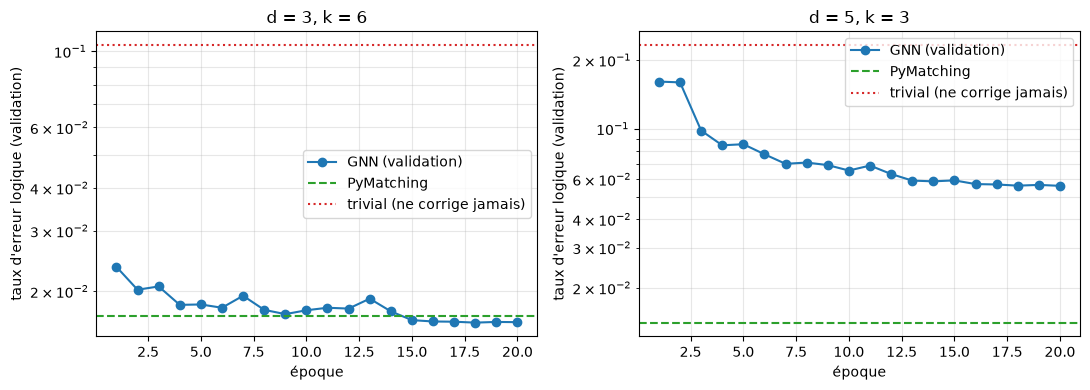

In [75]:
validation_rows, paired_results = [], {}
for distance, final_model in final_models.items():
    rows, paired_results[distance] = validation_comparison(final_model)
    validation_rows += rows
validation_table = pd.DataFrame(validation_rows)
figure, axes = plt.subplots(1, len(final_models), figsize=TRAINING_FIGURE_SIZE)
for axis, (distance, final_model) in zip(np.atleast_1d(axes), final_models.items()):
    rates = validation_table[validation_table["d"] == distance].set_index("décodeur")["taux"]
    plot_training_history(final_model, rates[DECODER_MATCHING], rates[DECODER_TRIVIAL], axis)
figure.tight_layout()
display(validation_table.style.format({"p": "{:.3f}", "taux": "{:.4f}", "bas": "{:.4f}", "haut": "{:.4f}"}).hide(axis="index"))
for distance, result in paired_results.items():
    print(f"d = {distance} : GNN contre PyMatching, tirages où seul le GNN échoue = {result['seulement A']}, "
          f"où seul PyMatching échoue = {result['seulement B']}, valeur p = {result['valeur p']:.2g}")

## 4.12 Ce que l'on retient

*(Chiffres obtenus avec les paramètres par défaut, une seule graine d'initialisation, à $p=0{,}005$ ; tous les taux sont mesurés sur le jeu de **validation** de 40 000 tirages. Si vous changez les paramètres, relisez les tableaux ci-dessus.)*

**1. Le type de couche compte.** À budget égal ($d=3$, 6 époques), `EdgeConv` atteint **1,85 %** d'échecs de validation contre **2,45 %** pour `GraphConv`, avec PyMatching à 1,70 %. L'écart (0,6 point) est large devant l'incertitude d'une mesure sur 40 000 tirages (environ 0,07 point), mais il vient d'**une seule initialisation** : on n'a pas mesuré la variation d'une graine à l'autre. On retient `EdgeConv`, qui coûte un peu plus cher par époque (5,3 s contre 3,7 s).

**2. Le choix de $k$ dépend de la distance.** À $d=3$, $k=3$, $6$ et $10$ sont indiscernables (1,97 %, 1,91 %, 1,90 %) : la règle retient $k=6$. À $d=5$, l'écart est net, avec le budget court de l'étude : $k=3$ atteint 14,2 % d'échecs, $k=6$ 19,9 % et $k=10$ 23,0 % (soit le niveau du décodeur trivial : ce réseau n'a presque pas commencé à apprendre). Un $k$ plus petit est aussi plus rapide (13 s contre 23 s et 29 s par époque). On retient $k=3$ à $d=5$. **Limite :** cette étude mesure la vitesse d'apprentissage au début ; elle ne dit pas que $k=3$ resterait le meilleur après un très long entraînement.

**3. À $d=3$, le GNN atteint le niveau de PyMatching.** Taux d'échec de validation : **1,62 %** [1,50 ; 1,75] pour le GNN contre **1,70 %** [1,58 ; 1,83] pour PyMatching. Sur les 321 tirages où exactement un des deux décodeurs échoue, 145 sont des échecs du GNN seul et 176 de PyMatching seul ; la valeur p est de 0,094 : **on ne peut pas distinguer les deux décodeurs**. On ne peut donc pas affirmer que le GNN fait *mieux*. De plus, le choix de l'époque, du type de couche et de $k$ s'est fait sur ce même jeu de validation, ce qui rend ces chiffres un peu optimistes : seule la section 5, sur un jeu jamais utilisé, tranchera.

**4. À $d=5$, le GNN est loin de PyMatching, avec ce budget.** **5,61 %** [5,38 ; 5,83] contre **1,40 %** [1,29 ; 1,53] pour PyMatching, soit environ quatre fois plus d'échecs ; sur les tirages discordants, 1 917 sont des échecs du GNN seul contre 237 pour PyMatching seul. Le GNN supprime environ 76 % des échecs du décodeur trivial (23,2 % $\rightarrow$ 5,6 %), PyMatching environ 94 %. La courbe d'apprentissage s'aplatit en fin d'entraînement, en partie parce que le taux d'apprentissage a décru : avec 100 000 tirages, 20 époques et 45 889 poids, le modèle est limité par son budget. **On ne sait pas** si davantage de données, d'époques ou de capacité comblerait l'écart : ce n'est pas testé ici.

**5. Coût d'entraînement.** Sur un seul cœur de processeur : environ 8 s par époque à $d=3$ (200 000 tirages, 20 époques, environ 3 minutes en tout) et 20 à 23 s par époque à $d=5$ (100 000 tirages, 20 époques, environ 7 minutes). Le coût d'inférence n'est pas encore mesuré : c'est un des objets de la section 5.

### Bilan de la section 4

| Livrable | Où |
|---|---|
| Modèle `DecoderGNN` (EdgeConv, lecture globale moyenne + somme), 45 889 poids | section 4.3 |
| Boucle d'entraînement avec sauvegarde après chaque époque, reprise et entraînement par séances | section 4.5 |
| Interface de décodage du GNN, compatible avec les outils des sections 2 et 3 | `make_gnn_decoder` |
| 7 tests de vérification réussis (dont invariance par renumérotation, mémorisation, cohérence décodeur / mesure, reprise) | section 4.7 |
| Études courtes : type de couche, valeur de $k$ (règle de choix explicite) | sections 4.8 et 4.9 |
| Modèles finaux $d=3$ ($k=6$) et $d=5$ ($k=3$), sauvegardés dans `resultats/` | section 4.10 |

**À retenir pour la suite :** (i) les modèles finaux sont **figés** : on n'y touche plus avant la mesure finale ; (ii) la section 5 les mesure sur le jeu de **test** (`SEED_TEST`), jamais utilisé, avec les mêmes tirages que PyMatching, l'intervalle de confiance de Wilson et la comparaison appariée ; elle mesure aussi le **temps d'inférence** ; (iii) un résultat honnête est attendu : égalité à $d=3$, retard à $d=5$ ; la section 5 le dira tel quel.

**Section 5 :** évaluation finale sur le jeu de test et comparaison complète (taux d'erreur logique, intervalles, test apparié, coût de calcul).